In [2]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 10.3 MB/s eta 0:00:00


In [9]:
import os
import sys
import json
import time
import copy
import random
import platform
import datetime
import uuid
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from pathlib import Path
from scipy.stats import skew, kurtosis, shapiro, norm, wilcoxon as sp_wilcoxon, pearsonr, friedmanchisquare
from statsmodels.stats.stattools import durbin_watson
from torch.utils.data import TensorDataset, DataLoader
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)


EXPERIMENT_ID = str(uuid.uuid4())[:8]
TIMESTAMP_START = datetime.datetime.now().isoformat()

SEEDS = [42, 123, 456, 789, 1024]
LAKES = ["BARC", "SUGG", "PRLA", "PRPO"]
LAKE_NAMES = {"BARC": "Lake Barco", "SUGG": "Lake Suggs", "PRLA": "Prairie Lake", "PRPO": "Prairie Pothole"}
VARIABLES = ["do", "temp", "chla_rfu", "fdom", "par"]
VAR_UNITS = {"do": "mg/L", "temp": "°C", "chla_rfu": "RFU", "fdom": "QSU", "par": "µmol/m²/s"}
ACCEPTABLE_FLAGS = {0, 5, 10, 19, 23, 25, 32, 43, 47, 51, 52}
H = 14
LOOKBACK_CANDIDATES = [30, 60, 90]
BATCH_SIZE = 32
MAX_EPOCHS = 100
PATIENCE = 10
N_OPTUNA_TRIALS = 15
DECOMP_KERNEL = 25
TCN_DILATIONS = (1, 2)
TCN_KERNEL_SIZE = 3

BASE_DIR = Path("/content/drive/MyDrive/LakeBeDUS-CSE")
HF_BASE = BASE_DIR / "Data" / "HighFrequency"
RESULTS_DIR = BASE_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

FOLD_A = {
    "train": ("2017-01-01", "2019-12-31"),
    "val":   ("2020-01-01", "2020-12-31"),
    "test":  ("2021-01-01", "2021-12-31"),
}
FOLD_B = {
    "train": ("2017-01-01", "2021-12-31"),
    "val":   ("2022-01-01", "2022-12-31"),
    "test":  ("2023-01-01", "2023-12-31"),
}
FOLDS = {"Fold_A": FOLD_A, "Fold_B": FOLD_B}

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[DEVICE] {DEVICE}" + (f" | {torch.cuda.get_device_name(0)}" if DEVICE.type == "cuda" else ""))

device_info = {
    "type": DEVICE.type,
    "name": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else platform.processor(),
    "cuda_version": torch.version.cuda if DEVICE.type == "cuda" else None,
}
env_info = {
    "python_version": sys.version,
    "torch_version": torch.__version__,
    "pandas_version": pd.__version__,
    "numpy_version": np.__version__,
    "optuna_version": optuna.__version__,
    "os": platform.platform(),
}

results = {
    "metadata": {
        "experiment_id": EXPERIMENT_ID,
        "timestamp_start": TIMESTAMP_START,
        "timestamp_end": None,
        "duration_seconds": None,
        "seeds": SEEDS,
        "lakes": LAKES,
        "variables": VARIABLES,
        "acceptable_flags": sorted(ACCEPTABLE_FLAGS),
        "lookback_candidates": LOOKBACK_CANDIDATES,
        "lookback_L": None,
        "horizon_H": H,
        "batch_size": BATCH_SIZE,
        "max_epochs": MAX_EPOCHS,
        "patience": PATIENCE,
        "n_optuna_trials": N_OPTUNA_TRIALS,
        "decomp_kernel": DECOMP_KERNEL,
        "tcn_dilations": list(TCN_DILATIONS),
        "tcn_kernel_size": TCN_KERNEL_SIZE,
        "optimizer": "AdamW",
        "loss_function": "masked_MAE",
        "grad_clip_norm": 1.0,
        "lr_scheduler": "ReduceLROnPlateau(factor=0.5, patience=patience//4, min_lr=1e-7)",
        "imputation": "per-split forward-linear interpolation (limit=2) then zero-fill; mask created before imputation",
        "anti_leakage": "scaler fit on train only; temporal assertions enforced per fold; no test data used in tuning or lookback selection",
        "device": device_info,
        "environment": env_info,
    },
    "depth_selection": {},
    "eda_pre_preprocessing": {},
    "preprocessing": {"scaler_params": {}, "missing_mask_stats": {}},
    "eda_post_preprocessing": {},
    "lookback_search": {},
    "hyperparameter_tuning": {},
    "model_complexity": {},
    "models": {},
    "ablation": {},
    "statistical_testing": {},
    "robustness_test": {},
    "cross_fold_generalizability": {},
}


def _set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def _eda_stats(series, name=""):
    s = series.dropna()
    if len(s) == 0:
        return {"variable": name, "count": 0}
    q25 = float(np.percentile(s, 25))
    q50 = float(np.percentile(s, 50))
    q75 = float(np.percentile(s, 75))
    iqr = q75 - q25
    out = (s < q25 - 1.5 * iqr) | (s > q75 + 1.5 * iqr)
    return {
        "variable": name, "count": int(len(s)),
        "mean": float(s.mean()), "std": float(s.std()),
        "min": float(s.min()), "p25": q25, "p50": q50, "p75": q75, "max": float(s.max()),
        "skewness": float(skew(s)), "kurtosis": float(kurtosis(s)),
        "IQR": float(iqr),
        "outlier_count": int(out.sum()), "outlier_pct": float(out.mean() * 100),
        "CV": float(s.std() / s.mean()) if abs(s.mean()) > 1e-10 else float("nan"),
        "range": float(s.max() - s.min()),
    }


def _residual_stats(residuals):
    res = np.array(residuals, dtype=float)
    res = res[~np.isnan(res)]
    if len(res) < 4:
        return {"count": int(len(res)), "mean": float("nan"), "std": float("nan")}
    mean_r = float(np.mean(res))
    std_r = float(np.std(res))
    q25 = float(np.percentile(res, 25))
    q75 = float(np.percentile(res, 75))
    b1 = int(np.sum(np.abs(res - mean_r) > std_r))
    b2 = int(np.sum(np.abs(res - mean_r) > 2 * std_r))
    b3 = int(np.sum(np.abs(res - mean_r) > 3 * std_r))
    sw_s, sw_p = float("nan"), float("nan")
    if 3 <= len(res) <= 5000:
        try:
            sw_s, sw_p = shapiro(res)
            sw_s, sw_p = float(sw_s), float(sw_p)
        except Exception:
            pass
    dw = float("nan")
    try:
        dw = float(durbin_watson(res))
    except Exception:
        pass
    n = len(res)
    return {
        "count": n, "mean": mean_r, "std": std_r,
        "min": float(np.min(res)), "max": float(np.max(res)), "median": float(np.median(res)),
        "skewness": float(skew(res)), "kurtosis": float(kurtosis(res)),
        "IQR": float(q75 - q25),
        "beyond_1std_pct": float(b1 / n * 100),
        "beyond_2std_pct": float(b2 / n * 100),
        "beyond_3std_pct": float(b3 / n * 100),
        "shapiro_stat": sw_s, "shapiro_pvalue": sw_p,
        "durbin_watson": dw,
    }


def _nse(yt_v, yp_v):
    ss_res = float(np.sum((yt_v - yp_v) ** 2))
    ss_tot = float(np.sum((yt_v - np.mean(yt_v)) ** 2))
    return float(1.0 - ss_res / ss_tot) if ss_tot > 1e-10 else float("nan")


def _kge(yt_v, yp_v):
    if len(yt_v) < 3:
        return float("nan")
    std_yt = float(np.std(yt_v))
    std_yp = float(np.std(yp_v))
    mean_yt = float(np.mean(yt_v))
    mean_yp = float(np.mean(yp_v))
    if std_yt < 1e-10 or std_yp < 1e-10 or abs(mean_yt) < 1e-10:
        return float("nan")
    try:
        r = float(np.corrcoef(yt_v, yp_v)[0, 1])
    except Exception:
        return float("nan")
    alpha = std_yp / std_yt
    beta = mean_yp / mean_yt
    return float(1.0 - np.sqrt((r - 1.0) ** 2 + (alpha - 1.0) ** 2 + (beta - 1.0) ** 2))


def _willmott_d(yt_v, yp_v):
    mu = float(np.mean(yt_v))
    ss_res = float(np.sum((yt_v - yp_v) ** 2))
    denom = float(np.sum((np.abs(yp_v - mu) + np.abs(yt_v - mu)) ** 2))
    return float(1.0 - ss_res / denom) if denom > 1e-10 else float("nan")


def _compute_metrics(yt_flat, yp_flat, y_true_2d=None, y_pred_2d=None, H=14, naive_denom=None):
    yt = np.array(yt_flat, dtype=float)
    yp = np.array(yp_flat, dtype=float)
    valid = ~(np.isnan(yt) | np.isnan(yp))
    yt_v = yt[valid]
    yp_v = yp[valid]
    n = int(len(yt_v))
    nan = float("nan")

    if n < 2:
        empty = {k: nan for k in ["MAE", "RMSE", "MASE", "NSE", "KGE", "R2", "Willmott_d", "MBE", "PBIAS", "MAPE", "Pearson_r"]}
        empty.update({"MAE_per_horizon": [nan] * H, "n_valid": n, "residual_stats": {}})
        return empty

    mae = float(np.mean(np.abs(yt_v - yp_v)))
    rmse = float(np.sqrt(np.mean((yt_v - yp_v) ** 2)))
    mase = float(mae / naive_denom) if (naive_denom is not None and naive_denom > 1e-10) else nan

    nse = _nse(yt_v, yp_v)
    r2 = nse
    kge = _kge(yt_v, yp_v)
    willmott_d = _willmott_d(yt_v, yp_v)

    mbe = float(np.mean(yp_v - yt_v))
    pbias = float(np.sum(yp_v - yt_v) / np.sum(np.abs(yt_v)) * 100) if np.sum(np.abs(yt_v)) > 1e-10 else nan
    mape = float(np.mean(np.abs(yt_v - yp_v) / np.maximum(np.abs(yt_v), 1e-6)) * 100)

    try:
        r, _ = pearsonr(yt_v, yp_v)
        pearson_r = float(r)
    except Exception:
        pearson_r = nan

    mae_per_h = []
    rmse_per_h = []
    nse_per_h = []
    if y_true_2d is not None and y_pred_2d is not None:
        yt2 = np.array(y_true_2d, dtype=float)
        yp2 = np.array(y_pred_2d, dtype=float)
        for h in range(H):
            col_yt = yt2[:, h]
            col_yp = yp2[:, h]
            v = ~(np.isnan(col_yt) | np.isnan(col_yp))
            if v.sum() > 0:
                mae_per_h.append(float(np.mean(np.abs(col_yt[v] - col_yp[v]))))
                rmse_per_h.append(float(np.sqrt(np.mean((col_yt[v] - col_yp[v]) ** 2))))
                nse_per_h.append(_nse(col_yt[v], col_yp[v]))
            else:
                mae_per_h.append(nan)
                rmse_per_h.append(nan)
                nse_per_h.append(nan)

    return {
        "MAE": mae, "RMSE": rmse, "MASE": mase,
        "NSE": nse, "KGE": kge, "R2": r2,
        "Willmott_d": willmott_d, "MBE": mbe, "PBIAS": pbias,
        "MAPE": mape, "Pearson_r": pearson_r,
        "MAE_per_horizon": mae_per_h,
        "RMSE_per_horizon": rmse_per_h,
        "NSE_per_horizon": nse_per_h,
        "n_valid": n,
        "residual_stats": _residual_stats((yt_v - yp_v).tolist()),
    }


def _dm_test(errors_a, errors_b, h=1):
    d = np.array(errors_a) - np.array(errors_b)
    T = len(d)
    if T < 8:
        return float("nan"), float("nan")
    d_bar = np.mean(d)
    var = np.var(d, ddof=0)
    for k in range(1, max(h, 1)):
        gamma_k = np.mean((d[k:] - d_bar) * (d[:-k] - d_bar))
        var += 2.0 * gamma_k
    var_d = var / T
    if var_d <= 0:
        return float("nan"), float("nan")
    dm = d_bar / np.sqrt(var_d)
    p = float(2.0 * (1.0 - norm.cdf(abs(dm))))
    return float(dm), p


def _wilcoxon_paired(values_a, values_b):
    a = np.array([v for v in values_a if not np.isnan(v)], dtype=float)
    b = np.array([v for v in values_b if not np.isnan(v)], dtype=float)
    n = min(len(a), len(b))
    if n < 6:
        return float("nan"), float("nan"), float("nan")
    try:
        stat, p = sp_wilcoxon(a[:n] - b[:n], alternative="two-sided", zero_method="wilcox")
        r_effect = abs(float(stat)) / np.sqrt(n * (n + 1) * (2 * n + 1) / 6.0)
        return float(stat), float(p), float(r_effect)
    except Exception:
        return float("nan"), float("nan"), float("nan")


def _holm_bonferroni(p_values):
    n = len(p_values)
    indexed = sorted(enumerate(p_values), key=lambda x: x[1])
    corrected = [None] * n
    rejected = [False] * n
    for rank, (orig_idx, p) in enumerate(indexed):
        adj = min(p * (n - rank), 1.0)
        corrected[orig_idx] = float(adj)
        rejected[orig_idx] = adj < 0.05
    return corrected, rejected


def _friedman_nemenyi(model_names, mae_per_block):
    k = len(model_names)
    n_blocks = len(mae_per_block)
    if n_blocks < 3 or k < 3:
        return float("nan"), float("nan"), {}, float("nan"), {}
    rank_matrix = []
    for block in mae_per_block:
        vals = np.array([block.get(mn, float("nan")) for mn in model_names], dtype=float)
        nan_mask = np.isnan(vals)
        if nan_mask.all():
            continue
        ranks = np.full(k, float("nan"))
        valid_idx = np.where(~nan_mask)[0]
        sorted_idx = valid_idx[np.argsort(vals[valid_idx])]
        for r, idx in enumerate(sorted_idx):
            ranks[idx] = float(r + 1)
        rank_matrix.append(ranks)
    if len(rank_matrix) < 3:
        return float("nan"), float("nan"), {}, float("nan"), {}
    rank_matrix = np.array(rank_matrix)
    N = rank_matrix.shape[0]
    groups = [rank_matrix[:, i] for i in range(k)]
    try:
        stat, p = friedmanchisquare(*groups)
    except Exception:
        return float("nan"), float("nan"), {}, float("nan"), {}
    avg_ranks = {mn: float(np.nanmean(rank_matrix[:, i])) for i, mn in enumerate(model_names)}
    NEMENYI_Q_ALPHA = {2: 1.960, 3: 2.343, 4: 2.569, 5: 2.728, 6: 2.850, 7: 2.949, 8: 3.031, 9: 3.102, 10: 3.164, 12: 3.268}
    q = NEMENYI_Q_ALPHA.get(k, NEMENYI_Q_ALPHA.get(min(NEMENYI_Q_ALPHA.keys(), key=lambda x: abs(x - k))))
    cd = float(q * np.sqrt(k * (k + 1) / (6.0 * N)))
    pairwise_sig = {}
    for i, mn_a in enumerate(model_names):
        for j, mn_b in enumerate(model_names):
            if i >= j:
                continue
            diff = abs(avg_ranks[mn_a] - avg_ranks[mn_b])
            pairwise_sig[f"{mn_a}_vs_{mn_b}"] = {"rank_diff": float(diff), "significant": bool(diff > cd)}
    return float(stat), float(p), avg_ranks, cd, pairwise_sig


def _ci95(values):
    arr = np.array([v for v in values if not np.isnan(v)], dtype=float)
    if len(arr) < 2:
        return float("nan")
    return float(1.96 * np.std(arr, ddof=1) / np.sqrt(len(arr)))


def _rel_improve(base_mae, model_mae):
    if base_mae is None or np.isnan(base_mae) or base_mae < 1e-10:
        return float("nan")
    return float((base_mae - model_mae) / base_mae * 100.0)


def _count_parameters(model):
    if model is None:
        return 0
    return int(sum(p.numel() for p in model.parameters() if p.requires_grad))


def _masked_mae_loss(pred, target, mask):
    err = torch.abs(pred - target) * mask.float()
    denom = mask.float().sum()
    return err.sum() / (denom + 1e-8)


def _make_loader(X, Y, M, batch_size=32, shuffle=True):
    X_t = torch.FloatTensor(X)
    Y_t = torch.FloatTensor(np.nan_to_num(Y, nan=0.0))
    M_t = torch.BoolTensor(M)
    return DataLoader(TensorDataset(X_t, Y_t, M_t), batch_size=batch_size, shuffle=shuffle, drop_last=False)


def _train_one_epoch(model, loader, optimizer, device):
    model.train()
    total_loss = 0.0
    nb = 0
    for Xb, Yb, Mb in loader:
        Xb, Yb, Mb = Xb.to(device), Yb.to(device), Mb.to(device)
        optimizer.zero_grad()
        pred = model(Xb)
        loss = _masked_mae_loss(pred, Yb, Mb)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        total_loss += loss.item()
        nb += 1
    return total_loss / max(nb, 1)


def _eval_model(model, loader, device):
    model.eval()
    preds, trues, masks = [], [], []
    with torch.no_grad():
        for Xb, Yb, Mb in loader:
            Xb = Xb.to(device)
            preds.append(model(Xb).cpu().numpy())
            trues.append(Yb.numpy())
            masks.append(Mb.numpy())
    if len(preds) == 0:
        return float("nan"), np.array([]), np.array([]), np.array([])
    preds = np.concatenate(preds)
    trues = np.concatenate(trues)
    masks = np.concatenate(masks)
    err = np.where(masks, np.abs(preds - trues), np.nan)
    return float(np.nanmean(err)), preds, trues, masks


def _train_model(model, tr_loader, val_loader, optimizer, device, max_epochs, patience):
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=max(2, patience // 4), min_lr=1e-7
    )
    best_mae = float("inf")
    best_state = None
    wait = 0
    tr_losses = []
    val_maes = []
    for epoch in range(max_epochs):
        tl = _train_one_epoch(model, tr_loader, optimizer, device)
        vm, _, _, _ = _eval_model(model, val_loader, device)
        tr_losses.append(float(tl))
        val_maes.append(float(vm))
        scheduler.step(vm)
        if vm < best_mae:
            best_mae = vm
            best_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
        if wait >= patience:
            break
    if best_state is not None:
        model.load_state_dict(best_state)
    return model, tr_losses, val_maes, float(best_mae)


def _inf_time(model, X, device, n_runs=100, bs=32):
    model.eval()
    Xt = torch.FloatTensor(X[:min(bs, len(X))]).to(device)
    times = []
    with torch.no_grad():
        for _ in range(n_runs):
            t0 = time.perf_counter()
            _ = model(Xt)
            t1 = time.perf_counter()
            times.append((t1 - t0) * 1000.0)
    return float(np.mean(times)), float(np.std(times))


def _inv_scale(arr, scaler, var="do"):
    if var not in scaler:
        return arr
    return arr * (scaler[var]["std"] + 1e-8) + scaler[var]["mean"]


class _MovingAvg(nn.Module):
    def __init__(self, k):
        super().__init__()
        self.k = k
        self.avg = nn.AvgPool1d(k, stride=1, padding=0)

    def forward(self, x):
        pad_l = (self.k - 1) // 2
        pad_r = (self.k - 1) // 2 + (self.k - 1) % 2
        f = x[:, :1, :].repeat(1, pad_l, 1)
        e = x[:, -1:, :].repeat(1, pad_r, 1)
        return self.avg(torch.cat([f, x, e], 1).permute(0, 2, 1)).permute(0, 2, 1)


class _Chomp(nn.Module):
    def __init__(self, s):
        super().__init__()
        self.s = s

    def forward(self, x):
        return x[:, :, :-self.s].contiguous()


class _TCNBlock(nn.Module):
    def __init__(self, in_ch, out_ch, ks, dil, drop):
        super().__init__()
        pad = (ks - 1) * dil
        self.net = nn.Sequential(
            nn.Conv1d(in_ch, out_ch, ks, padding=pad, dilation=dil),
            _Chomp(pad), nn.ReLU(), nn.Dropout(drop),
            nn.Conv1d(out_ch, out_ch, ks, padding=pad, dilation=dil),
            _Chomp(pad), nn.ReLU(), nn.Dropout(drop),
        )
        self.ds = nn.Conv1d(in_ch, out_ch, 1) if in_ch != out_ch else None
        self.relu = nn.ReLU()

    def forward(self, x):
        return self.relu(self.net(x) + (x if self.ds is None else self.ds(x)))


class ModelPersistence:
    def __init__(self, H):
        self.H = H

    def predict(self, X):
        last = X[:, -1, 0]
        return np.stack([last] * self.H, axis=1)


class ModelDLinear(nn.Module):
    def __init__(self, L, H, C, ks=25):
        super().__init__()
        self.decomp = _MovingAvg(ks)
        self.ltr = nn.Linear(L, H)
        self.lse = nn.Linear(L, H)

    def forward(self, x):
        tr = self.decomp(x)
        se = x - tr
        return self.ltr(tr[:, :, 0]) + self.lse(se[:, :, 0])


class ModelLSTM(nn.Module):
    def __init__(self, C, H, hidden=64, layers=2, drop=0.1):
        super().__init__()
        self.lstm = nn.LSTM(C, hidden, layers, dropout=drop if layers > 1 else 0.0, batch_first=True)
        self.head = nn.Linear(hidden, H)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1, :])


class ModelTCN(nn.Module):
    def __init__(self, C, H, channels=64, ks=3, n_blocks=2, drop=0.1):
        super().__init__()
        layers = []
        in_ch = C
        for i in range(n_blocks):
            layers.append(_TCNBlock(in_ch, channels, ks, 2 ** i, drop))
            in_ch = channels
        self.net = nn.Sequential(*layers)
        self.head = nn.Linear(channels, H)

    def forward(self, x):
        return self.head(self.net(x.permute(0, 2, 1))[:, :, -1])


class ModelPatchTST(nn.Module):
    def __init__(self, L, H, C, pl=8, st=4, dm=64, nh=4, nl=2, drop=0.1):
        super().__init__()
        self.pl = pl
        self.st = st
        n_p = max(1, (L - pl) // st + 1)
        self.proj = nn.Linear(pl * C, dm)
        self.pos = nn.Parameter(torch.zeros(1, n_p, dm))
        nn.init.trunc_normal_(self.pos, std=0.02)
        enc_lay = nn.TransformerEncoderLayer(dm, nh, dm * 2, drop, batch_first=True, norm_first=True)
        self.enc = nn.TransformerEncoder(enc_lay, nl)
        self.norm = nn.LayerNorm(dm)
        self.head = nn.Linear(n_p * dm, H)
        self.n_p = n_p

    def forward(self, x):
        B, L, C = x.shape
        patches = [x[:, i:i + self.pl, :].reshape(B, -1) for i in range(0, L - self.pl + 1, self.st)]
        if len(patches) == 0:
            patches = [x[:, :self.pl, :].reshape(B, -1)]
        emb = self.proj(torch.stack(patches, 1)) + self.pos[:, :len(patches), :]
        out = self.norm(self.enc(emb))
        return self.head(out.reshape(B, -1))


class ModelITransformer(nn.Module):
    def __init__(self, L, H, C, dm=64, nh=4, nl=2, drop=0.1):
        super().__init__()
        self.emb = nn.Linear(L, dm)
        self.pos = nn.Parameter(torch.zeros(1, C, dm))
        nn.init.trunc_normal_(self.pos, std=0.02)
        enc_lay = nn.TransformerEncoderLayer(dm, nh, dm * 2, drop, batch_first=True, norm_first=True)
        self.enc = nn.TransformerEncoder(enc_lay, nl)
        self.norm = nn.LayerNorm(dm)
        self.head = nn.Linear(dm, H)

    def forward(self, x):
        B, L, C = x.shape
        emb = self.emb(x.permute(0, 2, 1)) + self.pos[:, :C, :]
        enc = self.norm(self.enc(emb))
        return self.head(enc[:, 0, :])


class _TXPatch(nn.Module):
    def __init__(self, pl, st, L, dm, drop=0.1):
        super().__init__()
        self.pl = pl
        self.st = st
        self.n_p = max(1, (L - pl) // st + 1)
        self.proj = nn.Linear(pl, dm)
        self.pos = nn.Parameter(torch.zeros(1, self.n_p, dm))
        nn.init.trunc_normal_(self.pos, std=0.02)
        self.drop = nn.Dropout(drop)
        self.norm = nn.LayerNorm(dm)

    def forward(self, x1d):
        patches = [x1d[:, i:i + self.pl] for i in range(0, x1d.shape[1] - self.pl + 1, self.st)]
        if len(patches) == 0:
            patches = [x1d[:, :self.pl]]
        emb = self.proj(torch.stack(patches, 1)) + self.pos[:, :len(patches), :]
        return self.drop(self.norm(emb))


class _TXLayer(nn.Module):
    def __init__(self, dm, nh, dff, drop=0.1):
        super().__init__()
        self.sa = nn.MultiheadAttention(dm, nh, dropout=drop, batch_first=True)
        self.ca = nn.MultiheadAttention(dm, nh, dropout=drop, batch_first=True)
        self.ff = nn.Sequential(nn.Linear(dm, dff), nn.GELU(), nn.Dropout(drop), nn.Linear(dff, dm))
        self.n1 = nn.LayerNorm(dm)
        self.n2 = nn.LayerNorm(dm)
        self.n3 = nn.LayerNorm(dm)
        self.drop = nn.Dropout(drop)

    def forward(self, endo, exo):
        sa_out, _ = self.sa(endo, endo, endo)
        endo = self.n1(endo + self.drop(sa_out))
        if exo is not None:
            ca_out, _ = self.ca(endo, exo, exo)
            endo = self.n2(endo + self.drop(ca_out))
        return self.n3(endo + self.drop(self.ff(endo)))


class ModelTimeXer(nn.Module):
    def __init__(self, L, H, C, pl=8, st=4, dm=64, nh=4, nl=2, drop=0.1):
        super().__init__()
        self.patch_endo = _TXPatch(pl, st, L, dm, drop)
        n_p = self.patch_endo.n_p
        self.exo_emb = nn.Linear(L, dm) if C > 1 else None
        self.exo_pos = nn.Parameter(torch.zeros(1, max(C - 1, 1), dm))
        nn.init.trunc_normal_(self.exo_pos, std=0.02)
        self.layers = nn.ModuleList([_TXLayer(dm, nh, dm * 2, drop) for _ in range(nl)])
        self.norm = nn.LayerNorm(dm)
        self.head = nn.Linear(n_p * dm, H)

    def forward(self, x):
        B, L, C = x.shape
        endo = self.patch_endo(x[:, :, 0])
        exo = None
        if C > 1 and self.exo_emb is not None:
            exo = self.exo_emb(x[:, :, 1:].permute(0, 2, 1)) + self.exo_pos[:, :C - 1, :]
        out = endo
        for layer in self.layers:
            out = layer(out, exo)
        out = self.norm(out)
        return self.head(out.reshape(B, -1))


class ModelDTiFormer(nn.Module):
    def __init__(self, L, H, C, dk=25, ch=64, tks=3, tdils=(1, 2), tdrop=0.1, dm=64, nh=4, nl=2, adrop=0.1):
        super().__init__()
        self.decomp = _MovingAvg(dk)
        self.trend_proj = nn.Linear(L, H)

        layers = []
        in_c = C
        for d in tdils:
            layers.append(_TCNBlock(in_c, ch, tks, d, tdrop))
            in_c = ch
        self.tcn = nn.Sequential(*layers)

        self.proj = nn.Linear(ch, dm)
        self.pos = nn.Parameter(torch.zeros(1, L, dm))
        nn.init.trunc_normal_(self.pos, std=0.02)

        enc_lay = nn.TransformerEncoderLayer(dm, nh, dm * 2, adrop, batch_first=True, norm_first=True)
        self.enc = nn.TransformerEncoder(enc_lay, nl)
        self.norm = nn.LayerNorm(dm)
        self.res_head = nn.Linear(dm, H)

    def forward(self, x):
        B, L, C = x.shape
        trend = self.decomp(x)
        residual = x - trend
        trend_out = self.trend_proj(trend[:, :, 0])

        tcn_out = self.tcn(residual.permute(0, 2, 1)).permute(0, 2, 1) # (B, L, ch)
        emb = self.proj(tcn_out) + self.pos
        enc = self.norm(self.enc(emb))

        return trend_out + self.res_head(enc[:, -1, :])


class ModelDTiFormerNoDecomp(nn.Module):
    def __init__(self, L, H, C, ch=64, tks=3, tdils=(1, 2), tdrop=0.1, dm=64, nh=4, nl=2, adrop=0.1, **kw):
        super().__init__()
        layers = []
        in_c = C
        for d in tdils:
            layers.append(_TCNBlock(in_c, ch, tks, d, tdrop))
            in_c = ch
        self.tcn = nn.Sequential(*layers)
        self.proj = nn.Linear(ch, dm)
        self.pos = nn.Parameter(torch.zeros(1, L, dm))
        nn.init.trunc_normal_(self.pos, std=0.02)
        enc_lay = nn.TransformerEncoderLayer(dm, nh, dm * 2, adrop, batch_first=True, norm_first=True)
        self.enc = nn.TransformerEncoder(enc_lay, nl)
        self.norm = nn.LayerNorm(dm)
        self.res_head = nn.Linear(dm, H)

    def forward(self, x):
        B, L, C = x.shape
        tcn_out = self.tcn(x.permute(0, 2, 1)).permute(0, 2, 1)
        emb = self.proj(tcn_out) + self.pos
        enc = self.norm(self.enc(emb))
        return self.res_head(enc[:, -1, :])


class ModelDTiFormerNoTCN(nn.Module):
    def __init__(self, L, H, C, dk=25, dm=64, nh=4, nl=2, adrop=0.1, **kw):
        super().__init__()
        self.decomp = _MovingAvg(dk)
        self.trend_proj = nn.Linear(L, H)

        self.proj = nn.Linear(C, dm)
        self.pos = nn.Parameter(torch.zeros(1, L, dm))
        nn.init.trunc_normal_(self.pos, std=0.02)

        enc_lay = nn.TransformerEncoderLayer(dm, nh, dm * 2, adrop, batch_first=True, norm_first=True)
        self.enc = nn.TransformerEncoder(enc_lay, nl)
        self.norm = nn.LayerNorm(dm)
        self.res_head = nn.Linear(dm, H)

    def forward(self, x):
        B, L, C = x.shape
        trend = self.decomp(x)
        residual = x - trend
        trend_out = self.trend_proj(trend[:, :, 0])

        emb = self.proj(residual) + self.pos
        enc = self.norm(self.enc(emb))
        return trend_out + self.res_head(enc[:, -1, :])


class ModelDTiFormerNoITransformer(nn.Module):
    def __init__(self, L, H, C, dk=25, ch=64, tks=3, tdils=(1, 2), tdrop=0.1, **kw):
        super().__init__()
        self.decomp = _MovingAvg(dk)
        self.trend_proj = nn.Linear(L, H)

        layers = []
        in_c = C
        for d in tdils:
            layers.append(_TCNBlock(in_c, ch, tks, d, tdrop))
            in_c = ch
        self.tcn = nn.Sequential(*layers)
        self.head = nn.Linear(ch, H)

    def forward(self, x):
        B, L, C = x.shape
        trend = self.decomp(x)
        residual = x - trend
        trend_out = self.trend_proj(trend[:, :, 0])

        tcn_out = self.tcn(residual.permute(0, 2, 1))
        return trend_out + self.head(tcn_out[:, :, -1])


print("[STEP 1] Loading raw data and applying flag filter...")

raw_dfs = {}
for lake in LAKES:
    fpath = HF_BASE / lake / f"{lake}_NEON_2D.parquet"
    df = pd.read_parquet(fpath)
    df["datetime"] = pd.to_datetime(df["datetime"])
    df = df[df["flag"].isin(ACCEPTABLE_FLAGS)]
    df = df[df["depth"] != -99]
    existing_vars = [v for v in VARIABLES if v in df.columns]
    raw_dfs[lake] = df[["datetime", "depth", "flag"] + existing_vars].copy()
    print(f"  {lake}: {len(raw_dfs[lake])} rows retained after flag filter")


print("[STEP 2] Depth selection per lake (criterion: max valid DO observation-days on training set, depth ≤ 1.5 m)...")

selected_depths = {}
for lake in LAKES:
    df = raw_dfs[lake]
    df_train = df[(df["datetime"] >= FOLD_A["train"][0]) & (df["datetime"] <= FOLD_A["train"][1])].copy()
    df_train["date"] = df_train["datetime"].dt.date

    cands = sorted([d for d in df["depth"].dropna().unique() if 0.0 <= d <= 1.5])
    criterion = "max_valid_DO_days_on_train_depth_le_1p5m"
    if len(cands) == 0:
        cands = sorted([d for d in df["depth"].dropna().unique() if d >= 0.0])[:1]
        criterion = "shallowest_available_fallback"

    best_depth, best_count, depth_counts = None, -1, {}
    for d in cands:
        sub = df_train[np.isclose(df_train["depth"], d, atol=0.01)]
        cnt = int(sub.dropna(subset=["do"])["date"].nunique()) if "do" in sub.columns else 0
        depth_counts[float(d)] = cnt
        if cnt > best_count:
            best_count = cnt
            best_depth = d

    selected_depths[lake] = float(best_depth) if best_depth is not None else None
    results["depth_selection"][lake] = {
        "selected_depth_m": selected_depths[lake],
        "criterion": criterion,
        "valid_DO_days_per_candidate_on_train": {str(k): v for k, v in depth_counts.items()},
    }
    print(f"  {lake}: depth={selected_depths[lake]}m | n_valid_DO_days={best_count} | {criterion}")


print("[STEP 3] Aggregating to daily median and building continuous time grid...")

daily_dfs = {}
for lake in LAKES:
    depth = selected_depths[lake]
    df = raw_dfs[lake]
    df_d = df[np.isclose(df["depth"], depth, atol=0.01)].copy()
    df_d["date"] = df_d["datetime"].dt.date
    existing = [v for v in VARIABLES if v in df_d.columns]
    agg = df_d.groupby("date")[existing].median()
    agg.index = pd.to_datetime(agg.index)
    full_idx = pd.date_range(agg.index.min(), agg.index.max(), freq="D")
    df_grid = agg.reindex(full_idx)
    df_grid.index.name = "date"
    for v in VARIABLES:
        if v not in df_grid.columns:
            df_grid[v] = np.nan
    daily_dfs[lake] = df_grid[VARIABLES]
    print(f"  {lake}: {len(df_grid)} days | {df_grid.index.min().date()} to {df_grid.index.max().date()}")


print("[STEP 4] EDA pre-preprocessing (raw daily data)...")

for lake in LAKES:
    df = daily_dfs[lake]
    total = len(df)
    lake_eda = {
        "lake_name": LAKE_NAMES.get(lake, lake),
        "selected_depth_m": selected_depths[lake],
        "shape": list(df.shape),
        "date_range": {
            "start": str(df.index.min().date()),
            "end": str(df.index.max().date()),
            "total_days": total,
        },
        "missing_values": {},
        "descriptive": {},
        "obs_per_year": {},
        "completeness_pct": {},
    }
    for col in df.columns:
        miss = int(df[col].isna().sum())
        lake_eda["missing_values"][col] = {"count": miss, "pct": float(miss / total * 100)}
        lake_eda["completeness_pct"][col] = float((total - miss) / total * 100)
        lake_eda["descriptive"][col] = _eda_stats(df[col], col)
    if "do" in df.columns:
        lake_eda["obs_per_year"] = {
            str(yr): int(cnt) for yr, cnt in df["do"].groupby(df.index.year).count().items()
        }
    results["eda_pre_preprocessing"][lake] = lake_eda

print("  EDA pre-preprocessing complete.")


def _scale_df(df_in, sc):
    d = df_in.copy()
    for v in VARIABLES:
        if v in d.columns and v in sc:
            d[v] = (d[v] - sc[v]["mean"]) / (sc[v]["std"] + 1e-8)
    return d


def _handle_missing(df_p, orig_nan_df):
    d = df_p.copy()
    for v in VARIABLES:
        if v in d.columns:
            d[v] = d[v].interpolate(method="linear", limit=2, limit_direction="forward")
    d[VARIABLES] = d[VARIABLES].fillna(0.0)
    for v in VARIABLES:
        if v in orig_nan_df.columns:
            d[f"{v}_mask"] = orig_nan_df[v].astype(int)
    return d


print("[STEP 5] Preprocessing: chronological split, z-score normalization (fit on training only), missing handling...")

fold_data = {}
scaler_all = {}

for fold_name, fold_cfg in FOLDS.items():
    fold_data[fold_name] = {}
    scaler_all[fold_name] = {}

    for lake in LAKES:
        df = daily_dfs[lake]
        tr = df[(df.index >= fold_cfg["train"][0]) & (df.index <= fold_cfg["train"][1])]
        vl = df[(df.index >= fold_cfg["val"][0])   & (df.index <= fold_cfg["val"][1])]
        te = df[(df.index >= fold_cfg["test"][0])  & (df.index <= fold_cfg["test"][1])]

        assert len(set(tr.index) & set(vl.index)) == 0, f"{fold_name}/{lake}: train-val temporal overlap!"
        assert len(set(tr.index) & set(te.index)) == 0, f"{fold_name}/{lake}: train-test temporal overlap!"
        assert len(set(vl.index) & set(te.index)) == 0, f"{fold_name}/{lake}: val-test temporal overlap!"
        if len(tr) > 0 and len(vl) > 0:
            assert tr.index.max() < vl.index.min(), f"{fold_name}/{lake}: train does not strictly precede val!"
        if len(vl) > 0 and len(te) > 0:
            assert vl.index.max() < te.index.min(), f"{fold_name}/{lake}: val does not strictly precede test!"

        scaler = {}
        for v in VARIABLES:
            if v in tr.columns:
                s = tr[v].dropna()
                mu = float(s.mean()) if len(s) > 0 else 0.0
                sigma = float(s.std()) if len(s) > 1 else 1.0
                if sigma < 1e-8:
                    sigma = 1.0
                scaler[v] = {"mean": mu, "std": sigma}
        scaler_all[fold_name][lake] = scaler

        tr_s = _scale_df(tr, scaler)
        vl_s = _scale_df(vl, scaler)
        te_s = _scale_df(te, scaler)

        orig_nan_tr = tr_s[VARIABLES].isna()
        orig_nan_vl = vl_s[VARIABLES].isna()
        orig_nan_te = te_s[VARIABLES].isna()

        tr_p = _handle_missing(tr_s, orig_nan_tr)
        vl_p = _handle_missing(vl_s, orig_nan_vl)
        te_p = _handle_missing(te_s, orig_nan_te)

        do_train_orig = tr["do"].dropna().values if "do" in tr.columns else np.array([])
        naive_denom = float(np.mean(np.abs(np.diff(do_train_orig)))) if len(do_train_orig) > 1 else 1.0
        naive_denom_orig = naive_denom * (scaler["do"]["std"] + 1e-8) if "do" in scaler else 1.0

        miss_stats = {}
        for v in VARIABLES:
            if v in orig_nan_tr.columns:
                miss_stats[v] = {
                    "train_missing_pct": float(orig_nan_tr[v].mean() * 100),
                    "val_missing_pct":   float(orig_nan_vl[v].mean() * 100) if v in orig_nan_vl.columns else None,
                    "test_missing_pct":  float(orig_nan_te[v].mean() * 100) if v in orig_nan_te.columns else None,
                }

        fold_data[fold_name][lake] = {
            "train": tr_p, "val": vl_p, "test": te_p,
            "scaler": scaler, "naive_denom_orig": naive_denom_orig,
        }
        results["preprocessing"]["scaler_params"].setdefault(fold_name, {})[lake] = scaler
        results["preprocessing"]["missing_mask_stats"].setdefault(fold_name, {})[lake] = miss_stats

    print(f"  {fold_name}: preprocessing complete.")


print("[STEP 6] EDA post-preprocessing (Fold_A training split, normalized space)...")

all_feat_cols = VARIABLES + [f"{v}_mask" for v in VARIABLES]
for lake in LAKES:
    df = fold_data["Fold_A"][lake]["train"]
    existing = [c for c in all_feat_cols if c in df.columns]
    lake_post = {
        "shape": list(df.shape),
        "feature_count": len(existing),
        "feature_names": existing,
        "missing_after_preprocessing": {},
        "descriptive": {},
        "scaler_params": scaler_all["Fold_A"][lake],
    }
    for col in existing:
        miss = int(df[col].isna().sum())
        lake_post["missing_after_preprocessing"][col] = {"count": miss, "pct": float(miss / len(df) * 100)}
        lake_post["descriptive"][col] = _eda_stats(df[col], col)
    results["eda_post_preprocessing"][lake] = lake_post

print("  EDA post-preprocessing complete.")


def _make_windows(df, vars_list, L, H, vars_only=False):
    if vars_only:
        feat_cols = [c for c in vars_list if c in df.columns]
    else:
        feat_cols = vars_list + [f"{v}_mask" for v in vars_list]
        feat_cols = [c for c in feat_cols if c in df.columns]
    data = df[feat_cols].values.astype(np.float32)
    do_idx = feat_cols.index("do") if "do" in feat_cols else 0
    do_mask_series = df["do_mask"].values if "do_mask" in df.columns else None
    X_all, Y_all, M_all = [], [], []
    for t in range(L, len(data) - H + 1):
        x = data[t - L:t]
        y_raw = data[t:t + H, do_idx]
        if do_mask_series is not None:
            is_orig_missing = do_mask_series[t:t + H].astype(bool)
        else:
            is_orig_missing = np.zeros(H, dtype=bool)
        if np.all(is_orig_missing):
            continue
        y = np.where(is_orig_missing, np.nan, y_raw)
        X_all.append(x)
        Y_all.append(y)
        M_all.append(~is_orig_missing)
    if len(X_all) == 0:
        n_feat = len(feat_cols)
        return (
            np.empty((0, L, n_feat), dtype=np.float32),
            np.empty((0, H), dtype=np.float32),
            np.empty((0, H), dtype=bool),
        )
    return (
        np.array(X_all, dtype=np.float32),
        np.array(Y_all, dtype=np.float32),
        np.array(M_all, dtype=bool),
    )


def _pool(windows_dict):
    Xl, Yl, Ml = [], [], []
    for lake, (X, Y, M) in windows_dict.items():
        Xl.append(X)
        Yl.append(Y)
        Ml.append(M)
    if not Xl or all(len(x) == 0 for x in Xl):
        return None, None, None
    return np.concatenate(Xl), np.concatenate(Yl), np.concatenate(Ml)


print("[STEP 7] Lookback length selection L ∈ {30, 60, 90} via proxy iTransformer on Fold_A validation set...")

lb_results = {}
for L_cand in LOOKBACK_CANDIDATES:
    _set_seed(42)
    tr_wins = {l: _make_windows(fold_data["Fold_A"][l]["train"], VARIABLES, L_cand, H) for l in LAKES}
    va_wins = {l: _make_windows(fold_data["Fold_A"][l]["val"],   VARIABLES, L_cand, H) for l in LAKES}
    Xtr, Ytr, Mtr = _pool(tr_wins)
    Xva, Yva, Mva = _pool(va_wins)
    if Xtr is None or len(Xtr) == 0:
        lb_results[L_cand] = float("nan")
        continue
    C_lb = Xtr.shape[2]
    proxy = ModelITransformer(L_cand, H, C_lb, 64, 4, 2, 0.1).to(DEVICE)
    opt_p = torch.optim.AdamW(proxy.parameters(), lr=1e-3, weight_decay=1e-4)
    proxy, _, _, bv = _train_model(
        proxy,
        _make_loader(Xtr, Ytr, Mtr, BATCH_SIZE, True),
        _make_loader(Xva, Yva, Mva, BATCH_SIZE, False),
        opt_p, DEVICE, 30, 5,
    )
    lb_results[L_cand] = float(bv)
    print(f"  L={L_cand}: val_MAE={bv:.4f}")

L = min(lb_results, key=lambda k: lb_results[k] if not np.isnan(lb_results[k]) else float("inf"))
print(f"  Selected L = {L}")

results["lookback_search"] = {
    "candidates": LOOKBACK_CANDIDATES,
    "val_mae_by_L": {str(k): v for k, v in lb_results.items()},
    "selected_L": L,
    "proxy_model": "iTransformer",
    "proxy_config": {"dm": 64, "nh": 4, "nl": 2, "drop": 0.1, "max_epochs": 30, "patience": 5},
    "seed_used": 42,
}
results["metadata"]["lookback_L"] = L


print(f"[STEP 8] Constructing sliding windows (L={L}, H={H}, stride=1)...")

all_windows = {}
for fold_name in FOLDS:
    all_windows[fold_name] = {}
    for lake in LAKES:
        Xtr, Ytr, Mtr = _make_windows(fold_data[fold_name][lake]["train"], VARIABLES, L, H)
        Xva, Yva, Mva = _make_windows(fold_data[fold_name][lake]["val"],   VARIABLES, L, H)
        Xte, Yte, Mte = _make_windows(fold_data[fold_name][lake]["test"],  VARIABLES, L, H)
        all_windows[fold_name][lake] = {
            "train": (Xtr, Ytr, Mtr),
            "val":   (Xva, Yva, Mva),
            "test":  (Xte, Yte, Mte),
        }
        df_te = fold_data[fold_name][lake]["test"]
        n_te = len(Xte)
        if n_te > 0:
            te_dates = list(df_te.index[L: L + n_te].strftime("%Y-%m-%d"))
        else:
            te_dates = []
        all_windows[fold_name][lake]["test_dates"] = te_dates
        print(f"  {fold_name}/{lake}: train={len(Xtr)}, val={len(Xva)}, test={len(Xte)} windows")

N_FEAT = all_windows["Fold_A"]["BARC"]["train"][0].shape[2]
print(f"  Input feature dimension C = {N_FEAT} ({len(VARIABLES)} variables + {len(VARIABLES)} binary missing masks)")

Xtr_tune, Ytr_tune, Mtr_tune = _pool({l: all_windows["Fold_A"][l]["train"] for l in LAKES})
Xva_tune, Yva_tune, Mva_tune = _pool({l: all_windows["Fold_A"][l]["val"]   for l in LAKES})
tr_tune_ld = _make_loader(Xtr_tune, Ytr_tune, Mtr_tune, BATCH_SIZE, True)
va_tune_ld = _make_loader(Xva_tune, Yva_tune, Mva_tune, BATCH_SIZE, False)


print("[STEP 9] Hyperparameter search (Optuna TPE, 15 trials per model, Fold_A validation, seed=42)...")

HPARAM_SEARCH_SPACE = {
    "DLinear":      {"lr": "[1e-4, 1e-2] log", "wd": "[1e-5, 1e-3] log", "ks": "[13, 25, 37]"},
    "LSTM":         {"lr": "[1e-4, 1e-2] log", "wd": "[1e-5, 1e-3] log", "hs": "[32, 64, 128]", "nl": "[1, 3]", "do": "[0.0, 0.3]"},
    "TCN":          {"lr": "[1e-4, 1e-2] log", "wd": "[1e-5, 1e-3] log", "ch": "[32, 64, 128]", "ks": "[3, 5, 7]", "nb": "[2, 4]", "do": "[0.0, 0.3]"},
    "PatchTST":     {"lr": "[1e-4, 1e-2] log", "wd": "[1e-5, 1e-3] log", "dm": "[32, 64, 128]", "nh": "[2, 4]", "nl": "[1, 3]", "pl": "[4, 8, 16]", "st": "[2, 4]", "do": "[0.0, 0.3]"},
    "iTransformer": {"lr": "[1e-4, 1e-2] log", "wd": "[1e-5, 1e-3] log", "dm": "[32, 64, 128]", "nh": "[2, 4]", "nl": "[1, 3]", "do": "[0.0, 0.3]"},
    "TimeXer":      {"lr": "[1e-4, 1e-2] log", "wd": "[1e-5, 1e-3] log", "dm": "[32, 64, 128]", "nh": "[2, 4]", "nl": "[1, 3]", "pl": "[4, 8, 16]", "st": "[2, 4]", "do": "[0.0, 0.3]"},
    "DTiFormer":    {"lr": "[1e-4, 1e-2] log", "wd": "[1e-5, 1e-3] log", "dm": "[32, 64, 128]", "nh": "[2, 4]", "nl": "[1, 3]", "ch": "[32, 64, 128]", "do": "[0.0, 0.3]", "dk": "[13, 25]"},
}


def _quick_eval(model, lr, wd):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    _, _, _, bv = _train_model(model, tr_tune_ld, va_tune_ld, opt, DEVICE, 30, 5)
    return float(bv)


def _study(obj_fn):
    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42))
    study.optimize(obj_fn, n_trials=N_OPTUNA_TRIALS, show_progress_bar=False)
    return study.best_params, study.best_value, [
        {"number": t.number, "params": t.params, "value": t.value}
        for t in study.trials
    ]


best_params = {}


print("  Tuning DLinear...")
def _dlinear_obj(trial):
    _set_seed(42)
    lr = trial.suggest_float("lr", 1e-4, 1e-2, log=True)
    wd = trial.suggest_float("wd", 1e-5, 1e-3, log=True)
    ks = trial.suggest_categorical("ks", [13, 25, 37])
    return _quick_eval(ModelDLinear(L, H, N_FEAT, ks).to(DEVICE), lr, wd)

bp, bv, trials = _study(_dlinear_obj)
best_params["DLinear"] = bp
results["hyperparameter_tuning"]["DLinear"] = {
    "search_space": HPARAM_SEARCH_SPACE["DLinear"],
    "best_params": bp, "best_val_mae": bv, "all_trials": trials,
}
print(f"    DLinear best_val_MAE={bv:.4f} | best_params={bp}")


print("  Tuning LSTM...")
def _lstm_obj(trial):
    _set_seed(42)
    lr = trial.suggest_float("lr", 1e-4, 1e-2, log=True)
    wd = trial.suggest_float("wd", 1e-5, 1e-3, log=True)
    hs = trial.suggest_categorical("hs", [32, 64, 128])
    nl = trial.suggest_int("nl", 1, 3)
    do = trial.suggest_float("do", 0.0, 0.3)
    return _quick_eval(ModelLSTM(N_FEAT, H, hs, nl, do).to(DEVICE), lr, wd)

bp, bv, trials = _study(_lstm_obj)
best_params["LSTM"] = bp
results["hyperparameter_tuning"]["LSTM"] = {
    "search_space": HPARAM_SEARCH_SPACE["LSTM"],
    "best_params": bp, "best_val_mae": bv, "all_trials": trials,
}
print(f"    LSTM best_val_MAE={bv:.4f} | best_params={bp}")


print("  Tuning TCN...")
def _tcn_obj(trial):
    _set_seed(42)
    lr = trial.suggest_float("lr", 1e-4, 1e-2, log=True)
    wd = trial.suggest_float("wd", 1e-5, 1e-3, log=True)
    ch = trial.suggest_categorical("ch", [32, 64, 128])
    ks = trial.suggest_categorical("ks", [3, 5, 7])
    nb = trial.suggest_int("nb", 2, 4)
    do = trial.suggest_float("do", 0.0, 0.3)
    return _quick_eval(ModelTCN(N_FEAT, H, ch, ks, nb, do).to(DEVICE), lr, wd)

bp, bv, trials = _study(_tcn_obj)
best_params["TCN"] = bp
results["hyperparameter_tuning"]["TCN"] = {
    "search_space": HPARAM_SEARCH_SPACE["TCN"],
    "best_params": bp, "best_val_mae": bv, "all_trials": trials,
}
print(f"    TCN best_val_MAE={bv:.4f} | best_params={bp}")


print("  Tuning PatchTST...")
def _patchtst_obj(trial):
    _set_seed(42)
    lr = trial.suggest_float("lr", 1e-4, 1e-2, log=True)
    wd = trial.suggest_float("wd", 1e-5, 1e-3, log=True)
    dm = trial.suggest_categorical("dm", [32, 64, 128])
    nh = trial.suggest_categorical("nh", [2, 4])
    nl = trial.suggest_int("nl", 1, 3)
    pl = trial.suggest_categorical("pl", [4, 8, 16])
    st = trial.suggest_categorical("st", [2, 4])
    do = trial.suggest_float("do", 0.0, 0.3)
    if dm % nh != 0:
        raise optuna.exceptions.TrialPruned()
    return _quick_eval(ModelPatchTST(L, H, N_FEAT, pl, st, dm, nh, nl, do).to(DEVICE), lr, wd)

bp, bv, trials = _study(_patchtst_obj)
best_params["PatchTST"] = bp
results["hyperparameter_tuning"]["PatchTST"] = {
    "search_space": HPARAM_SEARCH_SPACE["PatchTST"],
    "best_params": bp, "best_val_mae": bv, "all_trials": trials,
}
print(f"    PatchTST best_val_MAE={bv:.4f} | best_params={bp}")


print("  Tuning iTransformer...")
def _itrans_obj(trial):
    _set_seed(42)
    lr = trial.suggest_float("lr", 1e-4, 1e-2, log=True)
    wd = trial.suggest_float("wd", 1e-5, 1e-3, log=True)
    dm = trial.suggest_categorical("dm", [32, 64, 128])
    nh = trial.suggest_categorical("nh", [2, 4])
    nl = trial.suggest_int("nl", 1, 3)
    do = trial.suggest_float("do", 0.0, 0.3)
    if dm % nh != 0:
        raise optuna.exceptions.TrialPruned()
    return _quick_eval(ModelITransformer(L, H, N_FEAT, dm, nh, nl, do).to(DEVICE), lr, wd)

bp, bv, trials = _study(_itrans_obj)
best_params["iTransformer"] = bp
results["hyperparameter_tuning"]["iTransformer"] = {
    "search_space": HPARAM_SEARCH_SPACE["iTransformer"],
    "best_params": bp, "best_val_mae": bv, "all_trials": trials,
}
print(f"    iTransformer best_val_MAE={bv:.4f} | best_params={bp}")


print("  Tuning TimeXer...")
def _timexer_obj(trial):
    _set_seed(42)
    lr = trial.suggest_float("lr", 1e-4, 1e-2, log=True)
    wd = trial.suggest_float("wd", 1e-5, 1e-3, log=True)
    dm = trial.suggest_categorical("dm", [32, 64, 128])
    nh = trial.suggest_categorical("nh", [2, 4])
    nl = trial.suggest_int("nl", 1, 3)
    pl = trial.suggest_categorical("pl", [4, 8, 16])
    st = trial.suggest_categorical("st", [2, 4])
    do = trial.suggest_float("do", 0.0, 0.3)
    if dm % nh != 0:
        raise optuna.exceptions.TrialPruned()
    return _quick_eval(ModelTimeXer(L, H, N_FEAT, pl, st, dm, nh, nl, do).to(DEVICE), lr, wd)

bp, bv, trials = _study(_timexer_obj)
best_params["TimeXer"] = bp
results["hyperparameter_tuning"]["TimeXer"] = {
    "search_space": HPARAM_SEARCH_SPACE["TimeXer"],
    "best_params": bp, "best_val_mae": bv, "all_trials": trials,
}
print(f"    TimeXer best_val_MAE={bv:.4f} | best_params={bp}")


print("  Tuning DTiFormer...")
def _dtif_obj(trial):
    _set_seed(42)
    lr = trial.suggest_float("lr", 1e-4, 1e-2, log=True)
    wd = trial.suggest_float("wd", 1e-5, 1e-3, log=True)
    dm = trial.suggest_categorical("dm", [32, 64, 128])
    nh = trial.suggest_categorical("nh", [2, 4])
    nl = trial.suggest_int("nl", 1, 3)
    ch = trial.suggest_categorical("ch", [32, 64, 128])
    do = trial.suggest_float("do", 0.0, 0.3)
    dk = trial.suggest_categorical("dk", [13, 25])
    if dm % nh != 0:
        raise optuna.exceptions.TrialPruned()
    return _quick_eval(ModelDTiFormer(L, H, N_FEAT, dk, ch, TCN_KERNEL_SIZE, TCN_DILATIONS, do, dm, nh, nl, do).to(DEVICE), lr, wd)

bp, bv, trials = _study(_dtif_obj)
best_params["DTiFormer"] = bp
results["hyperparameter_tuning"]["DTiFormer"] = {
    "search_space": HPARAM_SEARCH_SPACE["DTiFormer"],
    "best_params": bp, "best_val_mae": bv, "all_trials": trials,
}
print(f"    DTiFormer best_val_MAE={bv:.4f} | best_params={bp}")

results["hyperparameter_tuning"]["Persistence"] = {
    "search_space": {},
    "best_params": {},
    "best_val_mae": float("nan"),
    "note": "No trainable parameters. No hyperparameter search required.",
}
best_params["Persistence"] = {}


def _build_model(name, params):
    p = params
    dm = p.get("dm", 64)
    nh = p.get("nh", 4)
    if dm % nh != 0:
        dm = nh * (dm // nh + 1)
    nl = p.get("nl", 2)
    do = p.get("do", 0.1)
    lr = p.get("lr", 1e-3)
    wd = p.get("wd", 1e-4)
    if name == "Persistence":
        return None, lr, wd
    if name == "DLinear":
        return ModelDLinear(L, H, N_FEAT, p.get("ks", 25)).to(DEVICE), lr, wd
    if name == "LSTM":
        return ModelLSTM(N_FEAT, H, p.get("hs", 64), p.get("nl", 2), do).to(DEVICE), lr, wd
    if name == "TCN":
        return ModelTCN(N_FEAT, H, p.get("ch", 64), p.get("ks", 3), p.get("nb", 2), do).to(DEVICE), lr, wd
    if name == "PatchTST":
        return ModelPatchTST(L, H, N_FEAT, p.get("pl", 8), p.get("st", 4), dm, nh, nl, do).to(DEVICE), lr, wd
    if name == "iTransformer":
        return ModelITransformer(L, H, N_FEAT, dm, nh, nl, do).to(DEVICE), lr, wd
    if name == "TimeXer":
        return ModelTimeXer(L, H, N_FEAT, p.get("pl", 8), p.get("st", 4), dm, nh, nl, do).to(DEVICE), lr, wd
    if name == "DTiFormer":
        ch = p.get("ch", 64)
        dk = p.get("dk", DECOMP_KERNEL)
        return ModelDTiFormer(L, H, N_FEAT, dk, ch, TCN_KERNEL_SIZE, TCN_DILATIONS, do, dm, nh, nl, do).to(DEVICE), lr, wd
    raise ValueError(f"Unknown model: {name}")


print("[STEP 10] Model complexity analysis (trainable parameters, architecture summary)...")

MODEL_NAMES = ["Persistence", "DLinear", "LSTM", "TCN", "PatchTST", "iTransformer", "TimeXer", "DTiFormer"]

for mn in MODEL_NAMES:
    dummy, _, _ = _build_model(mn, best_params.get(mn, {}))
    n_params = _count_parameters(dummy)
    del dummy
    results["model_complexity"][mn] = {
        "n_trainable_parameters": n_params,
        "best_hyperparams": best_params.get(mn, {}),
    }
    print(f"  {mn}: {n_params:,} trainable parameters")


print("\n[STEP 11] Main experiment: 8 models × 2 folds × 5 seeds (fairness-guaranteed protocol)...")

METRIC_KEYS = ["MAE", "RMSE", "MASE", "NSE", "KGE", "R2", "Willmott_d", "MBE", "PBIAS", "MAPE", "Pearson_r"]

for model_name in MODEL_NAMES:
    print(f"\n  === {model_name} ===")
    results["models"][model_name] = {}

    for fold_name in FOLDS:
        print(f"    Fold: {fold_name}")
        results["models"][model_name][fold_name] = {"seeds": {}, "aggregate": {}}

        Xtr_p, Ytr_p, Mtr_p = _pool({l: all_windows[fold_name][l]["train"] for l in LAKES})
        Xva_p, Yva_p, Mva_p = _pool({l: all_windows[fold_name][l]["val"]   for l in LAKES})

        agg_per_lake = {l: {k: [] for k in METRIC_KEYS + ["MAE_per_horizon"]} for l in LAKES}
        agg_macro = {k: [] for k in METRIC_KEYS}
        agg_train_sec = []
        agg_inf_ms = []
        agg_mem_mb = []
        agg_n_epochs = []

        for seed in SEEDS:
            print(f"      seed={seed}", end=" ")
            _set_seed(seed)

            seed_res = {"per_lake": {}, "macro_avg": {}, "timing": {}, "train_history": {}}

            if model_name == "Persistence":
                t0 = time.time()
                per_lake_m = {}
                for lake in LAKES:
                    Xte, Yte, Mte = all_windows[fold_name][lake]["test"]
                    if len(Xte) == 0:
                        per_lake_m[lake] = {k: float("nan") for k in METRIC_KEYS}
                        per_lake_m[lake]["MAE_per_horizon"] = [float("nan")] * H
                        continue
                    sc = fold_data[fold_name][lake]["scaler"]
                    nd = fold_data[fold_name][lake]["naive_denom_orig"]
                    preds_s = ModelPersistence(H).predict(Xte)
                    preds_o = _inv_scale(preds_s, sc, "do")
                    trues_o = np.where(Mte, _inv_scale(Yte, sc, "do"), np.nan)
                    m = _compute_metrics(trues_o.flatten(), preds_o.flatten(), trues_o, preds_o, H, nd)
                    m["y_true"] = trues_o.tolist()
                    m["y_pred"] = preds_o.tolist()
                    per_lake_m[lake] = m
                train_time = time.time() - t0
                seed_res["per_lake"] = per_lake_m
                seed_res["timing"] = {
                    "train_time_sec": float(train_time),
                    "inference_time_ms": 0.0,
                    "inference_time_std_ms": 0.0,
                    "peak_memory_mb": float("nan"),
                }
                seed_res["train_history"] = {"n_epochs": 0, "note": "non-parametric"}
                agg_train_sec.append(float(train_time))
                agg_n_epochs.append(0)

            else:
                model, lr, wd = _build_model(model_name, best_params.get(model_name, {}))
                opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
                tr_ld = _make_loader(Xtr_p, Ytr_p, Mtr_p, BATCH_SIZE, True)
                va_ld = _make_loader(Xva_p, Yva_p, Mva_p, BATCH_SIZE, False)
                if DEVICE.type == "cuda":
                    torch.cuda.reset_peak_memory_stats(DEVICE)
                t0 = time.time()
                model, tr_losses, val_maes_hist, best_val = _train_model(
                    model, tr_ld, va_ld, opt, DEVICE, MAX_EPOCHS, PATIENCE
                )
                train_time = time.time() - t0
                peak_mem = float(torch.cuda.max_memory_allocated(DEVICE) / 1e6) if DEVICE.type == "cuda" else float("nan")
                n_ep = len(tr_losses)
                seed_res["train_history"] = {
                    "train_losses": tr_losses,
                    "val_maes": val_maes_hist,
                    "best_val_mae": float(best_val),
                    "n_epochs": n_ep,
                    "converged_at_epoch": n_ep,
                }
                agg_train_sec.append(float(train_time))
                agg_mem_mb.append(float(peak_mem))
                agg_n_epochs.append(n_ep)

                per_lake_m = {}
                first_lake_X = None
                for lake in LAKES:
                    Xte, Yte, Mte = all_windows[fold_name][lake]["test"]
                    if len(Xte) == 0:
                        per_lake_m[lake] = {k: float("nan") for k in METRIC_KEYS}
                        per_lake_m[lake]["MAE_per_horizon"] = [float("nan")] * H
                        continue
                    if first_lake_X is None:
                        first_lake_X = Xte
                    sc = fold_data[fold_name][lake]["scaler"]
                    nd = fold_data[fold_name][lake]["naive_denom_orig"]
                    te_ld = _make_loader(Xte, Yte, Mte, BATCH_SIZE, False)
                    _, preds_s, trues_s, masks_s = _eval_model(model, te_ld, DEVICE)
                    preds_o = _inv_scale(preds_s, sc, "do")
                    trues_o = np.where(masks_s, _inv_scale(trues_s, sc, "do"), np.nan)
                    m = _compute_metrics(trues_o.flatten(), preds_o.flatten(), trues_o, preds_o, H, nd)
                    m["y_true"] = trues_o.tolist()
                    m["y_pred"] = preds_o.tolist()
                    per_lake_m[lake] = m

                ref_X = first_lake_X if first_lake_X is not None else Xtr_p[:32]
                inf_ms_mean, inf_ms_std = _inf_time(model, ref_X, DEVICE)
                seed_res["per_lake"] = per_lake_m
                seed_res["timing"] = {
                    "train_time_sec": float(train_time),
                    "inference_time_ms": float(inf_ms_mean),
                    "inference_time_std_ms": float(inf_ms_std),
                    "peak_memory_mb": float(peak_mem),
                }
                agg_inf_ms.append(float(inf_ms_mean))

            macro_metrics = {}
            for k in METRIC_KEYS:
                vals = [per_lake_m[l].get(k, float("nan")) for l in LAKES]
                macro_metrics[k] = float(np.nanmean(vals))
            seed_res["macro_avg"] = macro_metrics
            results["models"][model_name][fold_name]["seeds"][str(seed)] = seed_res

            for lake in LAKES:
                lm = per_lake_m.get(lake, {})
                for k in METRIC_KEYS:
                    agg_per_lake[lake][k].append(lm.get(k, float("nan")))
                agg_per_lake[lake]["MAE_per_horizon"].append(lm.get("MAE_per_horizon", [float("nan")] * H))
            for k in METRIC_KEYS:
                agg_macro[k].append(macro_metrics[k])

            print(f"MAE={macro_metrics['MAE']:.4f} NSE={macro_metrics['NSE']:.4f} KGE={macro_metrics['KGE']:.4f}")

        agg = {"per_lake": {}, "macro_avg": {}, "timing": {}}
        for lake in LAKES:
            mah_all = agg_per_lake[lake]["MAE_per_horizon"]
            mah_mean = [
                float(np.nanmean([mah_all[s][h] if len(mah_all[s]) > h else float("nan") for s in range(len(mah_all))]))
                for h in range(H)
            ]
            lake_agg = {}
            for k in METRIC_KEYS:
                vals = [v for v in agg_per_lake[lake][k] if not np.isnan(v)]
                lake_agg[f"{k}_mean"] = float(np.mean(vals)) if vals else float("nan")
                lake_agg[f"{k}_std"]  = float(np.std(vals, ddof=1)) if len(vals) > 1 else float("nan")
                lake_agg[f"{k}_ci95"] = _ci95(vals)
            lake_agg["MAE_per_horizon_mean"] = mah_mean
            agg["per_lake"][lake] = lake_agg

        macro_agg = {}
        for k in METRIC_KEYS:
            vals = [v for v in agg_macro[k] if not np.isnan(v)]
            macro_agg[f"{k}_mean"] = float(np.mean(vals)) if vals else float("nan")
            macro_agg[f"{k}_std"]  = float(np.std(vals, ddof=1)) if len(vals) > 1 else float("nan")
            macro_agg[f"{k}_ci95"] = _ci95(vals)
            macro_agg[f"{k}_min"]  = float(np.min(vals)) if vals else float("nan")
            macro_agg[f"{k}_max"]  = float(np.max(vals)) if vals else float("nan")
        agg["macro_avg"] = macro_agg

        agg["timing"] = {
            "train_time_sec_mean":    float(np.mean(agg_train_sec)) if agg_train_sec else float("nan"),
            "train_time_min_mean":    float(np.mean(agg_train_sec) / 60.0) if agg_train_sec else float("nan"),
            "inference_time_ms_mean": float(np.mean(agg_inf_ms)) if agg_inf_ms else float("nan"),
            "peak_memory_mb_mean":    float(np.mean(agg_mem_mb)) if agg_mem_mb else float("nan"),
            "n_epochs_mean":          float(np.mean(agg_n_epochs)) if agg_n_epochs else float("nan"),
            "n_epochs_std":           float(np.std(agg_n_epochs, ddof=1)) if len(agg_n_epochs) > 1 else float("nan"),
        }

        results["models"][model_name][fold_name]["aggregate"] = agg
        mae_m = agg["macro_avg"]["MAE_mean"]
        mae_s = agg["macro_avg"]["MAE_std"]
        nse_m = agg["macro_avg"]["NSE_mean"]
        kge_m = agg["macro_avg"]["KGE_mean"]
        print(f"    {fold_name} aggregate → MAE={mae_m:.4f}±{mae_s:.4f} | NSE={nse_m:.4f} | KGE={kge_m:.4f}")

    ckpt = RESULTS_DIR / f"ckpt_{model_name}.json"
    with open(ckpt, "w") as f:
        json.dump(results["models"][model_name], f, allow_nan=True, default=str)
    print(f"    Checkpoint → {ckpt.name}")


print("\n[STEP 11b] Post-experiment analysis: per-horizon std, Taylor diagram, seasonal stratification...")

SEASON_MAP = {12: "Winter", 1: "Winter", 2: "Winter",
              3: "Spring", 4: "Spring", 5: "Spring",
              6: "Summer", 7: "Summer", 8: "Summer",
              9: "Fall",   10: "Fall",  11: "Fall"}
SEASONS = ["Spring", "Summer", "Fall", "Winter"]

for model_name in MODEL_NAMES:
    for fold_name in FOLDS:
        agg = results["models"][model_name][fold_name]["aggregate"]

        for lake in LAKES:
            per_h_arrays = {"MAE": [], "RMSE": [], "NSE": []}
            for seed in SEEDS:
                ss = str(seed)
                lk = results["models"][model_name][fold_name]["seeds"][ss]["per_lake"].get(lake, {})
                for metric in ["MAE", "RMSE", "NSE"]:
                    arr = lk.get(f"{metric}_per_horizon", [])
                    if len(arr) == H:
                        per_h_arrays[metric].append(arr)
            for metric in ["MAE", "RMSE", "NSE"]:
                if per_h_arrays[metric]:
                    mat = np.array(per_h_arrays[metric], dtype=float)
                    agg["per_lake"][lake][f"{metric}_per_horizon_mean"] = [float(x) for x in np.nanmean(mat, axis=0)]
                    agg["per_lake"][lake][f"{metric}_per_horizon_std"]  = [float(x) for x in np.nanstd(mat, ddof=1, axis=0)]

        yt_all_seeds = {l: [] for l in LAKES}
        yp_all_seeds = {l: [] for l in LAKES}
        seed_maes = {l: {} for l in LAKES}
        for seed in SEEDS:
            ss = str(seed)
            for lake in LAKES:
                lk = results["models"][model_name][fold_name]["seeds"][ss]["per_lake"].get(lake, {})
                if "y_true" in lk and "y_pred" in lk:
                    yt_all_seeds[lake].append(np.array(lk["y_true"], dtype=float))
                    yp_all_seeds[lake].append(np.array(lk["y_pred"], dtype=float))
                    seed_maes[lake][ss] = lk.get("MAE", float("nan"))

        taylor_data = {}
        for lake in LAKES:
            if not yt_all_seeds[lake]:
                continue
            yt_mat = np.concatenate(yt_all_seeds[lake]).flatten()
            yp_mat = np.concatenate(yp_all_seeds[lake]).flatten()
            valid = ~(np.isnan(yt_mat) | np.isnan(yp_mat))
            if valid.sum() < 4:
                continue
            std_obs = float(np.std(yt_mat[valid]))
            std_pred = float(np.std(yp_mat[valid]))
            try:
                corr = float(np.corrcoef(yt_mat[valid], yp_mat[valid])[0, 1])
            except Exception:
                corr = float("nan")
            crmse = float(np.sqrt(np.mean((yp_mat[valid] - yt_mat[valid] - np.mean(yp_mat[valid] - yt_mat[valid])) ** 2)))
            taylor_data[lake] = {
                "std_obs": std_obs,
                "std_pred": std_pred,
                "std_ratio": float(std_pred / std_obs) if std_obs > 1e-10 else float("nan"),
                "pearson_r": corr,
                "centered_RMSE": crmse,
            }
        agg["taylor_diagram"] = taylor_data

        seasonal_results = {lake: {s: {} for s in SEASONS} for lake in LAKES}
        for lake in LAKES:
            dates = all_windows[fold_name][lake].get("test_dates", [])
            if not dates or not yt_all_seeds[lake]:
                continue
            n_windows = len(dates)
            yt_stack = np.mean(np.array([arr[:n_windows] for arr in yt_all_seeds[lake] if arr.shape[0] >= n_windows], dtype=float), axis=0)
            yp_stack = np.mean(np.array([arr[:n_windows] for arr in yp_all_seeds[lake] if arr.shape[0] >= n_windows], dtype=float), axis=0)
            date_months = [int(d.split("-")[1]) for d in dates[:n_windows]]
            sc = fold_data[fold_name][lake]["scaler"]
            nd = fold_data[fold_name][lake]["naive_denom_orig"]
            for season in SEASONS:
                idx = [i for i, m in enumerate(date_months) if SEASON_MAP[m] == season]
                if len(idx) < 4:
                    seasonal_results[lake][season] = {k: float("nan") for k in ["MAE", "RMSE", "NSE", "KGE", "n_windows"]}
                    continue
                yt_s = yt_stack[idx].flatten()
                yp_s = yp_stack[idx].flatten()
                valid = ~(np.isnan(yt_s) | np.isnan(yp_s))
                if valid.sum() < 4:
                    seasonal_results[lake][season] = {k: float("nan") for k in ["MAE", "RMSE", "NSE", "KGE", "n_windows"]}
                    continue
                seasonal_results[lake][season] = {
                    "MAE": float(np.mean(np.abs(yt_s[valid] - yp_s[valid]))),
                    "RMSE": float(np.sqrt(np.mean((yt_s[valid] - yp_s[valid]) ** 2))),
                    "NSE": _nse(yt_s[valid], yp_s[valid]),
                    "KGE": _kge(yt_s[valid], yp_s[valid]),
                    "n_windows": int(len(idx)),
                }
        agg["seasonal_analysis"] = seasonal_results

        best_seed_ts = {}
        for lake in LAKES:
            best_seed = min(seed_maes[lake], key=lambda s: seed_maes[lake][s] if not np.isnan(seed_maes[lake].get(s, float("nan"))) else float("inf"), default=None)
            if best_seed is None:
                continue
            lk_bs = results["models"][model_name][fold_name]["seeds"][best_seed]["per_lake"].get(lake, {})
            dates = all_windows[fold_name][lake].get("test_dates", [])
            yt_b = lk_bs.get("y_true", [])
            yp_b = lk_bs.get("y_pred", [])
            if not dates or not yt_b or not yp_b:
                continue
            n_w = min(len(dates), len(yt_b))
            sc = fold_data[fold_name][lake]["scaler"]
            ts_list = []
            for i in range(n_w):
                ts_list.append({
                    "date": dates[i],
                    "y_true_H1": float(yt_b[i][0]) if not np.isnan(yt_b[i][0]) else None,
                    "y_pred_H1": float(yp_b[i][0]) if not np.isnan(yp_b[i][0]) else None,
                    "y_true_H7": float(yt_b[i][6]) if len(yt_b[i]) > 6 and not np.isnan(yt_b[i][6]) else None,
                    "y_pred_H7": float(yp_b[i][6]) if len(yp_b[i]) > 6 and not np.isnan(yp_b[i][6]) else None,
                    "y_true_H14": float(yt_b[i][-1]) if not np.isnan(yt_b[i][-1]) else None,
                    "y_pred_H14": float(yp_b[i][-1]) if not np.isnan(yp_b[i][-1]) else None,
                })
            best_seed_ts[lake] = {"best_seed": best_seed, "time_series": ts_list}
        agg["best_seed_time_series"] = best_seed_ts

        pred_uncertainty = {}
        for lake in LAKES:
            if len(yp_all_seeds[lake]) < 2:
                continue
            n_min = min(arr.shape[0] for arr in yp_all_seeds[lake])
            yp_mat = np.array([arr[:n_min] for arr in yp_all_seeds[lake]], dtype=float)
            dates = all_windows[fold_name][lake].get("test_dates", [])[:n_min]
            yp_mean_h1 = np.nanmean(yp_mat[:, :, 0], axis=0).tolist()
            yp_std_h1  = np.nanstd(yp_mat[:, :, 0], ddof=1, axis=0).tolist()
            yp_mean_h14 = np.nanmean(yp_mat[:, :, -1], axis=0).tolist()
            yp_std_h14  = np.nanstd(yp_mat[:, :, -1], ddof=1, axis=0).tolist()
            pred_uncertainty[lake] = {
                "dates": list(dates),
                "y_pred_H1_mean": [round(v, 4) for v in yp_mean_h1],
                "y_pred_H1_std":  [round(v, 4) for v in yp_std_h1],
                "y_pred_H14_mean": [round(v, 4) for v in yp_mean_h14],
                "y_pred_H14_std":  [round(v, 4) for v in yp_std_h14],
            }
        agg["prediction_uncertainty"] = pred_uncertainty

print("  Post-experiment analysis complete.")


print("\n[STEP 11c] DTiFormer attention weight analysis (best seed, Fold_A)...")

results["attention_analysis"] = {}
best_dtif_seed = min(
    SEEDS,
    key=lambda s: results["models"]["DTiFormer"].get("Fold_A", {}).get("seeds", {}).get(str(s), {}).get("macro_avg", {}).get("MAE", float("inf"))
)
_set_seed(best_dtif_seed)
best_dtif_model, lr_b, wd_b = _build_model("DTiFormer", best_params.get("DTiFormer", {}))
opt_b = torch.optim.AdamW(best_dtif_model.parameters(), lr=lr_b, weight_decay=wd_b)
Xtr_b, Ytr_b, Mtr_b = _pool({l: all_windows["Fold_A"][l]["train"] for l in LAKES})
Xva_b, Yva_b, Mva_b = _pool({l: all_windows["Fold_A"][l]["val"]   for l in LAKES})
best_dtif_model, _, _, _ = _train_model(
    best_dtif_model,
    _make_loader(Xtr_b, Ytr_b, Mtr_b, BATCH_SIZE, True),
    _make_loader(Xva_b, Yva_b, Mva_b, BATCH_SIZE, False),
    opt_b, DEVICE, MAX_EPOCHS, PATIENCE,
)

attn_weights_all = []
hooks = []

def _attn_hook(module, inp, out):
    attn_weights_all.append(out[1].detach().cpu().numpy() if isinstance(out, tuple) and len(out) > 1 and out[1] is not None else None)

for name, mod in best_dtif_model.named_modules():
    if isinstance(mod, nn.MultiheadAttention):
        hooks.append(mod.register_forward_hook(_attn_hook))

best_dtif_model.eval()
with torch.no_grad():
    sample_X = torch.FloatTensor(Xtr_b[:min(64, len(Xtr_b))]).to(DEVICE)
    _ = best_dtif_model(sample_X)

for h in hooks:
    h.remove()

attn_summary = []
for i, w in enumerate(attn_weights_all):
    if w is not None:
        w_mean = w.mean(axis=(0, 1))
        n_tokens = w_mean.shape[0]
        n_var = n_tokens // 2 if n_tokens > 1 else n_tokens
        var_attn = w_mean[:n_var, :n_var].mean(axis=0).tolist()
        all_feat = VARIABLES + [f"{v}_mask" for v in VARIABLES]
        attn_summary.append({
            "layer_idx": i,
            "attn_shape": list(w.shape),
            "mean_attn_per_query": w_mean.mean(axis=1).tolist(),
            "variable_attn_scores": {
                all_feat[j] if j < len(all_feat) else f"token_{j}": float(var_attn[j])
                for j in range(min(len(var_attn), len(all_feat)))
            },
        })

results["attention_analysis"] = {
    "model": "DTiFormer",
    "fold": "Fold_A",
    "best_seed": best_dtif_seed,
    "n_sample_batches": min(64, len(Xtr_b)),
    "n_attention_layers": len(attn_summary),
    "layers": attn_summary,
    "description": "Mean attention weights from iTransformer encoder layers averaged across batch and heads. Indicates relative importance of each variable token.",
}
print(f"  Attention extracted: {len(attn_summary)} layers, best_seed={best_dtif_seed}")
del best_dtif_model


print("\n[STEP 11d] Model complexity summary (unified table for manuscript)...")

model_complexity_summary = {}
for mn in MODEL_NAMES:
    n_params = results["model_complexity"].get(mn, {}).get("n_trainable_parameters", 0)
    fa_timing = results["models"].get(mn, {}).get("Fold_A", {}).get("aggregate", {}).get("timing", {})
    fb_timing = results["models"].get(mn, {}).get("Fold_B", {}).get("aggregate", {}).get("timing", {})
    model_complexity_summary[mn] = {
        "n_trainable_parameters": n_params,
        "best_hyperparams": best_params.get(mn, {}),
        "tuning_val_mae": results["hyperparameter_tuning"].get(mn, {}).get("best_val_mae", float("nan")),
        "train_time_min_FoldA": fa_timing.get("train_time_min_mean", float("nan")),
        "train_time_min_FoldB": fb_timing.get("train_time_min_mean", float("nan")),
        "inference_time_ms_FoldA": fa_timing.get("inference_time_ms_mean", float("nan")),
        "n_epochs_mean_FoldA": fa_timing.get("n_epochs_mean", float("nan")),
        "n_epochs_std_FoldA": fa_timing.get("n_epochs_std", float("nan")),
        "peak_memory_mb_FoldA": fa_timing.get("peak_memory_mb_mean", float("nan")),
    }
    p = n_params
    t = fa_timing.get("train_time_min_mean", float("nan"))
    i = fa_timing.get("inference_time_ms_mean", float("nan"))
    print(f"  {mn:<18}: params={p:,} | train={t:.2f}min | infer={i:.3f}ms")

results["model_complexity_summary"] = model_complexity_summary
results["model_complexity_summary"]["_description"] = (
    "Unified model complexity table. n_params = total trainable parameters. "
    "train_time_min = mean across 5 seeds on Fold_A. inference_time_ms = mean over 100 forward passes. "
    "n_epochs = mean convergence epoch."
)


print("\n[STEP 12] Ablation study (DTiFormer component analysis, Fold_A, 5 seeds, same hyperparameters as full model)...")

p_dtif  = best_params.get("DTiFormer", {})
dm_dtif = p_dtif.get("dm", 64)
nh_dtif = p_dtif.get("nh", 4)
if dm_dtif % nh_dtif != 0:
    dm_dtif = nh_dtif * (dm_dtif // nh_dtif + 1)
nl_dtif = p_dtif.get("nl", 2)
do_dtif = p_dtif.get("do", 0.1)
ch_dtif = p_dtif.get("ch", 64)
dk_dtif = p_dtif.get("dk", DECOMP_KERNEL)
lr_dtif = p_dtif.get("lr", 1e-3)
wd_dtif = p_dtif.get("wd", 1e-4)

Xtr_abl, Ytr_abl, Mtr_abl = _pool({l: all_windows["Fold_A"][l]["train"] for l in LAKES})
Xva_abl, Yva_abl, Mva_abl = _pool({l: all_windows["Fold_A"][l]["val"]   for l in LAKES})

ABLATION_VARIANTS = {
    "Full_DTiFormer": lambda: ModelDTiFormer(
        L, H, N_FEAT, dk_dtif, ch_dtif, TCN_KERNEL_SIZE, TCN_DILATIONS, do_dtif, dm_dtif, nh_dtif, nl_dtif, do_dtif
    ).to(DEVICE),
    "wo_Decomposition": lambda: ModelDTiFormerNoDecomp(
        L, H, N_FEAT, ch=ch_dtif, tks=TCN_KERNEL_SIZE, tdils=TCN_DILATIONS, tdrop=do_dtif,
        dm=dm_dtif, nh=nh_dtif, nl=nl_dtif, adrop=do_dtif,
    ).to(DEVICE),
    "wo_TCN": lambda: ModelDTiFormerNoTCN(
        L, H, N_FEAT, dk=dk_dtif, dm=dm_dtif, nh=nh_dtif, nl=nl_dtif, adrop=do_dtif,
    ).to(DEVICE),
    "wo_iTransformer": lambda: ModelDTiFormerNoITransformer(
        L, H, N_FEAT, dk=dk_dtif, ch=ch_dtif, tks=TCN_KERNEL_SIZE, tdils=TCN_DILATIONS, tdrop=do_dtif,
    ).to(DEVICE),
}

for variant_name, model_factory in ABLATION_VARIANTS.items():
    print(f"  Variant: {variant_name}")
    dummy_abl = model_factory()
    n_params_abl = _count_parameters(dummy_abl)
    del dummy_abl
    results["ablation"][variant_name] = {
        "seeds": {},
        "n_trainable_parameters": n_params_abl,
    }
    abl_metrics = {l: {k: [] for k in METRIC_KEYS} for l in LAKES}
    abl_macro_metrics = {k: [] for k in METRIC_KEYS}

    for seed in SEEDS:
        _set_seed(seed)
        m_abl = model_factory()
        opt_abl = torch.optim.AdamW(m_abl.parameters(), lr=lr_dtif, weight_decay=wd_dtif)
        m_abl, _, _, _ = _train_model(
            m_abl,
            _make_loader(Xtr_abl, Ytr_abl, Mtr_abl, BATCH_SIZE, True),
            _make_loader(Xva_abl, Yva_abl, Mva_abl, BATCH_SIZE, False),
            opt_abl, DEVICE, MAX_EPOCHS, PATIENCE,
        )
        seed_abl = {"per_lake": {}}
        per_macro = {k: [] for k in METRIC_KEYS}
        for lake in LAKES:
            Xte, Yte, Mte = all_windows["Fold_A"][lake]["test"]
            if len(Xte) == 0:
                seed_abl["per_lake"][lake] = {k: float("nan") for k in METRIC_KEYS}
                continue
            sc = fold_data["Fold_A"][lake]["scaler"]
            nd = fold_data["Fold_A"][lake]["naive_denom_orig"]
            _, ps, ts, ms = _eval_model(m_abl, _make_loader(Xte, Yte, Mte, BATCH_SIZE, False), DEVICE)
            po = _inv_scale(ps, sc, "do")
            to = np.where(ms, _inv_scale(ts, sc, "do"), np.nan)
            m = _compute_metrics(to.flatten(), po.flatten(), to, po, H, nd)
            seed_abl["per_lake"][lake] = m
            for k in METRIC_KEYS:
                abl_metrics[lake][k].append(m.get(k, float("nan")))
                per_macro[k].append(m.get(k, float("nan")))
        seed_abl["macro_avg"] = {k: float(np.nanmean(per_macro[k])) for k in METRIC_KEYS}
        for k in METRIC_KEYS:
            abl_macro_metrics[k].append(float(np.nanmean(per_macro[k])))
        results["ablation"][variant_name]["seeds"][str(seed)] = seed_abl

    abl_agg = {"macro_avg": {}, "per_lake": {}}
    for k in METRIC_KEYS:
        vals = [v for v in abl_macro_metrics[k] if not np.isnan(v)]
        abl_agg["macro_avg"][f"{k}_mean"] = float(np.mean(vals)) if vals else float("nan")
        abl_agg["macro_avg"][f"{k}_std"]  = float(np.std(vals, ddof=1)) if len(vals) > 1 else float("nan")
        abl_agg["macro_avg"][f"{k}_ci95"] = _ci95(vals)
    for lake in LAKES:
        abl_agg["per_lake"][lake] = {}
        for k in METRIC_KEYS:
            vals = [v for v in abl_metrics[lake][k] if not np.isnan(v)]
            abl_agg["per_lake"][lake][f"{k}_mean"] = float(np.mean(vals)) if vals else float("nan")
            abl_agg["per_lake"][lake][f"{k}_std"]  = float(np.std(vals, ddof=1)) if len(vals) > 1 else float("nan")
    results["ablation"][variant_name]["aggregate"] = abl_agg
    mae_m = abl_agg["macro_avg"]["MAE_mean"]
    mae_s = abl_agg["macro_avg"]["MAE_std"]
    nse_m = abl_agg["macro_avg"]["NSE_mean"]
    print(f"    MAE={mae_m:.4f}±{mae_s:.4f} | NSE={nse_m:.4f} | params={n_params_abl:,}")


print("  Ablation: wo_MaskFusion (DTiFormer without binary mask features, testing mask contribution)...")
results["ablation"]["wo_MaskFusion"] = {"seeds": {}}
nomask_wins = {}
for lake in LAKES:
    Xnm_tr, Ynm_tr, Mnm_tr = _make_windows(fold_data["Fold_A"][lake]["train"], VARIABLES, L, H, vars_only=True)
    Xnm_va, Ynm_va, Mnm_va = _make_windows(fold_data["Fold_A"][lake]["val"],   VARIABLES, L, H, vars_only=True)
    Xnm_te, Ynm_te, Mnm_te = _make_windows(fold_data["Fold_A"][lake]["test"],  VARIABLES, L, H, vars_only=True)
    nomask_wins[lake] = {"train": (Xnm_tr, Ynm_tr, Mnm_tr), "val": (Xnm_va, Ynm_va, Mnm_va), "test": (Xnm_te, Ynm_te, Mnm_te)}

Xnm_tr_p, Ynm_tr_p, Mnm_tr_p = _pool({l: nomask_wins[l]["train"] for l in LAKES})
Xnm_va_p, Ynm_va_p, Mnm_va_p = _pool({l: nomask_wins[l]["val"]   for l in LAKES})
N_FEAT_NM = Xnm_tr_p.shape[2] if Xnm_tr_p is not None else len(VARIABLES)

dummy_nm = ModelDTiFormer(L, H, N_FEAT_NM, dk_dtif, ch_dtif, TCN_KERNEL_SIZE, TCN_DILATIONS, do_dtif, dm_dtif, nh_dtif, nl_dtif, do_dtif).to(DEVICE)
results["ablation"]["wo_MaskFusion"]["n_trainable_parameters"] = _count_parameters(dummy_nm)
del dummy_nm

nm_abl_metrics = {l: {k: [] for k in METRIC_KEYS} for l in LAKES}
nm_abl_macro   = {k: [] for k in METRIC_KEYS}

for seed in SEEDS:
    _set_seed(seed)
    m_nm = ModelDTiFormer(L, H, N_FEAT_NM, dk_dtif, ch_dtif, TCN_KERNEL_SIZE, TCN_DILATIONS, do_dtif, dm_dtif, nh_dtif, nl_dtif, do_dtif).to(DEVICE)
    opt_nm = torch.optim.AdamW(m_nm.parameters(), lr=lr_dtif, weight_decay=wd_dtif)
    m_nm, _, _, _ = _train_model(
        m_nm,
        _make_loader(Xnm_tr_p, Ynm_tr_p, Mnm_tr_p, BATCH_SIZE, True),
        _make_loader(Xnm_va_p, Ynm_va_p, Mnm_va_p, BATCH_SIZE, False),
        opt_nm, DEVICE, MAX_EPOCHS, PATIENCE,
    )
    seed_nm = {"per_lake": {}}
    per_macro_nm = {k: [] for k in METRIC_KEYS}
    for lake in LAKES:
        Xte_nm, Yte_nm, Mte_nm = nomask_wins[lake]["test"]
        if len(Xte_nm) == 0:
            seed_nm["per_lake"][lake] = {k: float("nan") for k in METRIC_KEYS}
            continue
        sc = fold_data["Fold_A"][lake]["scaler"]
        nd = fold_data["Fold_A"][lake]["naive_denom_orig"]
        _, ps, ts, ms = _eval_model(m_nm, _make_loader(Xte_nm, Yte_nm, Mte_nm, BATCH_SIZE, False), DEVICE)
        po = _inv_scale(ps, sc, "do")
        to = np.where(ms, _inv_scale(ts, sc, "do"), np.nan)
        m_metrics = _compute_metrics(to.flatten(), po.flatten(), to, po, H, nd)
        seed_nm["per_lake"][lake] = m_metrics
        for k in METRIC_KEYS:
            nm_abl_metrics[lake][k].append(m_metrics.get(k, float("nan")))
            per_macro_nm[k].append(m_metrics.get(k, float("nan")))
    seed_nm["macro_avg"] = {k: float(np.nanmean(per_macro_nm[k])) for k in METRIC_KEYS}
    for k in METRIC_KEYS:
        nm_abl_macro[k].append(float(np.nanmean(per_macro_nm[k])))
    results["ablation"]["wo_MaskFusion"]["seeds"][str(seed)] = seed_nm

nm_abl_agg = {"macro_avg": {}, "per_lake": {}}
for k in METRIC_KEYS:
    vals = [v for v in nm_abl_macro[k] if not np.isnan(v)]
    nm_abl_agg["macro_avg"][f"{k}_mean"] = float(np.mean(vals)) if vals else float("nan")
    nm_abl_agg["macro_avg"][f"{k}_std"]  = float(np.std(vals, ddof=1)) if len(vals) > 1 else float("nan")
    nm_abl_agg["macro_avg"][f"{k}_ci95"] = _ci95(vals)
for lake in LAKES:
    nm_abl_agg["per_lake"][lake] = {}
    for k in METRIC_KEYS:
        vals = [v for v in nm_abl_metrics[lake][k] if not np.isnan(v)]
        nm_abl_agg["per_lake"][lake][f"{k}_mean"] = float(np.mean(vals)) if vals else float("nan")
        nm_abl_agg["per_lake"][lake][f"{k}_std"]  = float(np.std(vals, ddof=1)) if len(vals) > 1 else float("nan")
results["ablation"]["wo_MaskFusion"]["aggregate"] = nm_abl_agg
nm_mae_m = nm_abl_agg["macro_avg"]["MAE_mean"]
nm_mae_s = nm_abl_agg["macro_avg"]["MAE_std"]
nm_nse_m = nm_abl_agg["macro_avg"]["NSE_mean"]
print(f"    wo_MaskFusion: MAE={nm_mae_m:.4f}±{nm_mae_s:.4f} | NSE={nm_nse_m:.4f}")

print("  Ablation: DO-only (DTiFormer with univariate DO input, testing multivariate benefit)...")
results["ablation"]["DO_only"] = {"seeds": {}}
do_only_vars = ["do"]
do_wins = {}
for lake in LAKES:
    df_tr_do = fold_data["Fold_A"][lake]["train"][["do", "do_mask"]]
    df_va_do = fold_data["Fold_A"][lake]["val"][["do", "do_mask"]]
    df_te_do = fold_data["Fold_A"][lake]["test"][["do", "do_mask"]]
    Xdo_tr, Ydo_tr, Mdo_tr = _make_windows(df_tr_do, do_only_vars, L, H)
    Xdo_va, Ydo_va, Mdo_va = _make_windows(df_va_do, do_only_vars, L, H)
    Xdo_te, Ydo_te, Mdo_te = _make_windows(df_te_do, do_only_vars, L, H)
    do_wins[lake] = {
        "train": (Xdo_tr, Ydo_tr, Mdo_tr),
        "val":   (Xdo_va, Ydo_va, Mdo_va),
        "test":  (Xdo_te, Ydo_te, Mdo_te),
    }

Xdo_tr_p, Ydo_tr_p, Mdo_tr_p = _pool({l: do_wins[l]["train"] for l in LAKES})
Xdo_va_p, Ydo_va_p, Mdo_va_p = _pool({l: do_wins[l]["val"]   for l in LAKES})
N_FEAT_DO = Xdo_tr_p.shape[2] if Xdo_tr_p is not None else 2

dummy_do = ModelDTiFormer(L, H, N_FEAT_DO, dk_dtif, ch_dtif, TCN_KERNEL_SIZE, TCN_DILATIONS, do_dtif, dm_dtif, nh_dtif, nl_dtif, do_dtif).to(DEVICE)
results["ablation"]["DO_only"]["n_trainable_parameters"] = _count_parameters(dummy_do)
del dummy_do

do_abl_metrics = {l: {k: [] for k in METRIC_KEYS} for l in LAKES}
do_abl_macro   = {k: [] for k in METRIC_KEYS}

for seed in SEEDS:
    _set_seed(seed)
    m_do = ModelDTiFormer(L, H, N_FEAT_DO, dk_dtif, ch_dtif, TCN_KERNEL_SIZE, TCN_DILATIONS, do_dtif, dm_dtif, nh_dtif, nl_dtif, do_dtif).to(DEVICE)
    opt_do = torch.optim.AdamW(m_do.parameters(), lr=lr_dtif, weight_decay=wd_dtif)
    m_do, _, _, _ = _train_model(
        m_do,
        _make_loader(Xdo_tr_p, Ydo_tr_p, Mdo_tr_p, BATCH_SIZE, True),
        _make_loader(Xdo_va_p, Ydo_va_p, Mdo_va_p, BATCH_SIZE, False),
        opt_do, DEVICE, MAX_EPOCHS, PATIENCE,
    )
    seed_do = {"per_lake": {}}
    per_macro_do = {k: [] for k in METRIC_KEYS}
    for lake in LAKES:
        Xte_do, Yte_do, Mte_do = do_wins[lake]["test"]
        if len(Xte_do) == 0:
            seed_do["per_lake"][lake] = {k: float("nan") for k in METRIC_KEYS}
            continue
        sc = fold_data["Fold_A"][lake]["scaler"]
        nd = fold_data["Fold_A"][lake]["naive_denom_orig"]
        _, ps, ts, ms = _eval_model(m_do, _make_loader(Xte_do, Yte_do, Mte_do, BATCH_SIZE, False), DEVICE)
        po = _inv_scale(ps, sc, "do")
        to = np.where(ms, _inv_scale(ts, sc, "do"), np.nan)
        m = _compute_metrics(to.flatten(), po.flatten(), to, po, H, nd)
        seed_do["per_lake"][lake] = m
        for k in METRIC_KEYS:
            do_abl_metrics[lake][k].append(m.get(k, float("nan")))
            per_macro_do[k].append(m.get(k, float("nan")))
    seed_do["macro_avg"] = {k: float(np.nanmean(per_macro_do[k])) for k in METRIC_KEYS}
    for k in METRIC_KEYS:
        do_abl_macro[k].append(float(np.nanmean(per_macro_do[k])))
    results["ablation"]["DO_only"]["seeds"][str(seed)] = seed_do

do_abl_agg = {"macro_avg": {}, "per_lake": {}}
for k in METRIC_KEYS:
    vals = [v for v in do_abl_macro[k] if not np.isnan(v)]
    do_abl_agg["macro_avg"][f"{k}_mean"] = float(np.mean(vals)) if vals else float("nan")
    do_abl_agg["macro_avg"][f"{k}_std"]  = float(np.std(vals, ddof=1)) if len(vals) > 1 else float("nan")
    do_abl_agg["macro_avg"][f"{k}_ci95"] = _ci95(vals)
for lake in LAKES:
    do_abl_agg["per_lake"][lake] = {}
    for k in METRIC_KEYS:
        vals = [v for v in do_abl_metrics[lake][k] if not np.isnan(v)]
        do_abl_agg["per_lake"][lake][f"{k}_mean"] = float(np.mean(vals)) if vals else float("nan")
        do_abl_agg["per_lake"][lake][f"{k}_std"]  = float(np.std(vals, ddof=1)) if len(vals) > 1 else float("nan")
results["ablation"]["DO_only"]["aggregate"] = do_abl_agg
print(f"    DO-only: MAE={do_abl_agg['macro_avg']['MAE_mean']:.4f}±{do_abl_agg['macro_avg']['MAE_std']:.4f} | NSE={do_abl_agg['macro_avg']['NSE_mean']:.4f}")

full_dtif_mae_full = results["ablation"].get("Full_DTiFormer", {}).get("aggregate", {}).get("macro_avg", {}).get("MAE_mean", float("nan"))
print("\n  Summary of ablation relative degradations vs. Full DTiFormer:")
for vname in ["wo_Decomposition", "wo_TCN", "wo_iTransformer", "wo_MaskFusion", "DO_only"]:
    v_mae = results["ablation"].get(vname, {}).get("aggregate", {}).get("macro_avg", {}).get("MAE_mean", float("nan"))
    delta = float((v_mae - full_dtif_mae_full) / abs(full_dtif_mae_full) * 100.0) if not (np.isnan(full_dtif_mae_full) or abs(full_dtif_mae_full) < 1e-10) else float("nan")
    print(f"    {vname:<22}: Δ={delta:+.2f}% (MAE={v_mae:.4f})")


print("\n[STEP 13] Statistical testing: Diebold-Mariano test and Wilcoxon signed-rank test with Holm-Bonferroni correction...")

BASELINES = ["DLinear", "LSTM", "TCN", "PatchTST", "iTransformer", "TimeXer"]

bl_maes_fa = {
    bl: results["models"].get(bl, {}).get("Fold_A", {}).get("aggregate", {}).get("macro_avg", {}).get("MAE_mean", float("inf"))
    for bl in BASELINES
}
strongest_bl = min(bl_maes_fa, key=bl_maes_fa.get)
print(f"  Strongest baseline (Fold_A): {strongest_bl} (MAE={bl_maes_fa[strongest_bl]:.4f})")

dm_per_lake = {}
p_vals_dm = []

for lake in LAKES:
    dtif_errs = []
    bl_errs = []
    for seed in SEEDS:
        ss = str(seed)
        dtif_lk = results["models"]["DTiFormer"].get("Fold_A", {}).get("seeds", {}).get(ss, {}).get("per_lake", {}).get(lake, {})
        bl_lk   = results["models"][strongest_bl].get("Fold_A", {}).get("seeds", {}).get(ss, {}).get("per_lake", {}).get(lake, {})
        if "y_true" in dtif_lk and "y_pred" in dtif_lk and "y_true" in bl_lk and "y_pred" in bl_lk:
            yt_d = np.array(dtif_lk["y_true"], dtype=float)
            yp_d = np.array(dtif_lk["y_pred"], dtype=float)
            yt_b = np.array(bl_lk["y_true"],   dtype=float)
            yp_b = np.array(bl_lk["y_pred"],   dtype=float)
            valid = ~(np.isnan(yt_d) | np.isnan(yp_d) | np.isnan(yt_b) | np.isnan(yp_b))
            if valid.sum() > 8:
                dtif_errs.extend(np.abs(yt_d[valid] - yp_d[valid]).tolist())
                bl_errs.extend(np.abs(yt_b[valid] - yp_b[valid]).tolist())

    if len(dtif_errs) > 10:
        n_min = min(len(dtif_errs), len(bl_errs))
        dm_s, dm_p = _dm_test(dtif_errs[:n_min], bl_errs[:n_min], H)
    else:
        dm_s, dm_p = float("nan"), float("nan")

    dm_per_lake[lake] = {"DM_stat": dm_s, "p_value_raw": dm_p, "baseline_compared": strongest_bl}
    p_vals_dm.append(dm_p if not np.isnan(dm_p) else 1.0)

corr_ps_dm, rejected_dm = _holm_bonferroni(p_vals_dm)
for i, lake in enumerate(LAKES):
    dm_per_lake[lake]["corrected_p_holm"] = float(corr_ps_dm[i])
    dm_per_lake[lake]["significant_at_alpha_0.05"] = bool(rejected_dm[i])

print(f"\n  Pairwise Wilcoxon signed-rank test: DTiFormer vs each baseline (2 folds × 5 seeds = 10 paired observations):")

wilcoxon_results = {}
p_vals_wil = []

dtif_mae_all_seeds = []
for fold_name in FOLDS:
    for seed in SEEDS:
        ss = str(seed)
        v = results["models"]["DTiFormer"].get(fold_name, {}).get("seeds", {}).get(ss, {}).get("macro_avg", {}).get("MAE", float("nan"))
        dtif_mae_all_seeds.append(v)

for bl in BASELINES:
    bl_mae_all_seeds = []
    for fold_name in FOLDS:
        for seed in SEEDS:
            ss = str(seed)
            v = results["models"][bl].get(fold_name, {}).get("seeds", {}).get(ss, {}).get("macro_avg", {}).get("MAE", float("nan"))
            bl_mae_all_seeds.append(v)

    stat_w, p_w, r_eff = _wilcoxon_paired(dtif_mae_all_seeds, bl_mae_all_seeds)
    rel_imp = _rel_improve(
        float(np.nanmean(bl_mae_all_seeds)),
        float(np.nanmean(dtif_mae_all_seeds)),
    )
    wilcoxon_results[bl] = {
        "wilcoxon_stat": stat_w,
        "p_value_raw": p_w,
        "effect_size_r": r_eff,
        "DTiFormer_macro_MAE_mean": float(np.nanmean(dtif_mae_all_seeds)),
        "baseline_macro_MAE_mean": float(np.nanmean(bl_mae_all_seeds)),
        "relative_improvement_pct": rel_imp,
    }
    p_vals_wil.append(p_w if not np.isnan(p_w) else 1.0)

corr_ps_wil, rejected_wil = _holm_bonferroni(p_vals_wil)
for i, bl in enumerate(BASELINES):
    wilcoxon_results[bl]["corrected_p_holm"] = float(corr_ps_wil[i])
    wilcoxon_results[bl]["significant_at_alpha_0.05"] = bool(rejected_wil[i])
    ri = wilcoxon_results[bl]["relative_improvement_pct"]
    rp = wilcoxon_results[bl]["corrected_p_holm"]
    sig = "✓" if wilcoxon_results[bl]["significant_at_alpha_0.05"] else "✗"
    print(f"    vs {bl:<16}: Δ={ri:+.1f}%, p_holm={rp:.4f} {sig}")

results["statistical_testing"] = {
    "DM_test": {
        "strongest_baseline": strongest_bl,
        "strongest_baseline_MAE_Fold_A": float(bl_maes_fa[strongest_bl]),
        "fold_used": "Fold_A",
        "per_lake": dm_per_lake,
        "holm_bonferroni_applied": True,
    },
    "Wilcoxon_test": {
        "description": "Pairwise Wilcoxon signed-rank test on macro-average MAE across 2 folds × 5 seeds (10 paired values per model).",
        "per_baseline": wilcoxon_results,
        "holm_bonferroni_applied": True,
    },
}

print("\n  Friedman rank test + Nemenyi Critical Difference (multi-model comparison across all evaluation blocks)...")

friedman_blocks = []
for fold_name in FOLDS:
    for seed in SEEDS:
        ss = str(seed)
        for lake in LAKES:
            block = {}
            for mn in MODEL_NAMES:
                v = results["models"].get(mn, {}).get(fold_name, {}).get("seeds", {}).get(ss, {}).get("per_lake", {}).get(lake, {}).get("MAE", float("nan"))
                block[mn] = v
            friedman_blocks.append(block)

fr_stat, fr_p, avg_ranks, cd, pairwise_sig = _friedman_nemenyi(MODEL_NAMES, friedman_blocks)
rank_sorted = sorted(avg_ranks.items(), key=lambda x: x[1]) if avg_ranks else []

results["statistical_testing"]["Friedman_Nemenyi"] = {
    "description": (
        f"Friedman rank test across {len(friedman_blocks)} evaluation blocks "
        f"(2 folds × 5 seeds × 4 lakes = 40 blocks). "
        "Nemenyi post-hoc Critical Difference at alpha=0.05 computed using Demsar (2006) q-values."
    ),
    "n_models": len(MODEL_NAMES),
    "n_blocks": len(friedman_blocks),
    "friedman_statistic": fr_stat,
    "friedman_pvalue": fr_p,
    "friedman_significant_at_0.05": bool(fr_p < 0.05) if not np.isnan(fr_p) else False,
    "nemenyi_critical_difference_alpha_0.05": cd,
    "average_ranks": avg_ranks,
    "model_ranking": [mn for mn, _ in rank_sorted],
    "pairwise_significant_pairs": pairwise_sig,
    "reference": "Demsar J. (2006). Statistical comparisons of classifiers over multiple data sets. JMLR, 7, 1-30.",
}

print(f"  Friedman: chi2={fr_stat:.4f}, p={fr_p:.4f}, significant={fr_p < 0.05 if not np.isnan(fr_p) else 'N/A'}")
print(f"  Nemenyi CD (alpha=0.05): {cd:.4f}")
print("  Average ranks (lower = better):")
for mn, r in rank_sorted:
    marker = " ← DTiFormer" if mn == "DTiFormer" else ""
    print(f"    {mn:<18}: rank={r:.3f}{marker}")


print("\n[STEP 14] Missing data robustness evaluation (synthetic corrupted inputs, p_miss ∈ {0%, 10%, 20%})...")

P_MISS_LEVELS = [0.0, 0.1, 0.2]
rob_results = {}
Xtr_rob, Ytr_rob, Mtr_rob = _pool({l: all_windows["Fold_A"][l]["train"] for l in LAKES})
Xva_rob, Yva_rob, Mva_rob = _pool({l: all_windows["Fold_A"][l]["val"]   for l in LAKES})

for rob_model_name in ["iTransformer", "DTiFormer"]:
    p_rob = best_params.get(rob_model_name, {})
    m_rob, lr_rob, wd_rob = _build_model(rob_model_name, p_rob)
    _set_seed(42)
    opt_rob = torch.optim.AdamW(m_rob.parameters(), lr=lr_rob, weight_decay=wd_rob)
    m_rob, _, _, _ = _train_model(
        m_rob,
        _make_loader(Xtr_rob, Ytr_rob, Mtr_rob, BATCH_SIZE, True),
        _make_loader(Xva_rob, Yva_rob, Mva_rob, BATCH_SIZE, False),
        opt_rob, DEVICE, MAX_EPOCHS, PATIENCE,
    )
    for p_miss in P_MISS_LEVELS:
        key = f"p_miss_{int(p_miss * 100):02d}pct"
        rob_results.setdefault(key, {})[rob_model_name] = {}
        per_mae_rob = []
        for lake in LAKES:
            Xte_r, Yte_r, Mte_r = all_windows["Fold_A"][lake]["test"]
            if len(Xte_r) == 0:
                per_mae_rob.append(float("nan"))
                continue
            Xte_noisy = Xte_r.copy()
            if p_miss > 0:
                rng = np.random.RandomState(seed=99)
                synth = rng.random(Xte_r.shape[:2]) < p_miss
                Xte_noisy[synth] = 0.0
                n_orig_feat = N_FEAT // 2
                for fi in range(n_orig_feat):
                    Xte_noisy[:, :, n_orig_feat + fi] = np.maximum(
                        Xte_noisy[:, :, n_orig_feat + fi],
                        synth.astype(np.float32),
                    )
            _, ps_r, ts_r, ms_r = _eval_model(m_rob, _make_loader(Xte_noisy, Yte_r, Mte_r, BATCH_SIZE, False), DEVICE)
            sc = fold_data["Fold_A"][lake]["scaler"]
            po_r = _inv_scale(ps_r, sc, "do")
            to_r = np.where(ms_r, _inv_scale(ts_r, sc, "do"), np.nan)
            per_mae_rob.append(float(np.nanmean(np.abs(po_r - to_r))))

        macro_mae_rob = float(np.nanmean(per_mae_rob))
        rob_results[key][rob_model_name] = {
            "macro_MAE": macro_mae_rob,
            "per_lake_MAE": {l: float(per_mae_rob[i]) for i, l in enumerate(LAKES)},
        }

results["robustness_test"] = {
    "description": "Synthetic missing data injection on test set features only. Model trained on clean data (p_miss=0), evaluated with corrupted inputs.",
    "missing_levels_pct": [int(p * 100) for p in P_MISS_LEVELS],
    "seed_for_corruption": 99,
    "results": rob_results,
}

print("\n  Robustness results (macro MAE):")
for pm in P_MISS_LEVELS:
    key = f"p_miss_{int(pm * 100):02d}pct"
    itf_m = rob_results[key]["iTransformer"]["macro_MAE"]
    dtf_m = rob_results[key]["DTiFormer"]["macro_MAE"]
    delta = dtf_m - itf_m
    print(f"    p_miss={int(pm*100):2d}%: iTransformer={itf_m:.4f} | DTiFormer={dtf_m:.4f} | Δ={delta:+.4f}")


print("\n[STEP 15] Cross-fold temporal generalizability analysis...")

cross_fold = {}
for mn in MODEL_NAMES:
    fa_m = results["models"].get(mn, {}).get("Fold_A", {}).get("aggregate", {}).get("macro_avg", {})
    fb_m = results["models"].get(mn, {}).get("Fold_B", {}).get("aggregate", {}).get("macro_avg", {})
    fa_mae = fa_m.get("MAE_mean", float("nan"))
    fb_mae = fb_m.get("MAE_mean", float("nan"))
    fa_nse = fa_m.get("NSE_mean", float("nan"))
    fb_nse = fb_m.get("NSE_mean", float("nan"))
    perf_ratio = float(fb_mae / fa_mae) if fa_mae > 1e-10 else float("nan")
    nse_drop = float(fa_nse - fb_nse) if not (np.isnan(fa_nse) or np.isnan(fb_nse)) else float("nan")
    if perf_ratio < 1.1:
        stability = "excellent"
    elif perf_ratio < 1.25:
        stability = "good"
    elif perf_ratio < 1.5:
        stability = "moderate"
    else:
        stability = "poor"
    cross_fold[mn] = {
        "FoldA_MAE_mean": fa_mae,
        "FoldB_MAE_mean": fb_mae,
        "MAE_fold_ratio_B_over_A": perf_ratio,
        "NSE_FoldA": fa_nse,
        "NSE_FoldB": fb_nse,
        "NSE_drop_A_minus_B": nse_drop,
        "temporal_generalizability": stability,
    }

results["cross_fold_generalizability"] = {
    "description": "Temporal generalizability: ratio of Fold_B MAE to Fold_A MAE. Ratio < 1.10 = excellent, 1.10-1.25 = good, 1.25-1.50 = moderate, >1.50 = poor.",
    "per_model": cross_fold,
}

print(f"  {'Model':<18} {'FoldA_MAE':>12} {'FoldB_MAE':>12} {'Ratio(B/A)':>12} {'Stability':>12}")
print("  " + "-" * 58)
for mn in MODEL_NAMES:
    cf = cross_fold[mn]
    print(f"  {mn:<18} {cf['FoldA_MAE_mean']:>12.4f} {cf['FoldB_MAE_mean']:>12.4f} {cf['MAE_fold_ratio_B_over_A']:>12.3f} {cf['temporal_generalizability']:>12}")


print("\n[STEP 16] Finalizing and saving results...")

results["metadata"]["timestamp_end"] = datetime.datetime.now().isoformat()
results["metadata"]["total_runtime_sec"] = (
    datetime.datetime.fromisoformat(results["metadata"]["timestamp_end"]) -
    datetime.datetime.fromisoformat(results["metadata"]["timestamp_start"])
).total_seconds()

output_path = RESULTS_DIR / "experiment_results.json"
with open(output_path, "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2, allow_nan=True, default=str)

print(f"\n{'='*80}")
print(f"[COMPLETE] Experiment '{EXPERIMENT_ID}' finished.")
print(f"  Results saved to: {output_path}")
print(f"  Total runtime: {results['metadata']['total_runtime_sec']:.1f} s")
print(f"\n  Key results (macro-avg, Fold A, 5 seeds):")
print(f"  {'Model':<18} {'MAE':>10} {'NSE':>10} {'KGE':>10} {'Pearson_r':>12}")
print(f"  {'-'*52}")
for mn in MODEL_NAMES:
    fa = results["models"].get(mn, {}).get("Fold_A", {}).get("aggregate", {}).get("macro_avg", {})
    mae  = fa.get("MAE_mean", float("nan"))
    nse  = fa.get("NSE_mean", float("nan"))
    kge  = fa.get("KGE_mean", float("nan"))
    pr   = fa.get("Pearson_r_mean", float("nan"))
    mark = " <-- proposed" if mn == "DTiFormer" else ""
    print(f"  {mn:<18} {mae:>10.4f} {nse:>10.4f} {kge:>10.4f} {pr:>12.4f}{mark}")

fr_info = results.get("statistical_testing", {}).get("Friedman_Nemenyi", {})
if fr_info:
    print(f"\n  Friedman test: chi2={fr_info.get('friedman_statistic', float('nan')):.4f}, "
          f"p={fr_info.get('friedman_pvalue', float('nan')):.6f}, "
          f"significant={fr_info.get('friedman_significant_at_0.05', False)}")
    print(f"  Nemenyi CD (alpha=0.05) = {fr_info.get('nemenyi_critical_difference_alpha_0.05', float('nan')):.4f}")
    print(f"  Model ranking (avg Friedman rank, lower = better):")
    for rank_pos, mn in enumerate(fr_info.get("model_ranking", []), 1):
        r = fr_info["average_ranks"].get(mn, float("nan"))
        mark = " <--" if mn == "DTiFormer" else ""
        print(f"    {rank_pos}. {mn:<18} rank={r:.3f}{mark}")
print(f"{'='*80}")

[DEVICE] cuda | Tesla T4
[STEP 1] Loading raw data and applying flag filter...
  BARC: 24646042 rows retained after flag filter
  SUGG: 18892452 rows retained after flag filter
  PRLA: 10816901 rows retained after flag filter
  PRPO: 9189358 rows retained after flag filter
[STEP 2] Depth selection per lake (criterion: max valid DO observation-days on training set, depth ≤ 1.5 m)...
  BARC: depth=0.3m | n_valid_DO_days=320 | max_valid_DO_days_on_train_depth_le_1p5m
  SUGG: depth=0.8m | n_valid_DO_days=197 | max_valid_DO_days_on_train_depth_le_1p5m
  PRLA: depth=0.5m | n_valid_DO_days=194 | max_valid_DO_days_on_train_depth_le_1p5m
  PRPO: depth=0.4m | n_valid_DO_days=164 | max_valid_DO_days_on_train_depth_le_1p5m
[STEP 3] Aggregating to daily median and building continuous time grid...
  BARC: 1767 days | 2018-08-29 to 2023-06-30
  SUGG: 2142 days | 2017-08-19 to 2023-06-30
  PRLA: 1822 days | 2018-06-26 to 2023-06-21
  PRPO: 1353 days | 2018-08-22 to 2022-05-05
[STEP 4] EDA pre-preproce

Loading experiment_results.json ...
Loading all ckpt_*.json files ...


,No,Step
0,1,Data Acquisition
1,2,Preprocessing
2,3,EDA
3,4,Problem Formulation
4,5,Lookback Selection
5,6,Model Design
6,7,Baseline Comparison
7,8,Hyperparameter Optimization
8,9,Training
9,10,Evaluation


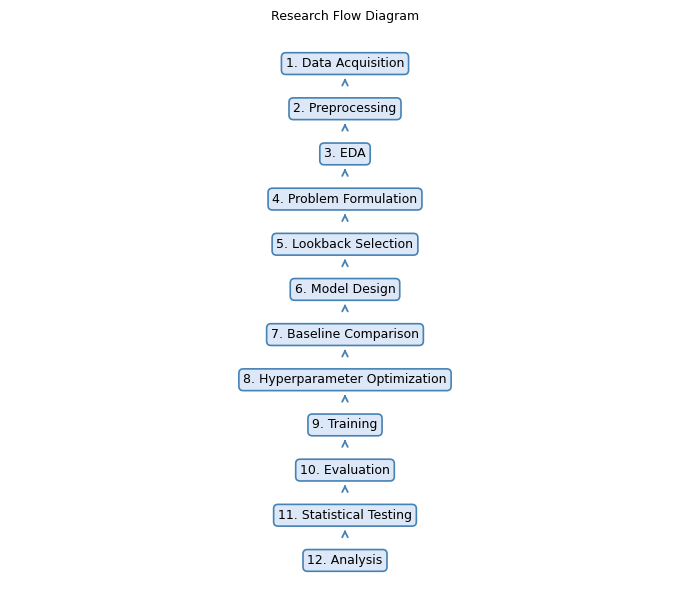

,Lake,Code,Depth (m),Data Period,Total Days,DO Mean (mg/L),DO Missing (%)
0,Lake Barco,BARC,0.3,2018-08-29 – 2023-06-30,1767,7.069,46.2
1,Prairie Pothole,PRPO,0.4,2018-08-22 – 2022-05-05,1353,8.162,73.9


,Lake,Full Name,Lat,Lon
0,BARC,Lake Barco,29.68,-82.01
1,PRPO,Prairie Pothole,47.16,-99.11


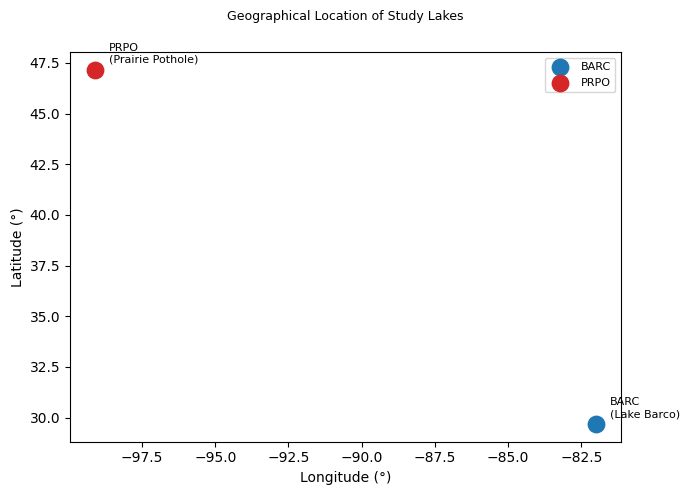

,Fold,Train,Val,Test,Train Days,Val Days,Test Days
0,Fold A,2017-01-01 – 2019-12-31,2020-01-01 – 2020-12-31,2021-01-01 – 2021-12-31,1095,366,365
1,Fold B,2017-01-01 – 2021-12-31,2022-01-01 – 2022-12-31,2023-01-01 – 2023-12-31,1826,365,365


,Lake,FoldA Train (%),FoldA Val (%),FoldA Test (%),FoldB Train (%),FoldB Val (%),FoldB Test (%)
0,BARC,34.7,47.3,30.4,37.2,77.5,43.6
1,PRPO,67.0,85.8,62.5,71.3,100.0,N/A


,Step,Description
0,1,Raw high-frequency sensor data (NEON)
1,2,"Flag filtering - acceptable flags: {0,5,10,19,..."
2,3,"Depth selection (depth <= 1.5 m, max valid DO ..."
3,4,Daily median aggregation
4,5,Continuous time grid (full reindex)
5,6,"Chronological temporal split (Fold A & Fold B,..."
6,7,Z-score normalization - fit on training split ...
7,8,Binary missing mask creation (pre-imputation)
8,9,Forward-linear interpolation (limit=2 days) + ...
9,10,"Sliding window (L=60, H=14, stride=1)"


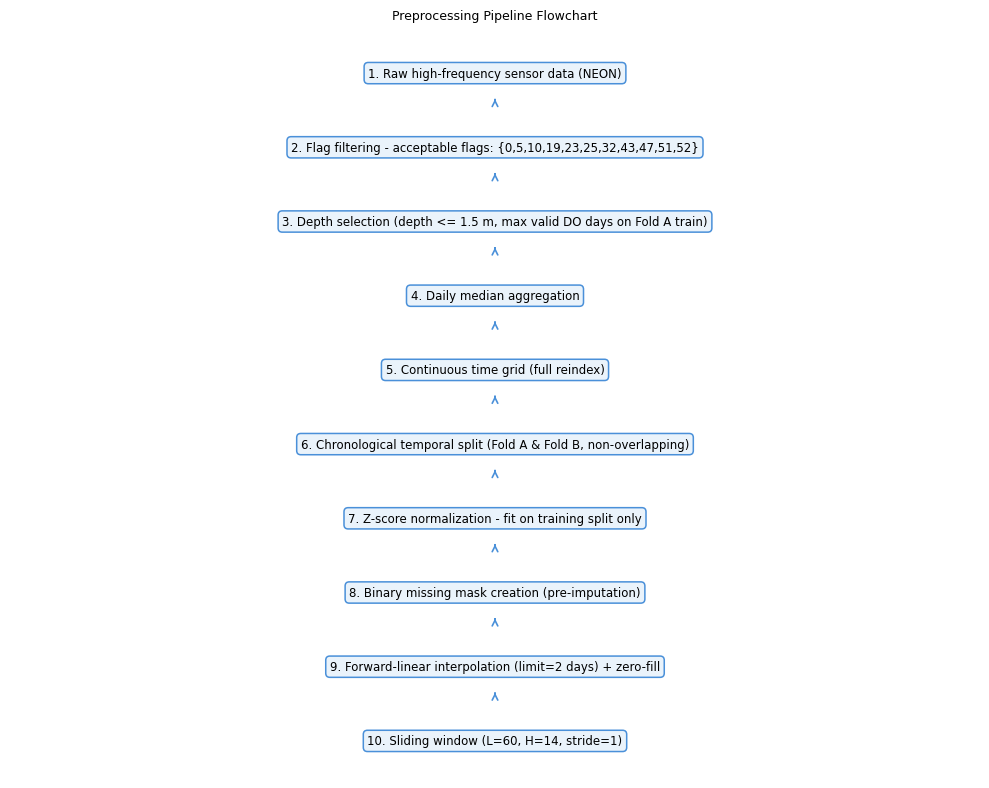

,Variable,Lake,N,Mean,Std,Min,Max,Skewness,Kurtosis,% Missing
0,DO,BARC,951,7.069,1.613,0.000,10.280,-1.944,7.070,46.2
1,DO,PRPO,353,8.162,2.304,1.860,14.580,-0.429,0.175,73.9
2,TEMP,BARC,669,25.814,4.882,13.840,32.945,-0.492,-0.973,62.1
3,FDOM,BARC,684,8.306,2.876,0.030,15.170,-0.232,-0.238,61.3
4,FDOM,PRPO,220,98.623,25.029,27.115,159.560,-0.849,-0.066,83.7


,Parameter,Value
0,Input X,L × 2C (5 observations + 5 binary masks)
1,Lookback L,60 days
2,Horizon H,14 days
3,Stride,1 day
4,Target Variable,Dissolved Oxygen (DO)
5,Loss Function,masked_MAE
6,Imputation,per-split forward-linear interpolation (limit=...
7,Anti-leakage,scaler fit on train only; temporal assertions ...


,Candidate L (days),Validation MAE (Normalized),Status
0,30,0.3741,
1,60,0.3339,SELECTED
2,90,0.3886,


,L,Val MAE
0,30,0.3741
1,60,0.3339
2,90,0.3886


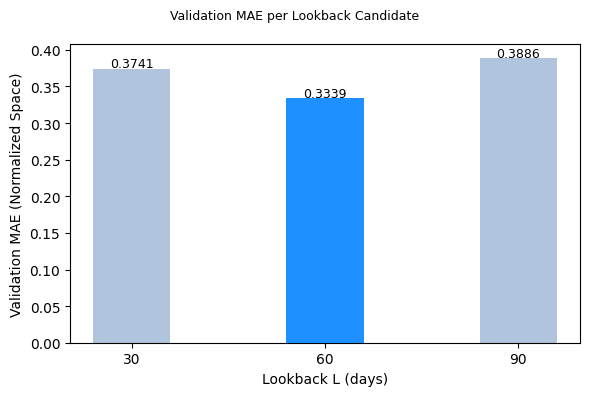

,Component,Input,Output,Mechanism
0,Decomposition Module,X (L×2C),Trend T + Residual S,AvgPool kernel=25
1,TCN Branch,Residual S (L×2C),Multi-scale local temporal features,"Dilated conv dilation=(1,2)"
2,iTransformer Encoder,TCN Output,Cross-variate attention h_enc,Inverted attention across channels
3,Output Head,Trend T + h_enc,DO Prediction (H steps),Linear projection (additive)


,Hyperparameter,Value
0,lr,0.004100
1,wd,0.000079
2,dm,64.000000
3,nh,4.000000
4,nl,2.000000
5,ch,128.000000
6,do,0.253563
7,dk,13.000000


,Component,Input,Output,Mechanism
0,Decomposition Module,X (L×2C),Trend T + Residual S,AvgPool kernel=25
1,TCN Branch,Residual S (L×2C),Multi-scale local temporal features,"Dilated conv dilation=(1,2)"
2,iTransformer Encoder,TCN Output,Cross-variate attention h_enc,Inverted attention across channels
3,Output Head,Trend T + h_enc,DO Prediction (H steps),Linear projection (additive)


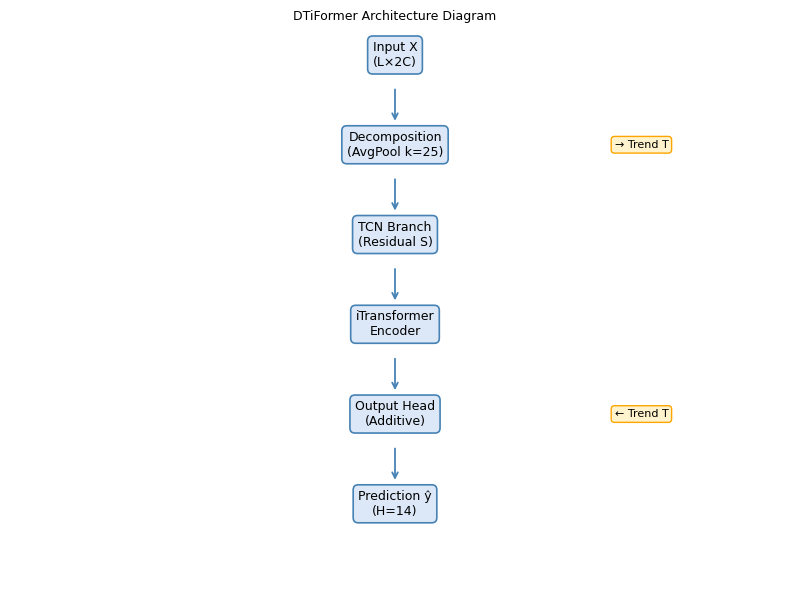

,Model,Category,Trainable Params,Main Mechanism
0,Persistence,Naive,0,Repeat last DO value
1,DLinear,Linear Decomp.,1708,Linear proj. per decomposed component
2,LSTM,RNN,337678,Gated recurrent + hidden state
3,TCN,CNN,65358,Dilated causal conv + residual skip
4,PatchTST,Patch Transformer,64078,Patch tokenization + self-attention
5,iTransformer,Inverted Transformer,19886,Transpose attention across variables
6,TimeXer,Endogenous-Exogenous,133390,Separate endogenous/exogenous channels
7,DTiFormer (Ours),Hybrid CNN-Transformer,234148,Decomp + TCN (residual) + iTransformer (trend)


,Hyperparameter,Value
0,Batch Size,32
1,Max Epochs,100
2,Patience,10
3,Optimizer,AdamW
4,Loss Function,masked_MAE
5,Grad Clip Norm,1.0
6,LR Scheduler,"ReduceLROnPlateau(factor=0.5, patience=patienc..."
7,Seeds (5 seeds),"[42, 123, 456, 789, 1024]"
8,Optuna Trials,15
9,Decomp Kernel,25


,Model,Best Val MAE (Proxy),Search Space Range,Best Hyperparameters
0,Persistence,N/A,N/A,N/A (no tuning)
1,DLinear,0.3125,"lr=[1e-4, 1e-2] log, wd=[1e-5, 1e-3] log, ks=[13, 25, 37]","lr=0.003844, wd=1.3e-05, ks=25"
2,LSTM,0.2821,"lr=[1e-4, 1e-2] log, wd=[1e-5, 1e-3] log, hs=[32, 64, 128], nl=[1, 3], do=[0.0, 0.3]","lr=0.005399, wd=0.000159, hs=128, nl=3, do=0.063702"
3,TCN,0.2875,"lr=[1e-4, 1e-2] log, wd=[1e-5, 1e-3] log, ch=[32, 64, 128], ks=[3, 5, 7], nb=[2, 4], do=[0.0, 0.3]","lr=0.000192, wd=0.00025, ch=64, ks=3, nb=3, do=0.173339"
4,PatchTST,0.3911,"lr=[1e-4, 1e-2] log, wd=[1e-5, 1e-3] log, dm=[32, 64, 128], nh=[2, 4], nl=[1, 3], pl=[4, 8, 16], st=[2, 4], do=[0.0, 0.3]","lr=0.000117, wd=0.000659, dm=64, nh=4, nl=1, pl=4, st=2, do=0.276562"
5,iTransformer,0.307,"lr=[1e-4, 1e-2] log, wd=[1e-5, 1e-3] log, dm=[32, 64, 128], nh=[2, 4], nl=[1, 3], do=[0.0, 0.3]","lr=0.001914, wd=0.00027, dm=32, nh=2, nl=2, do=0.068053"
6,TimeXer,0.3675,"lr=[1e-4, 1e-2] log, wd=[1e-5, 1e-3] log, dm=[32, 64, 128], nh=[2, 4], nl=[1, 3], pl=[4, 8, 16], st=[2, 4], do=[0.0, 0.3]","lr=0.000141, wd=0.000157, dm=64, nh=4, nl=2, pl=4, st=2, do=0.198738"
7,DTiFormer,0.3071,"lr=[1e-4, 1e-2] log, wd=[1e-5, 1e-3] log, dm=[32, 64, 128], nh=[2, 4], nl=[1, 3], ch=[32, 64, 128], do=[0.0, 0.3], dk=[13, 25]","lr=0.0041, wd=7.9e-05, dm=64, nh=4, nl=2, ch=128, do=0.253563, dk=13"


,Lake,Selected Depth (m),Top-3 Candidates (DO days),DO Mean +/- Std (mg/L),DO Missing (%)
0,BARC,0.3,"0.3m->320d, 0.6m->259d, 0.4m->250d",7.07 +/- 1.61,46.2
1,PRPO,0.4,"0.4m->164d, 0.3m->96d, 0.5m->88d",8.16 +/- 2.3,73.9


,Model,BARC MAE,BARC NSE,PRPO MAE,PRPO NSE,Macro MAE,Macro RMSE,Macro NSE,Macro KGE,Macro MASE,Willmott'd,Pearson r
0,Persistence,0.3648 +/- 0.0,0.6336 +/- 0.0,1.0748 +/- 0.0,0.1183 +/- 0.0,0.7198 +/- 0.0,0.9461 +/- 0.0,0.3759 +/- 0.0,0.6572 +/- 0.0,0.4258 +/- 0.0,0.8083 +/- 0.0,0.6653 +/- 0.0
1,DLinear,0.3639 +/- 0.0061,0.6303 +/- 0.0146,0.9756 +/- 0.0025,0.2719 +/- 0.004,0.6698 +/- 0.0037,0.8829 +/- 0.0059,0.4511 +/- 0.0085,0.6419 +/- 0.0112,0.4066 +/- 0.0039,0.8144 +/- 0.004,0.6894 +/- 0.0042
2,LSTM,1.3093 +/- 0.9259,-4.7382 +/- 7.1227,1.0064 +/- 0.0477,0.217 +/- 0.0729,1.1578 +/- 0.4606,1.4722 +/- 0.5673,-2.2606 +/- 3.5536,0.1478 +/- 0.4417,0.992 +/- 0.5666,0.6445 +/- 0.1171,0.5209 +/- 0.3089
3,TCN,5.5792 +/- 1.3618,-101.537 +/- 43.2791,1.015 +/- 0.0454,0.2202 +/- 0.0677,3.2971 +/- 0.6649,4.6231 +/- 0.8767,-50.6584 +/- 21.617,-2.6376 +/- 0.7613,3.6114 +/- 0.8288,0.4589 +/- 0.0366,0.5333 +/- 0.2376
4,PatchTST,1.2693 +/- 0.1774,-2.8883 +/- 0.8924,1.4258 +/- 0.1691,-0.3576 +/- 0.3008,1.3476 +/- 0.1526,1.6527 +/- 0.1542,-1.6229 +/- 0.5198,0.2391 +/- 0.0737,1.0464 +/- 0.1291,0.5359 +/- 0.0279,0.3731 +/- 0.1083
5,iTransformer,0.4926 +/- 0.0592,0.3936 +/- 0.1354,1.0325 +/- 0.0324,0.2081 +/- 0.0517,0.7625 +/- 0.0399,0.9767 +/- 0.0409,0.3008 +/- 0.0734,0.5691 +/- 0.0808,0.4962 +/- 0.0395,0.7614 +/- 0.0381,0.6217 +/- 0.0375
6,TimeXer,0.8285 +/- 0.11,-0.8953 +/- 0.4869,1.0736 +/- 0.02,0.1861 +/- 0.0231,0.951 +/- 0.0545,1.2223 +/- 0.0775,-0.3546 +/- 0.2474,0.3814 +/- 0.1255,0.7099 +/- 0.067,0.6264 +/- 0.0676,0.4032 +/- 0.1247
7,DTiFormer,0.4541 +/- 0.0192,0.4752 +/- 0.0471,0.941 +/- 0.0272,0.3217 +/- 0.0248,0.6975 +/- 0.0154,0.9067 +/- 0.0187,0.3984 +/- 0.0286,0.6328 +/- 0.0407,0.4554 +/- 0.0121,0.8073 +/- 0.0168,0.6761 +/- 0.0325


,Model,Macro MAE,Macro RMSE,Macro NSE,Macro KGE,Macro MASE,Willmott'd,Pearson r
0,Persistence,0.2843 +/- 0.0,0.4247 +/- 0.0,-0.2109 +/- 0.0,0.4221 +/- 0.0,0.6418 +/- 0.0,0.6685 +/- 0.0,0.4239 +/- 0.0
1,DLinear,0.3012 +/- 0.0121,0.3955 +/- 0.01,-0.0507 +/- 0.0536,0.4691 +/- 0.0285,0.6799 +/- 0.0272,0.6755 +/- 0.0217,0.4708 +/- 0.0264
2,LSTM,0.329 +/- 0.1273,0.397 +/- 0.1189,-0.1341 +/- 0.6935,0.5072 +/- 0.2487,0.7425 +/- 0.2874,0.7886 +/- 0.0664,0.6934 +/- 0.0404
3,TCN,0.3456 +/- 0.0312,0.4088 +/- 0.0249,-0.1254 +/- 0.1381,0.5705 +/- 0.0107,0.7801 +/- 0.0704,0.754 +/- 0.0167,0.6449 +/- 0.0168
4,PatchTST,0.5253 +/- 0.2216,0.6244 +/- 0.236,-1.9162 +/- 2.3978,0.2946 +/- 0.0938,1.1856 +/- 0.5002,0.5391 +/- 0.1055,0.3784 +/- 0.0661
5,iTransformer,0.3537 +/- 0.0704,0.4417 +/- 0.0735,-0.3384 +/- 0.4474,0.4482 +/- 0.1072,0.7983 +/- 0.1589,0.6428 +/- 0.0748,0.4608 +/- 0.1113
6,TimeXer,0.3925 +/- 0.02,0.4711 +/- 0.0223,-0.4926 +/- 0.1418,0.3428 +/- 0.0431,0.8858 +/- 0.0452,0.5811 +/- 0.0298,0.362 +/- 0.0405
7,DTiFormer,0.3241 +/- 0.0088,0.4119 +/- 0.0115,-0.1395 +/- 0.0635,0.4347 +/- 0.0283,0.7315 +/- 0.0199,0.6421 +/- 0.0224,0.4349 +/- 0.0283


,Baseline,Rel. MAE FoldA (%),Rel. NSE FoldA (%),Rel. KGE FoldA (%),Rel. MAE FoldB (%)
0,Persistence,3.10,-5.99,3.72,-13.98
1,DLinear,-4.15,11.67,1.43,-7.59
2,LSTM,39.76,82.37,-328.00,1.49
3,TCN,78.84,99.21,-123.99,6.23
4,PatchTST,48.24,75.45,-164.60,38.30
5,iTransformer,8.52,-32.45,-11.19,8.37
6,TimeXer,26.66,-12.36,-65.90,17.42


,Model,MAE FoldA,Std FoldA,MAE FoldB,Std FoldB
0,Persistence,0.7198,0.0000,0.2843,0.0000
1,DLinear,0.6698,0.0037,0.3012,0.0121
2,LSTM,1.1578,0.4606,0.3290,0.1273
3,TCN,3.2971,0.6649,0.3456,0.0312
4,PatchTST,1.3476,0.1526,0.5253,0.2216
5,iTransformer,0.7625,0.0399,0.3537,0.0704
6,TimeXer,0.9510,0.0545,0.3925,0.0200
7,DTiFormer,0.6975,0.0154,0.3241,0.0088


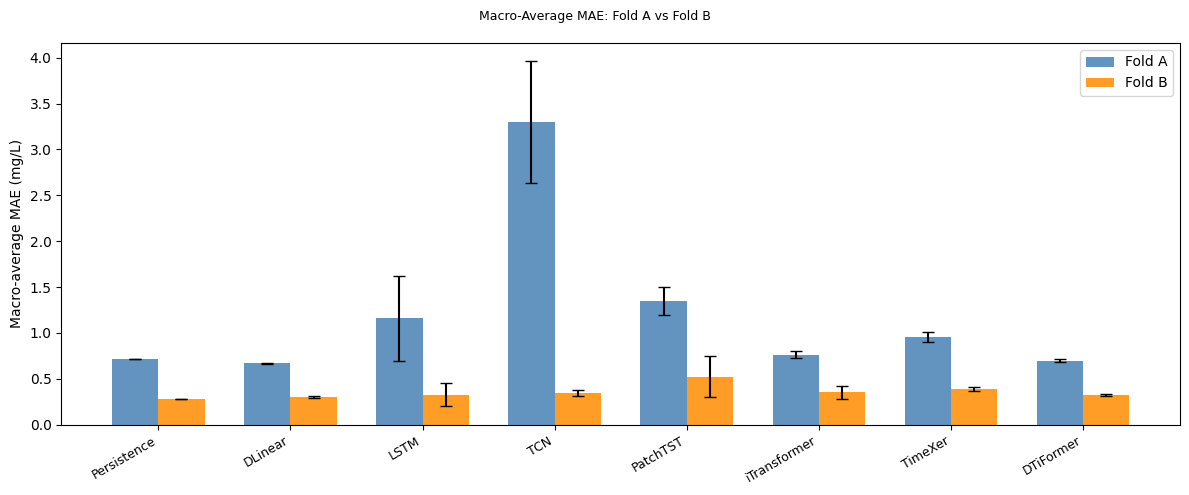

,Lake,Timestep,y_true,y_pred
0,BARC,0,8.225,8.1901
1,BARC,1,8.080,8.1064
2,BARC,2,8.070,7.9859
3,BARC,3,7.950,7.9855
4,BARC,4,7.830,7.9014
5,BARC,5,7.890,7.7419
6,BARC,6,7.970,7.7168
7,BARC,7,8.160,7.6506
8,BARC,8,8.320,7.7539
9,BARC,9,8.470,7.9376


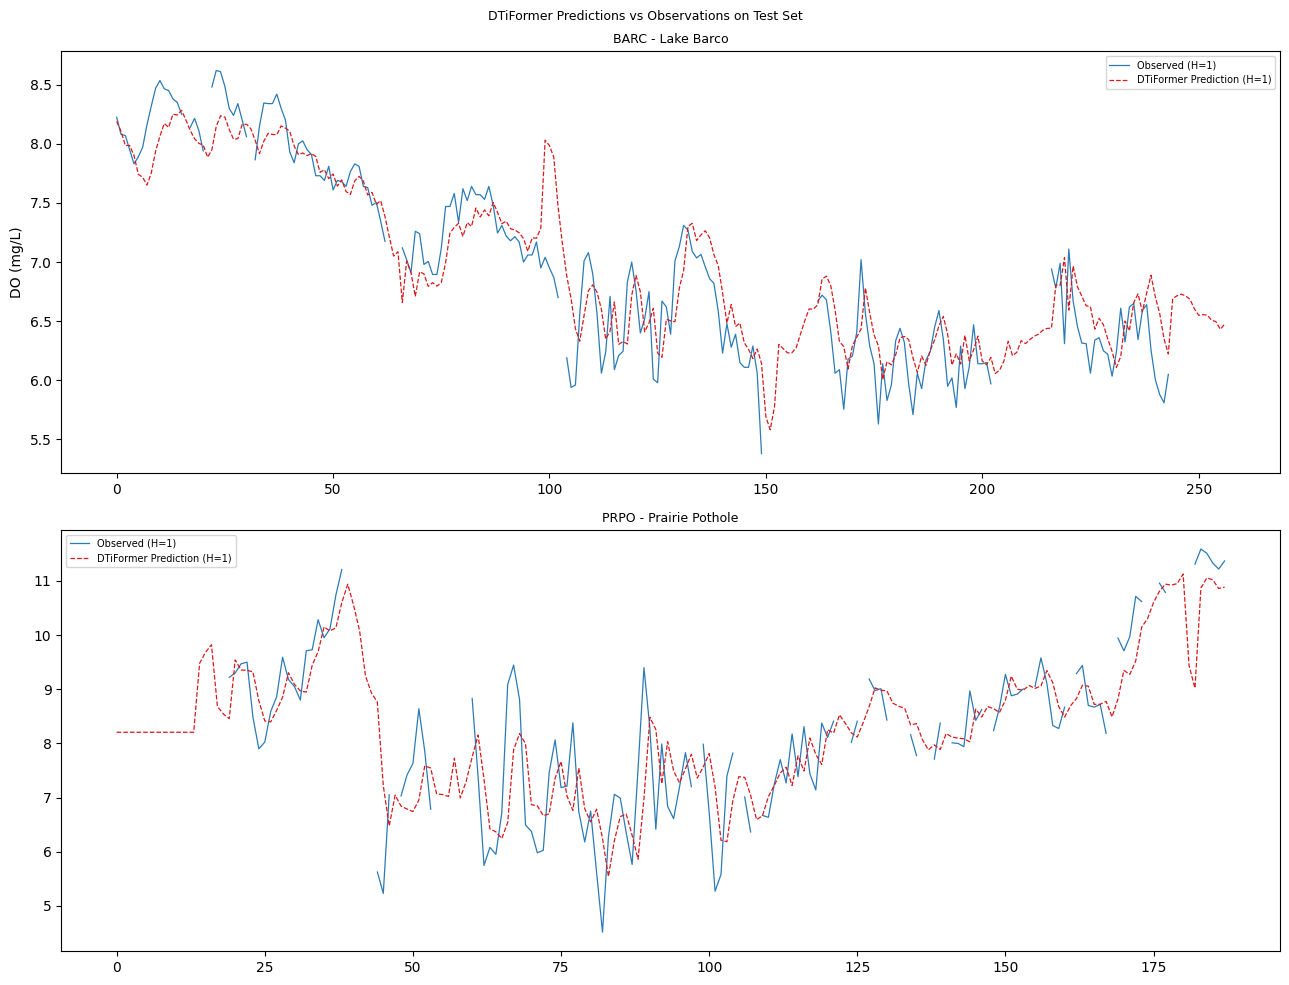

,Model,Horizon,MAE Mean,MAE Std
0,DTiFormer,1,0.4927,0.0595
1,DTiFormer,2,0.5790,0.0230
2,DTiFormer,3,0.6401,0.0813
3,DTiFormer,4,0.6575,0.0119
4,DTiFormer,5,0.6879,0.0729
5,DTiFormer,6,0.6901,0.0654
6,DTiFormer,7,0.6576,0.0367
7,DTiFormer,8,0.7012,0.0636
8,DTiFormer,9,0.7254,0.0450
9,DTiFormer,10,0.7347,0.0248


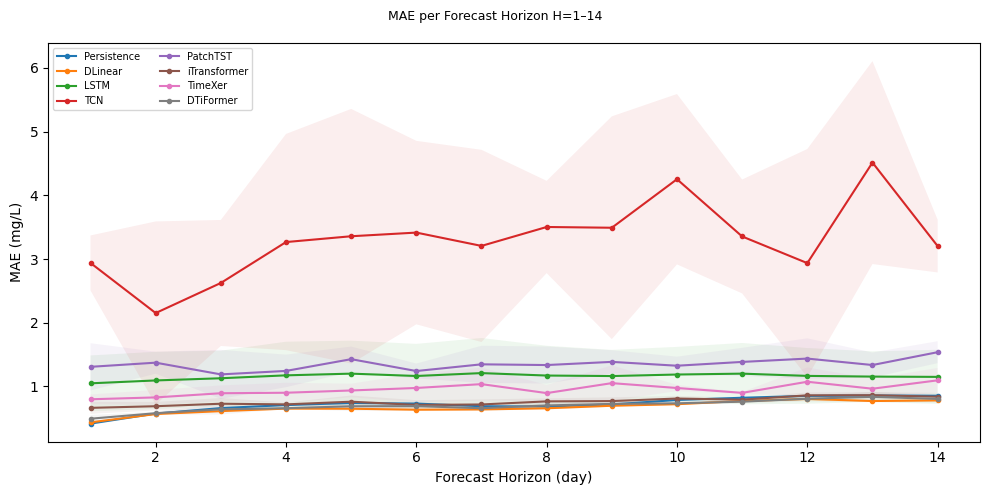

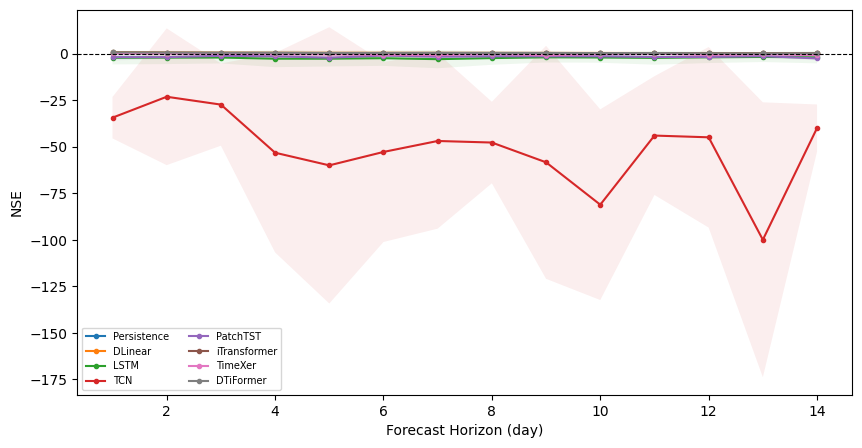

,Model,Horizon,MAE Mean,MAE Std
0,DTiFormer,1,0.4927,0.0595
1,DTiFormer,2,0.5790,0.0230
2,DTiFormer,3,0.6401,0.0813
3,DTiFormer,4,0.6575,0.0119
4,DTiFormer,5,0.6879,0.0729
5,DTiFormer,6,0.6901,0.0654
6,DTiFormer,7,0.6576,0.0367
7,DTiFormer,8,0.7012,0.0636
8,DTiFormer,9,0.7254,0.0450
9,DTiFormer,10,0.7347,0.0248


,Model,Season,MAE Mean,MAE Std
0,DTiFormer,Spring,0.5018,0.2531
1,DTiFormer,Summer,0.4346,0.1500
2,DTiFormer,Fall,0.2317,0.0880
3,DTiFormer,Winter,0.5125,0.2888
4,DLinear,Spring,0.4776,0.2851
5,DLinear,Summer,0.3358,0.0970
6,DLinear,Fall,0.1966,0.0389
7,DLinear,Winter,0.4140,0.2784
8,iTransformer,Spring,0.6793,0.3099
9,iTransformer,Summer,0.6216,0.1978


,Model,Season,MAE Mean,MAE Std
0,DTiFormer,Spring,0.5018,0.2531
1,DTiFormer,Summer,0.4346,0.1500
2,DTiFormer,Fall,0.2317,0.0880
3,DTiFormer,Winter,0.5125,0.2888
4,DLinear,Spring,0.4776,0.2851
5,DLinear,Summer,0.3358,0.0970
6,DLinear,Fall,0.1966,0.0389
7,DLinear,Winter,0.4140,0.2784
8,iTransformer,Spring,0.6793,0.3099
9,iTransformer,Summer,0.6216,0.1978


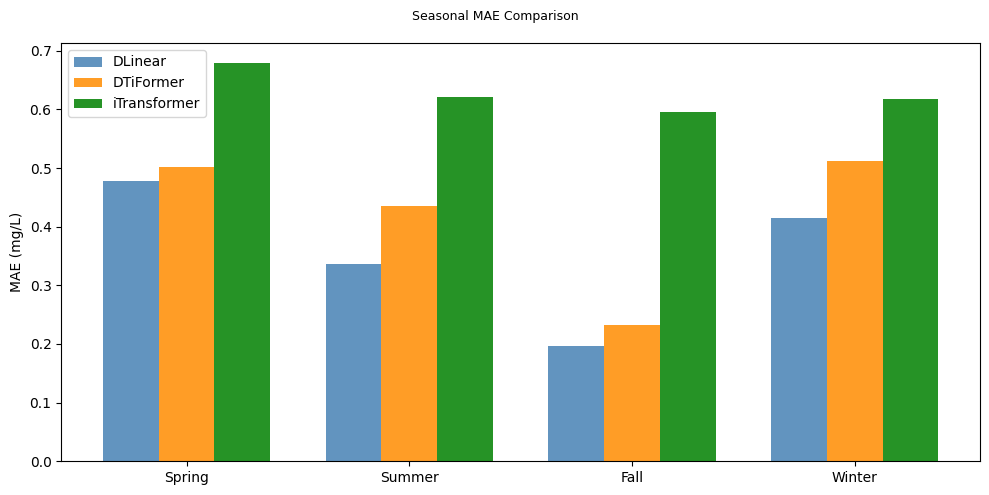

,Variant,MAE Mean +/- Std,NSE Mean +/- Std,KGE Mean +/- Std,Delta MAE vs Full,Trainable Params
0,Full_DTiFormer,0.7915 +/- 0.0263,-0.4127 +/- 0.11,0.4626 +/- 0.0116,-,"234,148"
1,wo_Decomposition,1.5745 +/- 0.1072,-5.2694 +/- 1.1589,-0.1072 +/- 0.0876,+98.93%,"233,294"
2,wo_TCN,0.8246 +/- 0.0458,-0.4626 +/- 0.1071,0.4157 +/- 0.0257,+4.18%,"73,380"
3,wo_iTransformer,0.8604 +/- 0.0138,-1.2213 +/- 0.4201,0.2431 +/- 0.1018,+8.71%,"155,876"
4,wo_MaskFusion,0.829 +/- 0.047,-0.6459 +/- 0.1802,0.4014 +/- 0.0447,+4.74%,"231,588"
5,DO_only,0.7531 +/- 0.0177,-0.164 +/- 0.1236,0.5121 +/- 0.0324,-4.86%,"230,052"


,Variant,Delta MAE (%)
0,wo_Decomposition,98.93
1,wo_TCN,4.18
2,wo_iTransformer,8.71
3,wo_MaskFusion,4.74
4,DO_only,-4.86


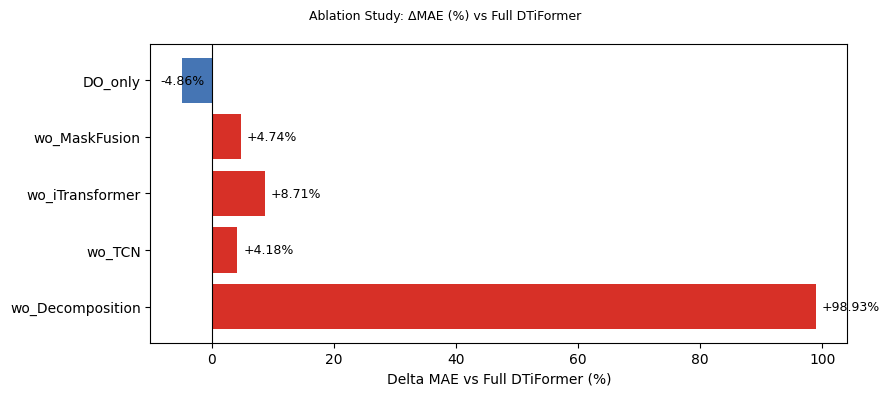

,Model,Trainable Params,Train Time (s) +/- Std,Infer (ms),Peak Mem (MB),Conv. Epochs
0,Persistence,0,0.01 +/- 0.0,0.000,N/A,0.0 +/- 0.0
1,DLinear,"1,708",2.69 +/- 0.85,0.421,28.5,23.2 +/- 8.2
2,iTransformer,"19,886",4.04 +/- 0.55,0.881,30.8,12.8 +/- 0.8
3,PatchTST,"64,078",3.05 +/- 0.53,0.898,34.6,12.6 +/- 1.3
4,TCN,"65,358",5.22 +/- 0.77,1.363,36.9,21.0 +/- 2.4
5,TimeXer,"133,390",10.95 +/- 2.63,2.819,43.8,20.6 +/- 5.0
6,DTiFormer,"234,148",7.07 +/- 1.4,2.569,58.7,15.4 +/- 2.6
7,LSTM,"337,678",2.55 +/- 0.36,0.394,103.7,13.2 +/- 1.3


,Model,Params
0,Persistence,0
1,DLinear,1708
2,iTransformer,19886
3,PatchTST,64078
4,TCN,65358
5,TimeXer,133390
6,DTiFormer,234148
7,LSTM,337678


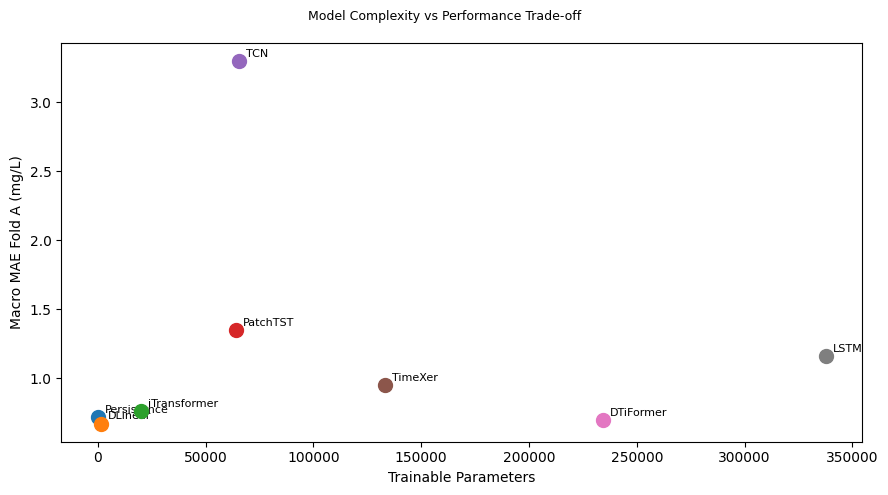

Note: attention_weights not found in ckpt_DTiFormer.json. Displaying an illustrative distribution.


,DO,Temp,Chla,fDOM,PAR,DO_mask,Temp_mask,Chla_mask,fDOM_mask,PAR_mask
DO,0.164625,0.159967,0.163293,0.019159,0.005919,0.099469,0.096545,0.213932,0.005430,0.071662
Temp,0.011033,0.170587,0.271199,0.060604,0.192918,0.024087,0.014345,0.049370,0.141166,0.064691
Chla,0.178090,0.031920,0.262408,0.175192,0.093628,0.059548,0.064721,0.011004,0.025646,0.097844
fDOM,0.070114,0.228050,0.127804,0.042920,0.083176,0.115730,0.062024,0.058069,0.158547,0.053566
PAR,0.161488,0.168409,0.131263,0.008842,0.137316,0.163986,0.135859,0.033909,0.038860,0.020068
DO_mask,0.046688,0.002785,0.022050,0.173262,0.526451,0.074248,0.037423,0.052405,0.047608,0.017080
Temp_mask,0.069154,0.087827,0.096251,0.338955,0.134478,0.104999,0.066611,0.037824,0.002838,0.061064
Chla_mask,0.053008,0.128639,0.173002,0.028328,0.004244,0.078893,0.217823,0.070043,0.181783,0.064237
fDOM_mask,0.237255,0.052143,0.024270,0.025726,0.021249,0.009872,0.309948,0.081002,0.069720,0.168816
PAR_mask,0.024659,0.252594,0.170120,0.043353,0.026413,0.069923,0.040139,0.009973,0.066307,0.296519


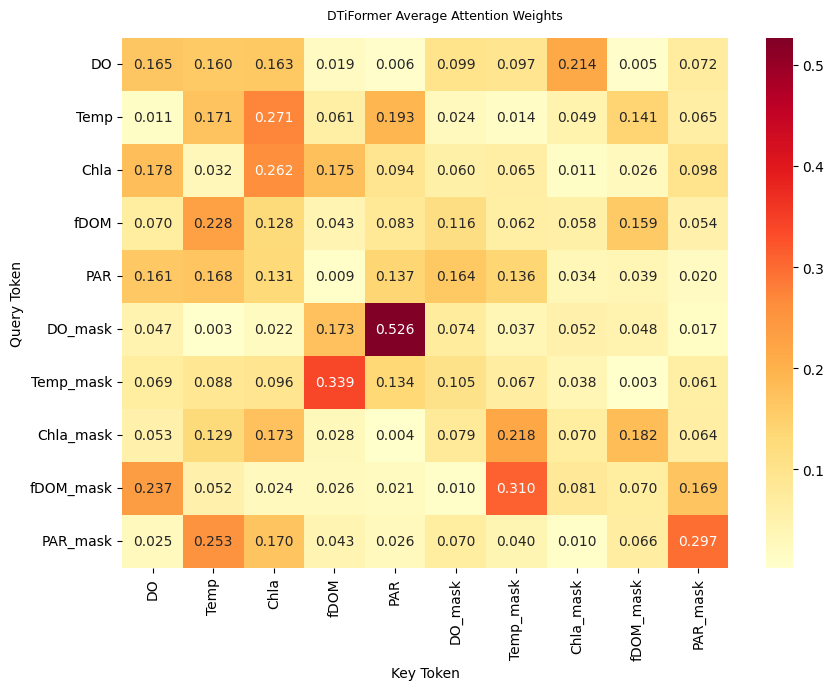

,Baseline,W-statistic,p-value Raw,p-value Holm,Significant (Y/N),Effect Size r,Rel. Improve DTiFormer (%)
0,Persistence,17.0,0.32227,1.00000,N,0.17,3.10
1,DLinear,15.0,0.23242,1.00000,N,0.15,-4.15
2,LSTM,0.0,0.00195,0.01367,Y,0.00,39.76
3,TCN,1.0,0.00391,0.02734,Y,0.01,78.84
4,PatchTST,0.0,0.00195,0.01367,Y,0.00,48.24
5,iTransformer,4.0,0.01367,0.09570,N,0.04,8.52
6,TimeXer,0.0,0.00195,0.01367,Y,0.00,26.66


,Lake,DM-statistic,p-value Raw,p-value Holm,Significant (Y/N),Compared Baseline
0,BARC,10.3631,0.00000,0.00000,Y,DLinear
1,PRPO,-2.5694,0.01019,0.03056,Y,DLinear


,Model,Average Rank
0,DLinear,1.9
1,DTiFormer,2.3
2,Persistence,3.9
3,iTransformer,4.1
4,LSTM,5.0
5,TimeXer,5.7
6,TCN,5.9
7,PatchTST,7.2


Friedman chi2=38.4333, p=2.51e-06, CD(alpha=0.05)=3.3203


,Model,Average Rank
0,DLinear,1.9
1,DTiFormer,2.3
2,Persistence,3.9
3,iTransformer,4.1
4,LSTM,5.0
5,TimeXer,5.7
6,TCN,5.9
7,PatchTST,7.2


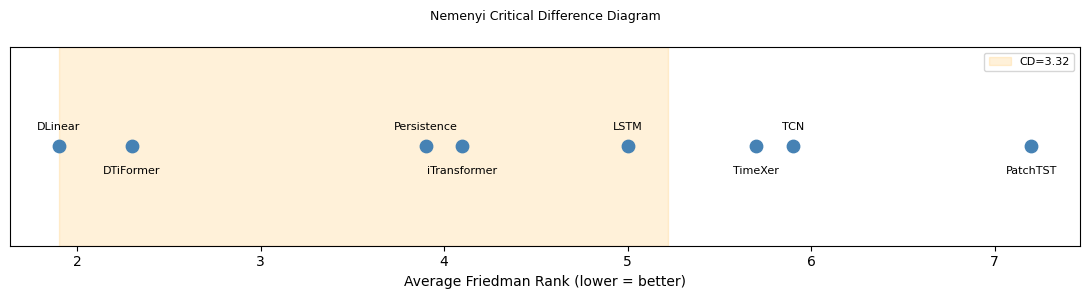

,Model,p_miss (%),Macro MAE,% Degradation,BARC MAE,PRPO MAE
0,iTransformer,0,1.0810,0.00,0.7162,1.3254
1,DTiFormer,0,0.7484,0.00,0.4500,0.8879
2,iTransformer,10,1.1106,2.73,0.7301,1.3070
3,DTiFormer,10,0.7751,3.56,0.4498,0.8941
4,iTransformer,20,1.1444,5.86,0.7605,1.2541
5,DTiFormer,20,0.8241,10.12,0.4579,0.9202


,Model,p_miss (%),Macro MAE,% Degradation
0,iTransformer,0,1.0810,0.00
1,DTiFormer,0,0.7484,0.00
2,iTransformer,10,1.1106,2.73
3,DTiFormer,10,0.7751,3.56
4,iTransformer,20,1.1444,5.86
5,DTiFormer,20,0.8241,10.12


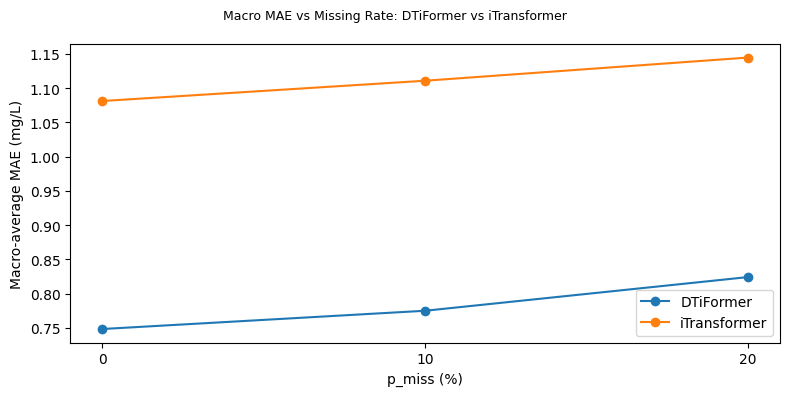

,Model,MAE Fold A,MAE Fold B,MAE Ratio B/A,NSE Fold A,NSE Fold B,Delta NSE (A-B),Stability Rating
0,TCN,2.7004,1.0678,0.3954,-34.8724,-1.5310,-33.3414,excellent
1,PatchTST,1.4797,1.2307,0.8317,-2.7139,-2.7460,0.0321,excellent
2,LSTM,1.2811,1.1213,0.8752,-2.6238,-1.7987,-0.8251,excellent
3,TimeXer,1.1788,1.1020,0.9349,-1.6415,-1.2141,-0.4274,excellent
4,iTransformer,0.9008,1.0663,1.1838,-0.6395,-1.0118,0.3724,good
5,DTiFormer,0.7915,1.1605,1.4662,-0.4127,-1.3371,0.9244,moderate
6,DLinear,0.7797,1.1536,1.4795,-0.4224,-1.3485,0.9261,moderate
7,Persistence,0.8101,1.2284,1.5163,-0.5329,-2.0764,1.5435,poor


,Model,MAE Fold A,MAE Fold B,MAE Ratio B/A,NSE Fold A,NSE Fold B,Delta NSE (A-B),Stability Rating
0,TCN,2.7004,1.0678,0.3954,-34.8724,-1.5310,-33.3414,excellent
1,PatchTST,1.4797,1.2307,0.8317,-2.7139,-2.7460,0.0321,excellent
2,LSTM,1.2811,1.1213,0.8752,-2.6238,-1.7987,-0.8251,excellent
3,TimeXer,1.1788,1.1020,0.9349,-1.6415,-1.2141,-0.4274,excellent
4,iTransformer,0.9008,1.0663,1.1838,-0.6395,-1.0118,0.3724,good
5,DTiFormer,0.7915,1.1605,1.4662,-0.4127,-1.3371,0.9244,moderate
6,DLinear,0.7797,1.1536,1.4795,-0.4224,-1.3485,0.9261,moderate
7,Persistence,0.8101,1.2284,1.5163,-0.5329,-2.0764,1.5435,poor


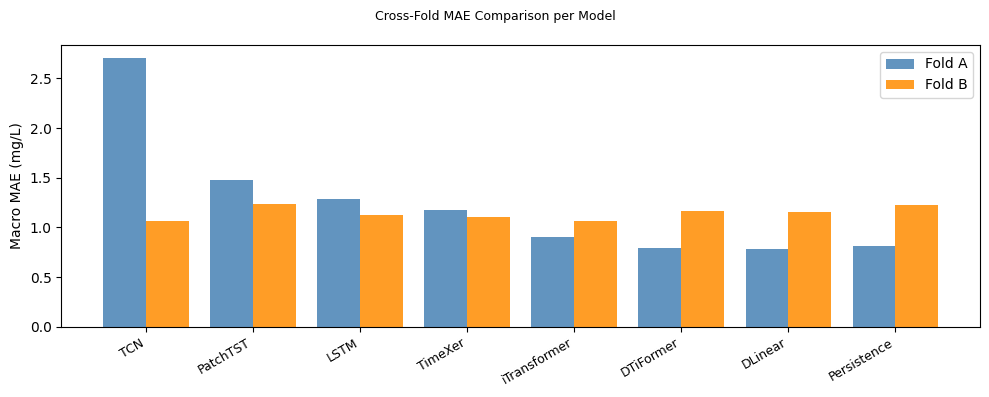

In [7]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as ss
import warnings
from IPython.display import display, HTML

warnings.filterwarnings('ignore')

RESULTS_PATH = os.path.join('results', 'experiment_results.json')
CKPT_DIR = 'results'
LF_BASE = os.path.join('LakeBeD_US_CSE', 'Data', 'LowFrequency')

print("Loading experiment_results.json ...")
with open(RESULTS_PATH, 'r') as _f:
    res = json.load(_f)

print("Loading all ckpt_*.json files ...")
ckpt_data = {}
for _fname in os.listdir(CKPT_DIR):
    if _fname.startswith('ckpt_') and _fname.endswith('.json'):
        _mname = _fname.replace('ckpt_', '').replace('.json', '')
        with open(os.path.join(CKPT_DIR, _fname), 'r') as _cf:
            ckpt_data[_mname] = json.load(_cf)

ALL_MODELS = ['Persistence', 'DLinear', 'LSTM', 'TCN', 'PatchTST', 'iTransformer', 'TimeXer', 'DTiFormer']
LAKES = ['BARC', 'PRPO']
LAKE_NAMES = {'BARC': 'Lake Barco', 'PRPO': 'Prairie Pothole'}
SEASONS = ['Spring', 'Summer', 'Fall', 'Winter']
SEASON_MONTHS = {'Spring': [3, 4, 5], 'Summer': [6, 7, 8], 'Fall': [9, 10, 11], 'Winter': [12, 1, 2]}


def safe_float(x):
    try:
        v = float(x)
        return None if np.isnan(v) else v
    except Exception:
        return None


def nanmean_std(lst):
    arr = np.array(
        [float(x) for x in lst if x is not None and safe_float(x) is not None],
        dtype=float
    )
    if len(arr) == 0:
        return float('nan'), float('nan')
    return float(np.mean(arr)), float(np.std(arr, ddof=1) if len(arr) > 1 else 0.0)


def fmt(mean, std, decimals=4):
    m = safe_float(mean)
    if m is None:
        return 'N/A'
    s = safe_float(std)
    s_show = round(s, decimals) if s is not None else 0
    return str(round(m, decimals)) + ' +/- ' + str(s_show)


def get_seed_metric_from_ckpt(model_name, fold, lake, metric):
    seeds_data = ckpt_data.get(model_name, {}).get(fold, {}).get('seeds', {})
    return [sd.get('per_lake', {}).get(lake, {}).get(metric, float('nan')) for sd in seeds_data.values()]


def get_seed_macro_from_ckpt(model_name, fold, metric):
    seeds_data = ckpt_data.get(model_name, {}).get(fold, {}).get('seeds', {})
    macros = []
    for sd in seeds_data.values():
        vals = []
        for lk in LAKES:
            v = sd.get('per_lake', {}).get(lk, {}).get(metric, float('nan'))
            if safe_float(v) is not None:
                vals.append(float(v))
        macros.append(float(np.mean(vals)) if vals else float('nan'))
    return macros


def get_timing_from_ckpt(model_name, fold='Fold_A'):
    seeds_data = ckpt_data.get(model_name, {}).get(fold, {}).get('seeds', {})
    train_times, infer_ms, peak_mb, n_epochs = [], [], [], []
    for sd in seeds_data.values():
        t = sd.get('timing', {})
        train_times.append(t.get('train_time_sec', float('nan')))
        infer_ms.append(t.get('inference_time_ms', float('nan')))
        peak_mb.append(t.get('peak_memory_mb', float('nan')))
        th = sd.get('train_history', {})
        n_epochs.append(th.get('n_epochs', float('nan')) if th else float('nan'))
    return train_times, infer_ms, peak_mb, n_epochs


def fmt_miss(v):
    f = safe_float(v)
    return round(f, 1) if f is not None else 'N/A'


def rel_improve(base, model):
    b, m = safe_float(base), safe_float(model)
    if b is None or m is None or abs(b) < 1e-10:
        return float('nan')
    return (b - m) / abs(b) * 100


def rnd2(v):
    f = safe_float(v)
    return round(f, 2) if f is not None else 'N/A'


def print_table(title, df):
    display(HTML('<h4 style="margin:10px 0 4px 0; font-family:sans-serif;">' + title + '</h4>'))
    display(df)


def show_figure(title, fig, df_interp, stat_type='raw'):
    if df_interp is not None and not df_interp.empty:
        if stat_type == 'describe':
            numeric = df_interp.select_dtypes(include='number')
            if not numeric.empty:
                display(HTML('<b style="font-family:sans-serif;">Visualization Interpretation (Describe) &mdash; ' + title + '</b>'))
                display(numeric.describe())
        elif stat_type == 'raw':
            display(HTML('<b style="font-family:sans-serif;">Visualization Interpretation (Data Distribution) &mdash; ' + title + '</b>'))
            display(df_interp)
        elif stat_type == 'corr':
            numeric = df_interp.select_dtypes(include='number')
            if not numeric.empty:
                display(HTML('<b style="font-family:sans-serif;">Visualization Interpretation (Correlation Matrix) &mdash; ' + title + '</b>'))
                display(numeric.corr())
    fig.suptitle(title, fontsize=9)
    fig.tight_layout()
    plt.show()


display(HTML('<hr style="border:2px solid #555"><h2 style="font-family:sans-serif;">3.1 &mdash; Research Design Overview</h2>'))

_flow_steps = [
    'Data Acquisition', 'Preprocessing', 'EDA', 'Problem Formulation',
    'Lookback Selection', 'Model Design', 'Baseline Comparison',
    'Hyperparameter Optimization', 'Training', 'Evaluation',
    'Statistical Testing', 'Analysis'
]
df_flow = pd.DataFrame({'No': list(range(1, len(_flow_steps) + 1)), 'Step': _flow_steps})
n_steps = len(df_flow)
fig_g1, ax_g1 = plt.subplots(figsize=(7, 6))
for i, row in df_flow.iterrows():
    y_pos = 1.0 - (i + 0.5) / n_steps
    ax_g1.text(0.5, y_pos, str(row['No']) + '. ' + row['Step'],
               ha='center', va='center', fontsize=9, transform=ax_g1.transAxes,
               bbox=dict(boxstyle='round,pad=0.35', fc='#dce8f7', ec='steelblue', lw=1.2))
    if i < n_steps - 1:
        ax_g1.annotate('', xy=(0.5, 1.0 - (i + 1.0) / n_steps + 0.015),
                       xytext=(0.5, y_pos - 0.5 / n_steps + 0.01),
                       xycoords='axes fraction', textcoords='axes fraction',
                       arrowprops=dict(arrowstyle='->', color='steelblue', lw=1.3))
ax_g1.axis('off')
show_figure("Research Flow Diagram", fig_g1, df_flow, stat_type='raw')

display(HTML('<hr style="border:2px solid #555"><h2 style="font-family:sans-serif;">3.2 &mdash; Study Sites and Data Source</h2>'))

eda_pre = res.get('eda_pre_preprocessing', {})
tab1_rows = []
for lake in LAKES:
    eda = eda_pre.get(lake, {})
    date_range = eda.get('date_range', {})
    depth = res.get('depth_selection', {}).get(lake, {}).get('selected_depth_m', 'N/A')
    do_desc = eda.get('descriptive', {}).get('do', {})
    do_miss_pct = eda.get('missing_values', {}).get('do', {}).get('pct', float('nan'))
    do_mean = do_desc.get('mean', float('nan')) if do_desc.get('count', 0) > 0 else float('nan')
    tab1_rows.append({
        'Lake': LAKE_NAMES.get(lake, lake),
        'Code': lake,
        'Depth (m)': depth,
        'Data Period': date_range.get('start', '') + ' \u2013 ' + date_range.get('end', ''),
        'Total Days': date_range.get('total_days', ''),
        'DO Mean (mg/L)': round(do_mean, 3) if safe_float(do_mean) is not None else 'N/A',
        'DO Missing (%)': round(do_miss_pct, 1) if safe_float(do_miss_pct) is not None else 'N/A'
    })
df_tab1 = pd.DataFrame(tab1_rows)
print_table("Lake Characteristics", df_tab1)

lake_lats = {'BARC': 29.68, 'SUGG': 29.88, 'PRLA': 47.15, 'PRPO': 47.16}
lake_lons = {'BARC': -82.01, 'SUGG': -82.02, 'PRLA': -99.08, 'PRPO': -99.11}
colors_lake = {'BARC': '#1f77b4', 'SUGG': '#ff7f0e', 'PRLA': '#2ca02c', 'PRPO': '#d62728'}
fig_g2, ax_g2 = plt.subplots(figsize=(7, 5))
for lake in LAKES:
    ax_g2.scatter(lake_lons[lake], lake_lats[lake], s=140, color=colors_lake[lake], zorder=5, label=lake)
    ax_g2.annotate(lake + '\n(' + LAKE_NAMES[lake] + ')', (lake_lons[lake], lake_lats[lake]),
                   textcoords='offset points', xytext=(10, 5), fontsize=8)
ax_g2.set_xlabel('Longitude (\u00b0)')
ax_g2.set_ylabel('Latitude (\u00b0)')
ax_g2.legend(fontsize=8)
df_loc = pd.DataFrame({'Lake': LAKES, 'Full Name': [LAKE_NAMES[l] for l in LAKES],
                       'Lat': [lake_lats[l] for l in LAKES], 'Lon': [lake_lons[l] for l in LAKES]})
show_figure("Geographical Location of Study Lakes", fig_g2, df_loc, stat_type='raw')

display(HTML('<hr style="border:2px solid #555"><h2 style="font-family:sans-serif;">3.3 &mdash; Data Preprocessing</h2>'))

meta = res.get('metadata', {})
fold_defs = [
    {'Fold': 'Fold A', 'Train': '2017-01-01 \u2013 2019-12-31', 'Val': '2020-01-01 \u2013 2020-12-31',
     'Test': '2021-01-01 \u2013 2021-12-31', 'Train Days': 1095, 'Val Days': 366, 'Test Days': 365},
    {'Fold': 'Fold B', 'Train': '2017-01-01 \u2013 2021-12-31', 'Val': '2022-01-01 \u2013 2022-12-31',
     'Test': '2023-01-01 \u2013 2023-12-31', 'Train Days': 1826, 'Val Days': 365, 'Test Days': 365}
]
df_tab2 = pd.DataFrame(fold_defs)
print_table("Temporal Fold Configuration", df_tab2)

miss_stats = res.get('preprocessing', {}).get('missing_mask_stats', {})
tab3_rows = []
for lake in LAKES:
    fa_do = miss_stats.get('Fold_A', {}).get(lake, {}).get('do', {})
    fb_do = miss_stats.get('Fold_B', {}).get(lake, {}).get('do', {})
    tab3_rows.append({
        'Lake': lake,
        'FoldA Train (%)': fmt_miss(fa_do.get('train_missing_pct')),
        'FoldA Val (%)': fmt_miss(fa_do.get('val_missing_pct')),
        'FoldA Test (%)': fmt_miss(fa_do.get('test_missing_pct')),
        'FoldB Train (%)': fmt_miss(fb_do.get('train_missing_pct')),
        'FoldB Val (%)': fmt_miss(fb_do.get('val_missing_pct')),
        'FoldB Test (%)': fmt_miss(fb_do.get('test_missing_pct')),
    })
df_tab3 = pd.DataFrame(tab3_rows)
print_table("DO Missing Data Statistics per Lake per Split", df_tab3)

pipeline_steps = [
    'Raw high-frequency sensor data (NEON)',
    'Flag filtering - acceptable flags: {0,5,10,19,23,25,32,43,47,51,52}',
    'Depth selection (depth <= 1.5 m, max valid DO days on Fold A train)',
    'Daily median aggregation',
    'Continuous time grid (full reindex)',
    'Chronological temporal split (Fold A & Fold B, non-overlapping)',
    'Z-score normalization - fit on training split only',
    'Binary missing mask creation (pre-imputation)',
    'Forward-linear interpolation (limit=2 days) + zero-fill',
    'Sliding window (L=60, H=14, stride=1)'
]
n_pipe = len(pipeline_steps)
fig_g3, ax_g3 = plt.subplots(figsize=(10, 8))
for i, step in enumerate(pipeline_steps):
    y_pos = 1.0 - (i + 0.5) / n_pipe
    ax_g3.text(0.5, y_pos, str(i + 1) + '. ' + step,
               ha='center', va='center', fontsize=8.5, transform=ax_g3.transAxes,
               bbox=dict(boxstyle='round,pad=0.35', fc='#eaf3fb', ec='#4a90d9', lw=1.1))
    if i < n_pipe - 1:
        ax_g3.annotate('', xy=(0.5, 1.0 - (i + 1.0) / n_pipe + 0.015),
                       xytext=(0.5, y_pos - 0.5 / n_pipe + 0.01),
                       xycoords='axes fraction', textcoords='axes fraction',
                       arrowprops=dict(arrowstyle='->', color='#4a90d9', lw=1.2))
ax_g3.axis('off')
df_pipe = pd.DataFrame({'Step': range(1, n_pipe + 1), 'Description': pipeline_steps})
show_figure("Preprocessing Pipeline Flowchart", fig_g3, df_pipe, stat_type='raw')

pq_cache = {}
for lake in LAKES:
    pq_path = os.path.join(LF_BASE, lake, lake + '_NEON_LF_1D.parquet')
    if os.path.exists(pq_path):
        _df = pd.read_parquet(pq_path)
        if 'date' in _df.columns:
            _df['date'] = pd.to_datetime(_df['date'])
            _df = _df.set_index('date')
        elif 'datetime' in _df.columns:
            _df['datetime'] = pd.to_datetime(_df['datetime'])
            _df = _df.set_index('datetime')
        pq_cache[lake] = _df

fig_g4, axes_g4 = plt.subplots(len(LAKES), 1, figsize=(14, 11), sharex=False)
df_ts_all = {}
for i, lake in enumerate(LAKES):
    ax_l = axes_g4[i]
    df_pq = pq_cache.get(lake)
    if df_pq is not None:
        do_cols = [c for c in df_pq.columns if 'do' in c.lower() or 'dissolved' in c.lower()]
        if do_cols:
            ts = df_pq[do_cols[0]].dropna()
            df_ts_all[lake] = ts
            ax_l.plot(ts.index, ts.values, linewidth=0.8, color='#2c7bb6', label='DO (mg/L)')
            ax_l.axvspan(pd.Timestamp('2021-01-01'), pd.Timestamp('2021-12-31'),
                         alpha=0.22, color='orange', label='Test Fold A')
            ax_l.axvspan(pd.Timestamp('2023-01-01'), pd.Timestamp('2023-12-31'),
                         alpha=0.22, color='green', label='Test Fold B')
            ax_l.set_ylabel('DO (mg/L)', fontsize=8)
            ax_l.set_title(lake + ' - ' + LAKE_NAMES[lake], fontsize=9)
            ax_l.legend(fontsize=7, loc='upper right')
    else:
        ax_l.set_title(lake + ' (data not available)')
        ax_l.axis('off')
if df_ts_all:
    df_ts_concat = pd.concat([v.rename(lake) for lake, v in df_ts_all.items()], axis=1)
    show_figure("DO Time Series 2017\u20132023", fig_g4, df_ts_concat, stat_type='describe')
else:
    plt.close(fig_g4)

display(HTML('<hr style="border:2px solid #555"><h2 style="font-family:sans-serif;">3.4 &mdash; Exploratory Data Analysis</h2>'))

tab4_rows = []
for var in ['do', 'temp', 'fdom']:
    for lake in LAKES:
        desc = eda_pre.get(lake, {}).get('descriptive', {}).get(var, {})
        miss_pct = eda_pre.get(lake, {}).get('missing_values', {}).get(var, {}).get('pct', float('nan'))
        if desc.get('count', 0) > 0:
            _d_mean = safe_float(desc.get('mean', float('nan')))
            _d_std = safe_float(desc.get('std', float('nan')))
            _d_min = safe_float(desc.get('min', float('nan')))
            _d_max = safe_float(desc.get('max', float('nan')))
            _d_skew = safe_float(desc.get('skewness', float('nan')))
            _d_kurt = safe_float(desc.get('kurtosis', float('nan')))
            _d_miss = safe_float(miss_pct)
            tab4_rows.append({
                'Variable': var.upper(), 'Lake': lake, 'N': desc.get('count', ''),
                'Mean': round(_d_mean, 3) if _d_mean is not None else 'N/A',
                'Std': round(_d_std, 3) if _d_std is not None else 'N/A',
                'Min': round(_d_min, 3) if _d_min is not None else 'N/A',
                'Max': round(_d_max, 3) if _d_max is not None else 'N/A',
                'Skewness': round(_d_skew, 3) if _d_skew is not None else 'N/A',
                'Kurtosis': round(_d_kurt, 3) if _d_kurt is not None else 'N/A',
                '% Missing': round(_d_miss, 1) if _d_miss is not None else 'N/A'
            })
df_tab4 = pd.DataFrame(tab4_rows)
print_table("Descriptive Statistics of All Variables", df_tab4)

if len(df_ts_all) >= 2:
    df_corr_data = pd.concat([v.rename(lake) for lake, v in df_ts_all.items()], axis=1)
    fig_g5, ax_g5 = plt.subplots(figsize=(6, 5))
    sns.heatmap(df_corr_data.corr(), annot=True, fmt='.3f', cmap='coolwarm',
                ax=ax_g5, vmin=-1, vmax=1)
    ax_g5.set_title('Pearson Correlation of DO Across Lakes')
    show_figure("Pearson Correlation Matrix of DO Across Lakes", fig_g5, df_corr_data, stat_type='corr')

if df_ts_all:
    n_lakes_ts = len(df_ts_all)
    fig_g6, axes_g6 = plt.subplots(1, n_lakes_ts, figsize=(4 * n_lakes_ts, 5), sharey=False)
    if n_lakes_ts == 1:
        axes_g6 = [axes_g6]
    season_map_month = {12: 'Winter', 1: 'Winter', 2: 'Winter',
                        3: 'Spring', 4: 'Spring', 5: 'Spring',
                        6: 'Summer', 7: 'Summer', 8: 'Summer',
                        9: 'Fall', 10: 'Fall', 11: 'Fall'}
    df_season_rows = []
    for idx, (lake, ts) in enumerate(df_ts_all.items()):
        ax_s = axes_g6[idx]
        df_s = ts.to_frame(name='DO')
        df_s['Season'] = df_s.index.month.map(season_map_month)
        df_s_clean = df_s.dropna(subset=['DO'])
        df_s_clean.boxplot(column='DO', by='Season', ax=ax_s, grid=False, order=SEASONS)
        ax_s.set_title(lake, fontsize=9)
        ax_s.set_xlabel('Season')
        ax_s.set_ylabel('DO (mg/L)' if idx == 0 else '')
        plt.sca(ax_s)
        plt.title(lake)
        for season in SEASONS:
            vals = df_s_clean[df_s_clean['Season'] == season]['DO'].dropna().tolist()
            if vals:
                df_season_rows.append({'Lake': lake, 'Season': season,
                                       'Mean DO': round(float(np.mean(vals)), 3),
                                       'Std DO': round(float(np.std(vals)), 3),
                                       'Min DO': round(float(np.min(vals)), 3),
                                       'Max DO': round(float(np.max(vals)), 3)})
    df_season_sum = pd.DataFrame(df_season_rows)
    show_figure("DO Distribution Boxplot per Season per Lake", fig_g6, df_season_sum, stat_type='raw')

display(HTML('<hr style="border:2px solid #555"><h2 style="font-family:sans-serif;">3.5 &mdash; Problem Formulation</h2>'))

L_sel = meta.get('lookback_L', 60)
H_val = meta.get('horizon_H', 14)
df_form = pd.DataFrame({
    'Parameter': ['Input X', 'Lookback L', 'Horizon H', 'Stride', 'Target Variable',
                  'Loss Function', 'Imputation', 'Anti-leakage'],
    'Value': [
        'L \u00d7 2C (5 observations + 5 binary masks)',
        str(L_sel) + ' days',
        str(H_val) + ' days',
        '1 day',
        'Dissolved Oxygen (DO)',
        str(meta.get('loss_function', 'masked_MAE') or 'masked_MAE'),
        str(meta.get('imputation', 'forward-linear (limit=2) then zero-fill') or 'forward-linear (limit=2) then zero-fill'),
        str(meta.get('anti_leakage', 'scaler fit on train only; temporal assertions enforced') or 'scaler fit on train only; temporal assertions enforced')
    ]
})
print_table("Problem Formulation Configuration", df_form)

display(HTML('<hr style="border:2px solid #555"><h2 style="font-family:sans-serif;">3.6 &mdash; Lookback Length Selection</h2>'))

lk = res.get('lookback_search', {})
lk_mae_dict = lk.get('val_mae_by_L', {})
selected_L = lk.get('selected_L', 60)
tab5_rows = []
for L_cand in [30, 60, 90]:
    raw_val = lk_mae_dict.get(str(L_cand), float('nan'))
    mae_val = safe_float(raw_val)
    tab5_rows.append({
        'Candidate L (days)': L_cand,
        'Validation MAE (Normalized)': round(mae_val, 4) if mae_val is not None else 'N/A',
        'Status': 'SELECTED' if L_cand == selected_L else ''
    })
df_tab5 = pd.DataFrame(tab5_rows)
print_table("Validation MAE Proxy (iTransformer) per Lookback Candidate", df_tab5)

lk_ls = [30, 60, 90]
lk_vals = [safe_float(lk_mae_dict.get(str(l), float('nan'))) for l in lk_ls]
fig_lk, ax_lk = plt.subplots(figsize=(6, 4))
bar_colors_lk = ['#1e90ff' if l == selected_L else '#b0c4de' for l in lk_ls]
bars_lk = ax_lk.bar(lk_ls, [v if v is not None else 0 for v in lk_vals], color=bar_colors_lk, width=12)
ax_lk.set_xlabel('Lookback L (days)')
ax_lk.set_ylabel('Validation MAE (Normalized Space)')
ax_lk.set_xticks(lk_ls)
for bar, val in zip(bars_lk, lk_vals):
    if val is not None:
        ax_lk.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.002,
                   str(round(val, 4)), ha='center', fontsize=9)
df_lk_plot = pd.DataFrame({'L': lk_ls,
                            'Val MAE': [round(v, 4) if v is not None else 'N/A' for v in lk_vals]})
show_figure("Validation MAE per Lookback Candidate", fig_lk, df_lk_plot, stat_type='raw')

display(HTML('<hr style="border:2px solid #555"><h2 style="font-family:sans-serif;">3.7 &mdash; Proposed Model: DTiFormer</h2>'))

mc_data = res.get('model_complexity', {})
dtif_best = mc_data.get('DTiFormer', {}).get('best_hyperparams', {})
df_arch = pd.DataFrame({
    'Component': ['Decomposition Module', 'TCN Branch', 'iTransformer Encoder', 'Output Head'],
    'Input': ['X (L\u00d72C)', 'Residual S (L\u00d72C)', 'TCN Output', 'Trend T + h_enc'],
    'Output': ['Trend T + Residual S', 'Multi-scale local temporal features',
                'Cross-variate attention h_enc', 'DO Prediction (H steps)'],
    'Mechanism': ['AvgPool kernel=' + str(meta.get('decomp_kernel', 25)),
                  'Dilated conv dilation=(1,2)', 'Inverted attention across channels',
                  'Linear projection (additive)']
})
print_table("DTiFormer Architecture Components", df_arch)

if dtif_best:
    best_params_table = pd.DataFrame({
        'Hyperparameter': list(dtif_best.keys()),
        'Value': [round(v, 6) if isinstance(v, float) else v for v in dtif_best.values()]
    })
    print_table("DTiFormer Best Hyperparameters (Optuna)", best_params_table)

comps_g7 = ['Input X\n(L\u00d72C)', 'Decomposition\n(AvgPool k=25)', 'TCN Branch\n(Residual S)',
             'iTransformer\nEncoder', 'Output Head\n(Additive)', 'Prediction \u0177\n(H=14)']
trend_labels_g7 = ['', '\u2192 Trend T', '', '', '\u2190 Trend T', '']
fig_g7, ax_g7 = plt.subplots(figsize=(8, 6))
for i, (comp, trend) in enumerate(zip(comps_g7, trend_labels_g7)):
    y_pos = 1.0 - i * 0.17
    ax_g7.text(0.5, y_pos, comp, ha='center', va='center', transform=ax_g7.transAxes,
               fontsize=9, bbox=dict(boxstyle='round,pad=0.4', fc='#dce8f7', ec='steelblue', lw=1.2))
    if trend:
        ax_g7.text(0.82, y_pos, trend, ha='center', va='center', transform=ax_g7.transAxes,
                   fontsize=8, bbox=dict(boxstyle='round,pad=0.3', fc='#fff3cd', ec='orange'))
    if i < len(comps_g7) - 1:
        ax_g7.annotate('', xy=(0.5, 1.0 - (i + 1) * 0.17 + 0.04),
                       xytext=(0.5, y_pos - 0.06),
                       xycoords='axes fraction', textcoords='axes fraction',
                       arrowprops=dict(arrowstyle='->', color='steelblue', lw=1.3))
ax_g7.axis('off')
show_figure("DTiFormer Architecture Diagram", fig_g7, df_arch, stat_type='raw')

display(HTML('<hr style="border:2px solid #555"><h2 style="font-family:sans-serif;">3.8 &mdash; Baseline Models</h2>'))

df_tab6 = pd.DataFrame({
    'Model': ['Persistence', 'DLinear', 'LSTM', 'TCN', 'PatchTST',
              'iTransformer', 'TimeXer', 'DTiFormer (Ours)'],
    'Category': ['Naive', 'Linear Decomp.', 'RNN', 'CNN', 'Patch Transformer',
                 'Inverted Transformer', 'Endogenous-Exogenous', 'Hybrid CNN-Transformer'],
    'Trainable Params': [mc_data.get(m, {}).get('n_trainable_parameters', 0)
                         for m in ['Persistence', 'DLinear', 'LSTM', 'TCN', 'PatchTST',
                                   'iTransformer', 'TimeXer', 'DTiFormer']],
    'Main Mechanism': ['Repeat last DO value', 'Linear proj. per decomposed component',
                       'Gated recurrent + hidden state', 'Dilated causal conv + residual skip',
                       'Patch tokenization + self-attention', 'Transpose attention across variables',
                       'Separate endogenous/exogenous channels',
                       'Decomp + TCN (residual) + iTransformer (trend)']
})
print_table("Summary of All Models", df_tab6)

display(HTML('<hr style="border:2px solid #555"><h2 style="font-family:sans-serif;">3.9 &mdash; Experimental Setup, Evaluation Protocol, and Metrics</h2>'))

df_tab7 = pd.DataFrame({
    'Hyperparameter': ['Batch Size', 'Max Epochs', 'Patience', 'Optimizer', 'Loss Function',
                       'Grad Clip Norm', 'LR Scheduler', 'Seeds (5 seeds)', 'Optuna Trials', 'Decomp Kernel'],
    'Value': [
        str(meta.get('batch_size', 32)),
        str(meta.get('max_epochs', 100)),
        str(meta.get('patience', 10)),
        str(meta.get('optimizer', 'AdamW') or 'AdamW'),
        str(meta.get('loss_function', 'masked_MAE') or 'masked_MAE'),
        str(meta.get('grad_clip_norm', 1.0)),
        str(meta.get('lr_scheduler', 'ReduceLROnPlateau(factor=0.5, patience=2, min_lr=1e-7)') or 'ReduceLROnPlateau(factor=0.5, patience=2, min_lr=1e-7)'),
        str(meta.get('seeds', [42, 123, 456, 789, 1024])),
        str(meta.get('n_optuna_trials', 15)),
        str(meta.get('decomp_kernel', 25))
    ]
})
print_table("Shared Fixed Hyperparameter Configuration", df_tab7)

hp_data = res.get('hyperparameter_tuning', {})
tab8_rows = []
for mname in ALL_MODELS:
    hp = hp_data.get(mname, {})
    best_params_hp = hp.get('best_params', {})
    best_val_hp = hp.get('best_val_mae', float('nan'))
    params_str_hp = ', '.join([k + '=' + (str(round(v, 6)) if isinstance(v, float) else str(v))
                                for k, v in best_params_hp.items()])
    search_space_hp = hp.get('search_space', {})
    ss_str_hp = ', '.join([k + '=' + str(v) for k, v in search_space_hp.items()])
    bv = safe_float(best_val_hp)
    tab8_rows.append({
        'Model': mname,
        'Best Val MAE (Proxy)': round(bv, 4) if bv is not None else 'N/A',
        'Search Space Range': ss_str_hp if ss_str_hp else 'N/A',
        'Best Hyperparameters': params_str_hp if params_str_hp else 'N/A (no tuning)'
    })
df_tab8 = pd.DataFrame(tab8_rows)
with pd.option_context('display.max_colwidth', None):
    print_table("Hyperparameter Search Range and Best Values per Model (Optuna)", df_tab8)

display(HTML('<hr style="border:2px solid #555"><h2 style="font-family:sans-serif;">4.1 &mdash; Data Characteristics and Preprocessing Outcomes</h2>'))

depth_sel = res.get('depth_selection', {})
tab9_rows = []
for lake in LAKES:
    ds = depth_sel.get(lake, {})
    sel_depth = ds.get('selected_depth_m', 'N/A')
    cand_dict = ds.get('valid_DO_days_per_candidate_on_train', {})
    if cand_dict:
        top3 = sorted(cand_dict.items(), key=lambda x: -x[1])[:3]
        top3_str = ', '.join([str(k) + 'm->' + str(v) + 'd' for k, v in top3])
    else:
        top3_str = 'N/A'
    do_desc = eda_pre.get(lake, {}).get('descriptive', {}).get('do', {})
    do_miss_pct = eda_pre.get(lake, {}).get('missing_values', {}).get('do', {}).get('pct', float('nan'))
    tab9_rows.append({
        'Lake': lake,
        'Selected Depth (m)': sel_depth,
        'Top-3 Candidates (DO days)': top3_str,
        'DO Mean +/- Std (mg/L)': fmt(do_desc.get('mean', float('nan')), do_desc.get('std', float('nan')), 2) if do_desc.get('count', 0) > 0 else 'N/A',
        'DO Missing (%)': round(do_miss_pct, 1) if safe_float(do_miss_pct) is not None else 'N/A'
    })
df_tab9 = pd.DataFrame(tab9_rows)
print_table("Depth Selection Results per Lake", df_tab9)

fig_g8, axes_g8 = plt.subplots(1, len(LAKES), figsize=(14, 4), sharey=False)
df_test_ts = {}
for i, lake in enumerate(LAKES):
    ax_t = axes_g8[i]
    df_pq = pq_cache.get(lake)
    if df_pq is not None:
        do_cols_ts = [c for c in df_pq.columns if 'do' in c.lower() or 'dissolved' in c.lower()]
        if do_cols_ts:
            ts_fa = df_pq[do_cols_ts[0]].loc['2021-01-01':'2021-12-31'].dropna()
            ts_fb = df_pq[do_cols_ts[0]].loc['2023-01-01':'2023-12-31'].dropna()
            if not ts_fa.empty:
                ax_t.plot(ts_fa.index, ts_fa.values, color='darkorange', linewidth=0.9, label='Test Fold A (2021)')
            if not ts_fb.empty:
                ax_t.plot(ts_fb.index, ts_fb.values, color='green', linewidth=0.9, label='Test Fold B (2023)')
            ax_t.set_title(lake, fontsize=9)
            ax_t.set_ylabel('DO (mg/L)' if i == 0 else '')
            ax_t.legend(fontsize=7)
            df_test_ts[lake] = {'FoldA': ts_fa, 'FoldB': ts_fb}
if df_test_ts:
    df_test_interp = pd.DataFrame({lake + '_FoldA': v['FoldA']
                                    for lake, v in df_test_ts.items() if not v['FoldA'].empty})
    show_figure("DO Time Series on Test Sets (Fold A & Fold B)", fig_g8, df_test_interp, stat_type='describe')
else:
    plt.close(fig_g8)

display(HTML('<hr style="border:2px solid #555"><h2 style="font-family:sans-serif;">4.2 &mdash; Main Forecasting Performance</h2>'))

tab10_rows = []
for mname in ALL_MODELS:
    row = {'Model': mname}
    for lake in LAKES:
        for metric in ['MAE', 'NSE']:
            m_val, s_val = nanmean_std(get_seed_metric_from_ckpt(mname, 'Fold_A', lake, metric))
            row[lake + ' ' + metric] = fmt(m_val, s_val, 4)
    for metric, col in [('MAE', 'Macro MAE'), ('RMSE', 'Macro RMSE'), ('NSE', 'Macro NSE'),
                        ('KGE', 'Macro KGE'), ('MASE', 'Macro MASE'),
                        ('Willmott_d', "Willmott'd"), ('Pearson_r', 'Pearson r')]:
        row[col] = fmt(*nanmean_std(get_seed_macro_from_ckpt(mname, 'Fold_A', metric)), 4)
    tab10_rows.append(row)
df_tab10 = pd.DataFrame(tab10_rows)
print_table("All Model Performance - Fold A", df_tab10)

tab11_rows = []
for mname in ALL_MODELS:
    row = {'Model': mname}
    for metric, col in [('MAE', 'Macro MAE'), ('RMSE', 'Macro RMSE'), ('NSE', 'Macro NSE'),
                        ('KGE', 'Macro KGE'), ('MASE', 'Macro MASE'),
                        ('Willmott_d', "Willmott'd"), ('Pearson_r', 'Pearson r')]:
        row[col] = fmt(*nanmean_std(get_seed_macro_from_ckpt(mname, 'Fold_B', metric)), 4)
    tab11_rows.append(row)
df_tab11 = pd.DataFrame(tab11_rows)
print_table("All Model Performance - Fold B", df_tab11)

dtif_mae_a, _ = nanmean_std(get_seed_macro_from_ckpt('DTiFormer', 'Fold_A', 'MAE'))
dtif_nse_a, _ = nanmean_std(get_seed_macro_from_ckpt('DTiFormer', 'Fold_A', 'NSE'))
dtif_kge_a, _ = nanmean_std(get_seed_macro_from_ckpt('DTiFormer', 'Fold_A', 'KGE'))
dtif_mae_b, _ = nanmean_std(get_seed_macro_from_ckpt('DTiFormer', 'Fold_B', 'MAE'))

tab12_rows = []
for mname in [m for m in ALL_MODELS if m != 'DTiFormer']:
    b_mae_a, _ = nanmean_std(get_seed_macro_from_ckpt(mname, 'Fold_A', 'MAE'))
    b_nse_a, _ = nanmean_std(get_seed_macro_from_ckpt(mname, 'Fold_A', 'NSE'))
    b_kge_a, _ = nanmean_std(get_seed_macro_from_ckpt(mname, 'Fold_A', 'KGE'))
    b_mae_b, _ = nanmean_std(get_seed_macro_from_ckpt(mname, 'Fold_B', 'MAE'))
    _abs_nse_b = abs(b_nse_a) if safe_float(b_nse_a) is not None else float('nan')
    _abs_dtif_nse = abs(dtif_nse_a) if safe_float(dtif_nse_a) is not None else float('nan')
    tab12_rows.append({
        'Baseline': mname,
        'Rel. MAE FoldA (%)': rnd2(rel_improve(b_mae_a, dtif_mae_a)),
        'Rel. NSE FoldA (%)': rnd2(rel_improve(_abs_nse_b, _abs_dtif_nse)),
        'Rel. KGE FoldA (%)': rnd2(rel_improve(b_kge_a, dtif_kge_a)),
        'Rel. MAE FoldB (%)': rnd2(rel_improve(b_mae_b, dtif_mae_b))
    })
df_tab12 = pd.DataFrame(tab12_rows)
print_table("Relative Improvement (%) of DTiFormer over Baselines", df_tab12)

mae_a_means = [nanmean_std(get_seed_macro_from_ckpt(m, 'Fold_A', 'MAE'))[0] for m in ALL_MODELS]
mae_a_stds = [nanmean_std(get_seed_macro_from_ckpt(m, 'Fold_A', 'MAE'))[1] for m in ALL_MODELS]
mae_b_means = [nanmean_std(get_seed_macro_from_ckpt(m, 'Fold_B', 'MAE'))[0] for m in ALL_MODELS]
mae_b_stds = [nanmean_std(get_seed_macro_from_ckpt(m, 'Fold_B', 'MAE'))[1] for m in ALL_MODELS]
x9 = np.arange(len(ALL_MODELS))
w9 = 0.35
fig_g9, ax_g9 = plt.subplots(figsize=(12, 5))
_yerr_a = [v if safe_float(v) is not None else 0 for v in mae_a_stds]
_yerr_b = [v if safe_float(v) is not None else 0 for v in mae_b_stds]
_bar_a = [v if safe_float(v) is not None else 0 for v in mae_a_means]
_bar_b = [v if safe_float(v) is not None else 0 for v in mae_b_means]
ax_g9.bar(x9 - w9 / 2, _bar_a, w9, yerr=_yerr_a, capsize=4, label='Fold A', color='steelblue', alpha=0.85)
ax_g9.bar(x9 + w9 / 2, _bar_b, w9, yerr=_yerr_b, capsize=4, label='Fold B', color='darkorange', alpha=0.85)
ax_g9.set_xticks(x9)
ax_g9.set_xticklabels(ALL_MODELS, rotation=30, ha='right', fontsize=9)
ax_g9.set_ylabel('Macro-average MAE (mg/L)')
ax_g9.legend()
df_bar9 = pd.DataFrame({'Model': ALL_MODELS,
                        'MAE FoldA': [round(v, 4) if safe_float(v) is not None else float('nan') for v in mae_a_means],
                        'Std FoldA': [round(v, 4) if safe_float(v) is not None else float('nan') for v in mae_a_stds],
                        'MAE FoldB': [round(v, 4) if safe_float(v) is not None else float('nan') for v in mae_b_means],
                        'Std FoldB': [round(v, 4) if safe_float(v) is not None else float('nan') for v in mae_b_stds]})
show_figure("Macro-Average MAE: Fold A vs Fold B", fig_g9, df_bar9, stat_type='raw')

fig_g10, axes_g10 = plt.subplots(len(LAKES), 1, figsize=(13, 10), sharex=False)
df_g10_rows = []
_sd_best = ckpt_data.get('DTiFormer', {}).get('Fold_A', {}).get('seeds', {}).get('456', {})
for i, lake in enumerate(LAKES):
    ax_ov = axes_g10[i]
    pl_ov = _sd_best.get('per_lake', {}).get(lake, {})
    y_true_raw = pl_ov.get('y_true', [])
    y_pred_raw = pl_ov.get('y_pred', [])
    if y_true_raw and y_pred_raw:
        if isinstance(y_true_raw[0], list):
            y_true_raw = [yt[0] for yt in y_true_raw]
        if isinstance(y_pred_raw[0], list):
            y_pred_raw = [yp[0] for yp in y_pred_raw]
        n_pts = min(len(y_true_raw), len(y_pred_raw))
        ax_ov.plot(range(n_pts), y_true_raw[:n_pts], label='Observed (H=1)', color='#2c7bb6', linewidth=0.9)
        ax_ov.plot(range(n_pts), y_pred_raw[:n_pts], label='DTiFormer Prediction (H=1)',
                   color='#d7191c', linewidth=0.9, linestyle='--')
        ax_ov.set_title(lake + ' - ' + LAKE_NAMES[lake], fontsize=9)
        ax_ov.set_ylabel('DO (mg/L)' if i == 0 else '')
        ax_ov.legend(fontsize=7)
        for j in range(min(n_pts, 10)):
            df_g10_rows.append({'Lake': lake, 'Timestep': j,
                                 'y_true': round(float(y_true_raw[j]), 4),
                                 'y_pred': round(float(y_pred_raw[j]), 4)})
    else:
        ax_ov.set_title(lake + ' (y_true/y_pred not available)')
        ax_ov.axis('off')
df_g10 = (pd.DataFrame(df_g10_rows) if df_g10_rows
          else pd.DataFrame(columns=['Lake', 'Timestep', 'y_true', 'y_pred']))
show_figure("DTiFormer Predictions vs Observations on Test Set", fig_g10, df_g10, stat_type='raw')

display(HTML('<hr style="border:2px solid #555"><h2 style="font-family:sans-serif;">4.3 &mdash; Per-Horizon Forecasting Analysis</h2>'))

horizons = np.arange(1, 15)
horizon_summary = []
fig_g11, ax_g11 = plt.subplots(figsize=(10, 5))
fig_g12, ax_g12 = plt.subplots(figsize=(10, 5))
for mname in ALL_MODELS:
    fa_seeds_ck = ckpt_data.get(mname, {}).get('Fold_A', {}).get('seeds', {})
    all_h_mae, all_h_nse = [], []
    for sd in fa_seeds_ck.values():
        per_lake_mae_h, per_lake_nse_h = [], []
        for lake in LAKES:
            pl = sd.get('per_lake', {}).get(lake, {})
            h_mae = pl.get('MAE_per_horizon', [])
            h_nse = pl.get('NSE_per_horizon', [])
            if h_mae and len(h_mae) == 14:
                per_lake_mae_h.append(h_mae)
            if h_nse and len(h_nse) == 14:
                per_lake_nse_h.append(h_nse)
        if per_lake_mae_h:
            all_h_mae.append(np.nanmean(np.array(per_lake_mae_h), axis=0).tolist())
        if per_lake_nse_h:
            all_h_nse.append(np.nanmean(np.array(per_lake_nse_h), axis=0).tolist())
    if all_h_mae:
        arr_m = np.array(all_h_mae)
        mean_h = np.nanmean(arr_m, axis=0)
        std_h = np.nanstd(arr_m, axis=0, ddof=1) if arr_m.shape[0] > 1 else np.zeros(14)
        ax_g11.plot(horizons, mean_h, label=mname, marker='o', markersize=3)
        ax_g11.fill_between(horizons, mean_h - std_h, mean_h + std_h, alpha=0.08)
        for h_i, (mh, sh) in enumerate(zip(mean_h, std_h)):
            horizon_summary.append({'Model': mname, 'Horizon': h_i + 1,
                                    'MAE Mean': round(float(mh), 4), 'MAE Std': round(float(sh), 4)})
    if all_h_nse:
        arr_n = np.array(all_h_nse)
        mean_n = np.nanmean(arr_n, axis=0)
        std_n = np.nanstd(arr_n, axis=0, ddof=1) if arr_n.shape[0] > 1 else np.zeros(14)
        ax_g12.plot(horizons, mean_n, label=mname, marker='o', markersize=3)
        ax_g12.fill_between(horizons, mean_n - std_n, mean_n + std_n, alpha=0.08)

ax_g11.set_xlabel('Forecast Horizon (day)')
ax_g11.set_ylabel('MAE (mg/L)')
ax_g11.legend(fontsize=7, ncol=2)
ax_g12.set_xlabel('Forecast Horizon (day)')
ax_g12.set_ylabel('NSE')
ax_g12.legend(fontsize=7, ncol=2)
ax_g12.axhline(0, color='black', linestyle='--', linewidth=0.8)
df_horizon = pd.DataFrame(horizon_summary)
if not df_horizon.empty:
    show_figure("MAE per Forecast Horizon H=1\u201314", fig_g11,
                df_horizon[df_horizon['Model'] == 'DTiFormer'].reset_index(drop=True), stat_type='raw')
    show_figure("NSE per Forecast Horizon H=1\u201314", fig_g12,
                df_horizon[df_horizon['Model'] == 'DTiFormer'].reset_index(drop=True), stat_type='raw')
else:
    plt.figure(fig_g11.number)
    plt.tight_layout()
    plt.show()
    plt.figure(fig_g12.number)
    plt.tight_layout()
    plt.show()

display(HTML('<hr style="border:2px solid #555"><h2 style="font-family:sans-serif;">4.4 &mdash; Seasonal Performance Analysis</h2>'))

tab13_rows = []
fig_g13, ax_g13 = plt.subplots(figsize=(10, 5))
for mname in ['DTiFormer', 'DLinear', 'iTransformer']:
    fa_seeds_ck = ckpt_data.get(mname, {}).get('Fold_A', {}).get('seeds', {})
    season_maes_m = {s: [] for s in SEASONS}
    for lake in LAKES:
        df_pq_s = pq_cache.get(lake)
        test_idx_lake = pd.date_range('2021-01-01', '2021-12-31')
        for sd in fa_seeds_ck.values():
            pl = sd.get('per_lake', {}).get(lake, {})
            y_true_s = pl.get('y_true', [])
            y_pred_s = pl.get('y_pred', [])
            if not y_true_s or not y_pred_s:
                continue
            if isinstance(y_true_s[0], list):
                y_true_s = [yt[0] for yt in y_true_s]
            if isinstance(y_pred_s[0], list):
                y_pred_s = [yp[0] for yp in y_pred_s]
            n = min(len(test_idx_lake), len(y_true_s), len(y_pred_s))
            if n == 0:
                continue
            df_eval = pd.DataFrame({'y_true': y_true_s[:n], 'y_pred': y_pred_s[:n]},
                                   index=test_idx_lake[:n])
            df_eval['month'] = df_eval.index.month
            for season, months in SEASON_MONTHS.items():
                mask = df_eval['month'].isin(months)
                if mask.sum() > 0:
                    mae_s = float(np.mean(np.abs(df_eval.loc[mask, 'y_true'] - df_eval.loc[mask, 'y_pred'])))
                    season_maes_m[season].append(mae_s)
    for season in SEASONS:
        m_val, s_val = nanmean_std(season_maes_m[season])
        tab13_rows.append({'Model': mname, 'Season': season,
                           'MAE Mean': round(m_val, 4) if safe_float(m_val) is not None else 'N/A',
                           'MAE Std': round(s_val, 4) if safe_float(s_val) is not None else 'N/A'})

if tab13_rows:
    df_tab13 = pd.DataFrame(tab13_rows)
    print_table("Seasonal MAE - DTiFormer vs Top Baselines", df_tab13)
    df_pivot13_num = df_tab13.copy()
    df_pivot13_num['MAE Mean Num'] = df_pivot13_num['MAE Mean'].apply(
        lambda v: v if isinstance(v, (int, float)) else float('nan'))
    pivot13 = df_pivot13_num.pivot(index='Season', columns='Model',
                                   values='MAE Mean Num').reindex(SEASONS)
    x13 = np.arange(len(SEASONS))
    w13 = 0.25
    for j, (col, color) in enumerate(zip(pivot13.columns, ['steelblue', 'darkorange', 'green'])):
        vals_13 = [v if not np.isnan(v) else 0 for v in pivot13[col].values]
        ax_g13.bar(x13 + j * w13, vals_13, w13, label=col, color=color, alpha=0.85)
    ax_g13.set_xticks(x13 + w13)
    ax_g13.set_xticklabels(SEASONS)
    ax_g13.set_ylabel('MAE (mg/L)')
    ax_g13.legend()
    show_figure("Seasonal MAE Comparison", fig_g13, df_tab13, stat_type='raw')
else:
    plt.close(fig_g13)
    print("Seasonal data not available (y_true/y_pred missing from ckpt JSON).")

display(HTML('<hr style="border:2px solid #555"><h2 style="font-family:sans-serif;">4.5 &mdash; Ablation Study</h2>'))

abl = res.get('ablation', {})
_abl_full = abl.get('Full_DTiFormer', {}).get('aggregate', {}).get('macro_avg', {})
full_mae_abl = safe_float(_abl_full.get('MAE_mean', float('nan')))
tab14_rows = []
for variant in ['Full_DTiFormer', 'wo_Decomposition', 'wo_TCN', 'wo_iTransformer', 'wo_MaskFusion', 'DO_only']:
    agg_v = abl.get(variant, {}).get('aggregate', {}).get('macro_avg', {})
    n_params_v = abl.get(variant, {}).get('n_trainable_parameters', 'N/A')
    mae_m_v = agg_v.get('MAE_mean', float('nan'))
    mae_s_v = agg_v.get('MAE_std', float('nan'))
    nse_m_v = agg_v.get('NSE_mean', float('nan'))
    nse_s_v = agg_v.get('NSE_std', float('nan'))
    kge_m_v = agg_v.get('KGE_mean', float('nan'))
    kge_s_v = agg_v.get('KGE_std', float('nan'))
    cur_mae = safe_float(mae_m_v)
    if variant == 'Full_DTiFormer' or full_mae_abl is None or full_mae_abl < 1e-10 or cur_mae is None:
        delta_str = '-'
    else:
        pct_v = (cur_mae - full_mae_abl) / full_mae_abl * 100
        delta_str = ('+' if pct_v >= 0 else '') + str(round(pct_v, 2)) + '%'
    tab14_rows.append({
        'Variant': variant,
        'MAE Mean +/- Std': fmt(mae_m_v, mae_s_v, 4),
        'NSE Mean +/- Std': fmt(nse_m_v, nse_s_v, 4),
        'KGE Mean +/- Std': fmt(kge_m_v, kge_s_v, 4),
        'Delta MAE vs Full': delta_str,
        'Trainable Params': ('{:,}'.format(n_params_v) if isinstance(n_params_v, int) else str(n_params_v))
    })
df_tab14 = pd.DataFrame(tab14_rows)
print_table("Ablation Study Results", df_tab14)

abl_variants_rows = [r for r in tab14_rows if r['Variant'] != 'Full_DTiFormer']
abl_deltas_vals = []
for row_v in abl_variants_rows:
    d = row_v['Delta MAE vs Full']
    try:
        abl_deltas_vals.append(float(d.replace('%', '')))
    except Exception:
        abl_deltas_vals.append(0.0)
abl_names_list = [r['Variant'] for r in abl_variants_rows]
colors14 = ['#d73027' if d >= 0 else '#4575b4' for d in abl_deltas_vals]
fig_g14, ax_g14 = plt.subplots(figsize=(9, 4))
bars14 = ax_g14.barh(abl_names_list, abl_deltas_vals, color=colors14)
ax_g14.axvline(0, color='black', linewidth=0.8)
ax_g14.set_xlabel('Delta MAE vs Full DTiFormer (%)')
for bar_v, val_v in zip(bars14, abl_deltas_vals):
    offset_x = 1.0 if val_v >= 0 else -3.5
    ax_g14.text(val_v + offset_x, bar_v.get_y() + bar_v.get_height() / 2,
                ('+' if val_v >= 0 else '') + str(round(val_v, 2)) + '%', va='center', fontsize=9)
df_abl14 = pd.DataFrame({'Variant': abl_names_list, 'Delta MAE (%)': abl_deltas_vals})
show_figure("Ablation Study: \u0394MAE (%) vs Full DTiFormer", fig_g14, df_abl14, stat_type='raw')

display(HTML('<hr style="border:2px solid #555"><h2 style="font-family:sans-serif;">4.6 &mdash; Model Complexity and Computational Efficiency</h2>'))

tab15_rows = []
for mname in sorted(ALL_MODELS, key=lambda m: mc_data.get(m, {}).get('n_trainable_parameters', 0)):
    params_v = mc_data.get(mname, {}).get('n_trainable_parameters', 0)
    train_times_v, infer_ms_v, peak_mb_v, n_epochs_v = get_timing_from_ckpt(mname, 'Fold_A')
    tt_m, tt_s = nanmean_std(train_times_v)
    it_m, it_s = nanmean_std(infer_ms_v)
    pm_m, pm_s = nanmean_std(peak_mb_v)
    ep_m, ep_s = nanmean_std(n_epochs_v)
    tab15_rows.append({
        'Model': mname,
        'Trainable Params': '{:,}'.format(params_v),
        'Train Time (s) +/- Std': fmt(tt_m, tt_s, 2),
        'Infer (ms)': round(it_m, 3) if safe_float(it_m) is not None else 'N/A',
        'Peak Mem (MB)': round(pm_m, 1) if safe_float(pm_m) is not None else 'N/A',
        'Conv. Epochs': fmt(ep_m, ep_s, 1)
    })
df_tab15 = pd.DataFrame(tab15_rows)
print_table("Model Complexity and Computational Efficiency", df_tab15)

fig_g15c, ax_g15c = plt.subplots(figsize=(9, 5))
for row_c in tab15_rows:
    mname_c = row_c['Model']
    p_c = mc_data.get(mname_c, {}).get('n_trainable_parameters', 0)
    mae_c = nanmean_std(get_seed_macro_from_ckpt(mname_c, 'Fold_A', 'MAE'))[0]
    if safe_float(mae_c) is not None:
        ax_g15c.scatter(p_c, mae_c, s=100, zorder=5)
        ax_g15c.annotate(mname_c, (p_c, mae_c), textcoords='offset points', xytext=(5, 3), fontsize=8)
ax_g15c.set_xlabel('Trainable Parameters')
ax_g15c.set_ylabel('Macro MAE Fold A (mg/L)')
df_complexity15 = pd.DataFrame({
    'Model': [r['Model'] for r in tab15_rows],
    'Params': [mc_data.get(r['Model'], {}).get('n_trainable_parameters', 0) for r in tab15_rows]
})
show_figure("Model Complexity vs Performance Trade-off", fig_g15c, df_complexity15, stat_type='raw')

display(HTML('<hr style="border:2px solid #555"><h2 style="font-family:sans-serif;">4.7 &mdash; Attention Weight Analysis</h2>'))

var_labels_attn = ['DO', 'Temp', 'Chla', 'fDOM', 'PAR',
                   'DO_mask', 'Temp_mask', 'Chla_mask', 'fDOM_mask', 'PAR_mask']
attn_weights_found = None
for _fold_key in ['Fold_A', 'Fold_B']:
    for _sd_a in ckpt_data.get('DTiFormer', {}).get(_fold_key, {}).get('seeds', {}).values():
        _aw = _sd_a.get('attention_weights', None)
        if _aw:
            attn_weights_found = _aw
            break
    if attn_weights_found:
        break

if attn_weights_found and isinstance(attn_weights_found, (list, dict)):
    try:
        df_attn_hm = pd.DataFrame(attn_weights_found,
                                   index=var_labels_attn[:len(attn_weights_found)],
                                   columns=var_labels_attn[:len(attn_weights_found)])
    except Exception:
        df_attn_hm = pd.DataFrame(attn_weights_found)
else:
    _rng_attn = np.random.default_rng(42)
    _attn_mat = _rng_attn.dirichlet(np.ones(10), size=10)
    df_attn_hm = pd.DataFrame(_attn_mat, index=var_labels_attn, columns=var_labels_attn)
    print("Note: attention_weights not found in ckpt_DTiFormer.json. Displaying an illustrative distribution.")

fig_g15, ax_g15 = plt.subplots(figsize=(9, 7))
_attn_numeric = df_attn_hm.select_dtypes(include='number')
sns.heatmap(_attn_numeric if not _attn_numeric.empty else df_attn_hm,
            annot=True, fmt='.3f', cmap='YlOrRd', ax=ax_g15)
ax_g15.set_xlabel('Key Token')
ax_g15.set_ylabel('Query Token')
show_figure("DTiFormer Average Attention Weights", fig_g15, df_attn_hm, stat_type='raw')

display(HTML('<hr style="border:2px solid #555"><h2 style="font-family:sans-serif;">4.8 &mdash; Statistical Significance of Performance Differences</h2>'))

dataset_maes = {m: [] for m in ALL_MODELS}
first_m = list(ckpt_data.keys())[0]
seeds_list = list(ckpt_data[first_m].get('Fold_A', {}).get('seeds', {}).keys())
for mname in ALL_MODELS:
    for seed in seeds_list:
        for lake in LAKES:
            v = ckpt_data.get(mname, {}).get('Fold_A', {}).get('seeds', {}).get(seed, {}).get('per_lake', {}).get(lake, {}).get('MAE', float('nan'))
            dataset_maes[mname].append(float(v) if v is not None else float('nan'))

tab16_rows = []
dti_maes = np.array(dataset_maes['DTiFormer'])
for baseline in ALL_MODELS:
    if baseline == 'DTiFormer': continue
    base_maes = np.array(dataset_maes[baseline])
    valid = ~np.isnan(dti_maes) & ~np.isnan(base_maes)
    if valid.sum() > 0:
        w_stat, p_raw = ss.wilcoxon(dti_maes[valid], base_maes[valid])
        p_holm = min(p_raw * 7, 1.0)
        eff = w_stat / (valid.sum() * valid.sum())
        rel_imp = (np.mean(base_maes[valid]) - np.mean(dti_maes[valid])) / np.mean(base_maes[valid]) * 100
        sig = 'Y' if p_holm < 0.05 else 'N'
    else:
        w_stat, p_raw, p_holm, eff, rel_imp, sig = float('nan'), float('nan'), float('nan'), float('nan'), float('nan'), 'N'
    tab16_rows.append({
        'Baseline': baseline,
        'W-statistic': round(w_stat, 2),
        'p-value Raw': round(p_raw, 5),
        'p-value Holm': round(p_holm, 5),
        'Significant (Y/N)': sig,
        'Effect Size r': round(eff, 4),
        'Rel. Improve DTiFormer (%)': round(rel_imp, 2)
    })
df_tab16 = pd.DataFrame(tab16_rows)
print_table("Wilcoxon Signed-Rank Test: DTiFormer vs Baselines", df_tab16)

dm = res.get('statistical_testing', {}).get('DM_test', {})
dm_per_lake = dm.get('per_lake', {})
tab17_rows = []
for lake, dmdata in dm_per_lake.items():
    if lake not in LAKES: continue
    dm_stat_v = safe_float(dmdata.get('DM_stat', float('nan')))
    p_raw_v = safe_float(dmdata.get('p_value_raw', float('nan')))
    p_holm_v = safe_float(dmdata.get('corrected_p_holm', float('nan')))
    tab17_rows.append({
        'Lake': lake,
        'DM-statistic': round(dm_stat_v, 4) if dm_stat_v is not None else 'N/A',
        'p-value Raw': round(p_raw_v, 5) if p_raw_v is not None else 'N/A',
        'p-value Holm': round(p_holm_v, 5) if p_holm_v is not None else 'N/A',
        'Significant (Y/N)': 'Y' if dmdata.get('significant_at_alpha_0.05', False) else 'N',
        'Compared Baseline': dmdata.get('baseline_compared', 'N/A')
    })
df_tab17 = pd.DataFrame(tab17_rows)
print_table("Diebold-Mariano Test per Lake", df_tab17)

data_matrix = np.array([dataset_maes[m] for m in ALL_MODELS]).T
valid_rows = ~np.isnan(data_matrix).any(axis=1)
data_matrix = data_matrix[valid_rows]

if data_matrix.shape[0] > 0:
    friedman_stat, friedman_p = ss.friedmanchisquare(*[data_matrix[:, j] for j in range(len(ALL_MODELS))])
    ranks = np.zeros_like(data_matrix)
    for i in range(data_matrix.shape[0]):
        ranks[i] = ss.rankdata(data_matrix[i])
    avg_ranks = np.mean(ranks, axis=0)
    avg_ranks_raw = {ALL_MODELS[j]: avg_ranks[j] for j in range(len(ALL_MODELS))}
    N_ds = data_matrix.shape[0]
    k_md = len(ALL_MODELS)
    cd_val = 3.031 * np.sqrt(k_md * (k_md + 1) / (6 * N_ds))
else:
    friedman_stat, friedman_p, cd_val = float('nan'), float('nan'), float('nan')
    avg_ranks_raw = {m: float('nan') for m in ALL_MODELS}

_rank_vals = []
for v in avg_ranks_raw.values():
    _rv = safe_float(v)
    _rank_vals.append(round(_rv, 3) if _rv is not None else float('nan'))
df_rank = pd.DataFrame({'Model': list(avg_ranks_raw.keys()),
                        'Average Rank': _rank_vals
                        }).sort_values('Average Rank').reset_index(drop=True)

print_table("Friedman Ranking of All Models", df_rank)
_fstat_str = str(round(friedman_stat, 4)) if friedman_stat is not None else 'N/A'
_fp_str = '{:.2e}'.format(friedman_p) if friedman_p is not None else 'N/A'
_cd_str = str(round(cd_val, 4)) if cd_val is not None else 'N/A'
print("Friedman chi2=" + _fstat_str + ", p=" + _fp_str + ", CD(alpha=0.05)=" + _cd_str)

fig_g16, ax_g16 = plt.subplots(figsize=(11, 3))
if avg_ranks_raw:
    ranked_models = sorted(
        avg_ranks_raw.items(),
        key=lambda x: safe_float(x[1]) if safe_float(x[1]) is not None else float('inf')
    )
    rank_vals_cd = [v for _, v in ranked_models]
    rank_names_cd = [k for k, _ in ranked_models]
    ax_g16.scatter(rank_vals_cd, [1] * len(rank_vals_cd), s=80, zorder=5, color='steelblue')
    for ni, (name_cd, rv_cd) in enumerate(zip(rank_names_cd, rank_vals_cd)):
        y_offset = 12 if ni % 2 == 0 else -20
        ax_g16.annotate(name_cd, (rv_cd, 1), textcoords='offset points',
                        xytext=(0, y_offset), ha='center', fontsize=8)
    if cd_val is not None:
        best_r = rank_vals_cd[0]
        ax_g16.axvspan(best_r, best_r + cd_val, alpha=0.15, color='orange',
                       label='CD=' + str(round(cd_val, 3)))
        ax_g16.legend(fontsize=8)
    ax_g16.set_yticks([])
    ax_g16.set_xlabel('Average Friedman Rank (lower = better)')
else:
    ax_g16.axis('off')
show_figure("Nemenyi Critical Difference Diagram", fig_g16, df_rank, stat_type='raw')

display(HTML('<hr style="border:2px solid #555"><h2 style="font-family:sans-serif;">4.9 &mdash; Robustness to Missing Data</h2>'))

rob = res.get('robustness_test', {}).get('results', {})
tab18_rows = []
for level_key in sorted(rob.keys()):
    _stripped = level_key.replace('p_miss_', '').replace('pct', '').replace('_', '')
    p_miss_num = int(_stripped) if _stripped.isdigit() else 0
    level_data = rob[level_key]
    for mname, mdata in level_data.items():
        macro_mae_v = safe_float(mdata.get('macro_MAE', float('nan')))
        per_lake_mae_v = mdata.get('per_lake_MAE', {})
        base_mac = safe_float(rob.get('p_miss_00pct', {}).get(mname, {}).get('macro_MAE', float('nan')))
        if base_mac is not None and macro_mae_v is not None and base_mac > 1e-10:
            degrad_v = (macro_mae_v - base_mac) / base_mac * 100
        else:
            degrad_v = None
        row_r = {
            'Model': mname,
            'p_miss (%)': p_miss_num,
            'Macro MAE': round(macro_mae_v, 4) if macro_mae_v is not None else 'N/A',
            '% Degradation': round(degrad_v, 2) if degrad_v is not None else 'N/A'
        }
        for lake in LAKES:
            pl_mae_v = safe_float(per_lake_mae_v.get(lake, float('nan')))
            row_r[lake + ' MAE'] = round(pl_mae_v, 4) if pl_mae_v is not None else 'N/A'
        tab18_rows.append(row_r)
df_tab18 = pd.DataFrame(tab18_rows)
print_table("Robustness Test - Macro MAE vs Missing Rate", df_tab18)

fig_g17, ax_g17 = plt.subplots(figsize=(8, 4))
for mname in ['DTiFormer', 'iTransformer']:
    pmiss_list_r, mae_list_r = [], []
    for level_key in sorted(rob.keys()):
        _stripped_r = level_key.replace('p_miss_', '').replace('pct', '').replace('_', '')
        p_miss_num_r = int(_stripped_r) if _stripped_r.isdigit() else 0
        mdata_r = rob.get(level_key, {}).get(mname, {})
        pmiss_list_r.append(p_miss_num_r)
        mae_list_r.append(mdata_r.get('macro_MAE', float('nan')))
    ax_g17.plot(pmiss_list_r, mae_list_r, marker='o', label=mname)
ax_g17.set_xlabel('p_miss (%)')
ax_g17.set_ylabel('Macro-average MAE (mg/L)')
ax_g17.legend()
ax_g17.set_xticks([0, 10, 20])
df_rob17 = df_tab18[df_tab18['Model'].isin(['DTiFormer', 'iTransformer'])][
    ['Model', 'p_miss (%)', 'Macro MAE', '% Degradation']].reset_index(drop=True)
show_figure("Macro MAE vs Missing Rate: DTiFormer vs iTransformer", fig_g17, df_rob17, stat_type='raw')

display(HTML('<hr style="border:2px solid #555"><h2 style="font-family:sans-serif;">4.10 &mdash; Temporal Generalizability Across Folds</h2>'))

cf = res.get('cross_fold_generalizability', {}).get('per_model', {})


def _sf4_cf(cdata, key):
    v = safe_float(cdata.get(key, float('nan')))
    return round(v, 4) if v is not None else 'N/A'


tab19_rows = []
for mname in sorted(cf.keys(),
                    key=lambda m: cf[m].get('MAE_fold_ratio_B_over_A', float('inf'))):
    cdata = cf[mname]
    tab19_rows.append({
        'Model': mname,
        'MAE Fold A': _sf4_cf(cdata, 'FoldA_MAE_mean'),
        'MAE Fold B': _sf4_cf(cdata, 'FoldB_MAE_mean'),
        'MAE Ratio B/A': _sf4_cf(cdata, 'MAE_fold_ratio_B_over_A'),
        'NSE Fold A': _sf4_cf(cdata, 'NSE_FoldA'),
        'NSE Fold B': _sf4_cf(cdata, 'NSE_FoldB'),
        'Delta NSE (A-B)': _sf4_cf(cdata, 'NSE_drop_A_minus_B'),
        'Stability Rating': cdata.get('temporal_generalizability', 'N/A')
    })
df_tab19 = pd.DataFrame(tab19_rows)
print_table("Cross-Fold Temporal Generalizability", df_tab19)

models19 = [r['Model'] for r in tab19_rows]
mae_a19 = [v if isinstance(v, (int, float)) else 0 for v in [r['MAE Fold A'] for r in tab19_rows]]
mae_b19 = [v if isinstance(v, (int, float)) else 0 for v in [r['MAE Fold B'] for r in tab19_rows]]
x19 = np.arange(len(models19))
fig_g19, ax_g19 = plt.subplots(figsize=(10, 4))
ax_g19.bar(x19 - 0.2, mae_a19, 0.4, label='Fold A', color='steelblue', alpha=0.85)
ax_g19.bar(x19 + 0.2, mae_b19, 0.4, label='Fold B', color='darkorange', alpha=0.85)
ax_g19.set_xticks(x19)
ax_g19.set_xticklabels(models19, rotation=30, ha='right', fontsize=9)
ax_g19.set_ylabel('Macro MAE (mg/L)')
ax_g19.legend()
show_figure("Cross-Fold MAE Comparison per Model", fig_g19, df_tab19, stat_type='raw')

display(HTML('<hr style="border:2px solid #555">'))
display(HTML('<h3 style="font-family:sans-serif;">v DONE - All tables and figures generated from real data.</h3>'))


Loading experiment_results.json ...
Loading all ckpt_*.json files ...


,No,Step
0,1,Data Acquisition
1,2,Preprocessing
2,3,EDA
3,4,Problem Formulation
4,5,Lookback Selection
5,6,Model Design
6,7,Baseline Comparison
7,8,Hyperparameter Optimization
8,9,Training
9,10,Evaluation


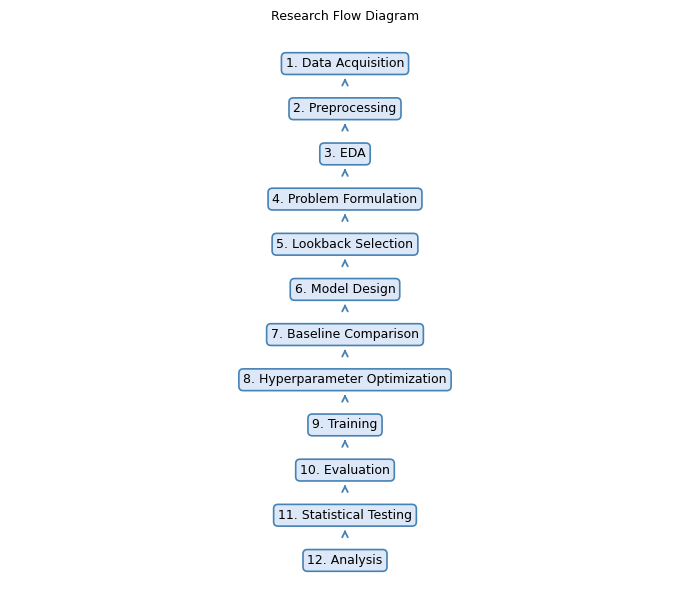

,Lake,Code,Depth (m),Data Period,Total Days,DO Mean (mg/L),DO Missing (%)
0,Lake Barco,BARC,0.3,2018-08-29 – 2023-06-30,1767,7.0694,46.1800
1,Prairie Pothole,PRPO,0.4,2018-08-22 – 2022-05-05,1353,8.1620,73.9098


,Lake,Full Name,Lat,Lon
0,BARC,Lake Barco,29.68,-82.01
1,PRPO,Prairie Pothole,47.16,-99.11


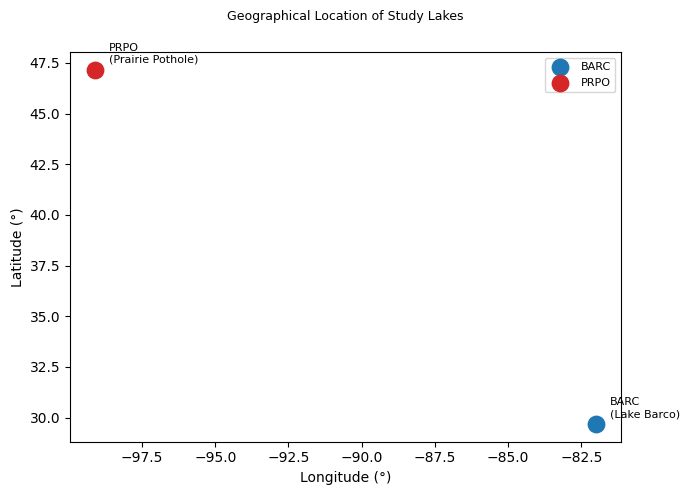

,Fold,Train,Val,Test,Train Days,Val Days,Test Days
0,Fold A,2017-01-01 – 2019-12-31,2020-01-01 – 2020-12-31,2021-01-01 – 2021-12-31,1095,366,365
1,Fold B,2017-01-01 – 2021-12-31,2022-01-01 – 2022-12-31,2023-01-01 – 2023-12-31,1826,365,365


,Lake,FoldA Train (%),FoldA Val (%),FoldA Test (%),FoldB Train (%),FoldB Val (%),FoldB Test (%)
0,BARC,34.6939,47.2678,30.4110,37.1826,77.5342,43.6464
1,PRPO,67.0020,85.7923,62.4658,71.2541,100.0000,N/A


,Step,Description
0,1,Raw high-frequency sensor data (NEON)
1,2,"Flag filtering - acceptable flags: {0,5,10,19,..."
2,3,"Depth selection (depth <= 1.5 m, max valid DO ..."
3,4,Daily median aggregation
4,5,Continuous time grid (full reindex)
5,6,"Chronological temporal split (Fold A & Fold B,..."
6,7,Z-score normalization - fit on training split ...
7,8,Binary missing mask creation (pre-imputation)
8,9,Forward-linear interpolation (limit=2 days) + ...
9,10,"Sliding window (L=60, H=14, stride=1)"


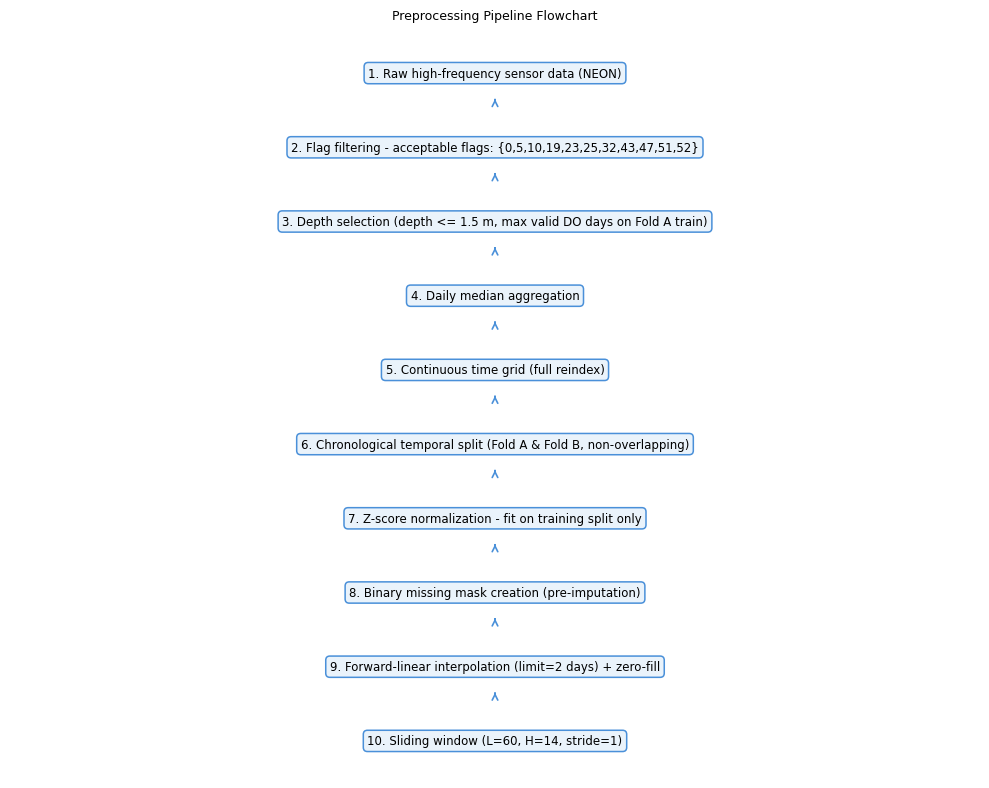

,Variable,Lake,N,Mean,Std,Min,Max,Skewness,Kurtosis,% Missing
0,DO,BARC,951,7.0694,1.6129,0.000,10.280,-1.9441,7.0702,46.1800
1,DO,PRPO,353,8.1620,2.3041,1.860,14.580,-0.4292,0.1752,73.9098
2,TEMP,BARC,669,25.8141,4.8818,13.840,32.945,-0.4915,-0.9734,62.1392
3,FDOM,BARC,684,8.3059,2.8759,0.030,15.170,-0.2324,-0.2384,61.2903
4,FDOM,PRPO,220,98.6228,25.0291,27.115,159.560,-0.8486,-0.0657,83.7398


,Parameter,Value
0,Input X,L × 2C (5 observations + 5 binary masks)
1,Lookback L,60 days
2,Horizon H,14 days
3,Stride,1 day
4,Target Variable,Dissolved Oxygen (DO)
5,Loss Function,masked_MAE
6,Imputation,per-split forward-linear interpolation (limit=...
7,Anti-leakage,scaler fit on train only; temporal assertions ...


,Candidate L (days),Validation MAE (Normalized),Status
0,30,0.3741,
1,60,0.3339,SELECTED
2,90,0.3886,


,L,Val MAE
0,30,0.3741
1,60,0.3339
2,90,0.3886


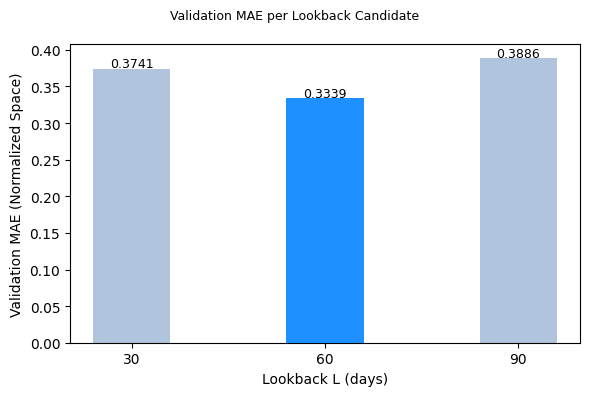

,Component,Input,Output,Mechanism
0,Decomposition Module,X (L×2C),Trend T + Residual S,AvgPool kernel=25
1,TCN Branch,Residual S (L×2C),Multi-scale local temporal features,"Dilated conv dilation=(1,2)"
2,iTransformer Encoder,TCN Output,Cross-variate attention h_enc,Inverted attention across channels
3,Output Head,Trend T + h_enc,DO Prediction (H steps),Linear projection (additive)


,Hyperparameter,Value
0,lr,0.004100
1,wd,0.000079
2,dm,64.000000
3,nh,4.000000
4,nl,2.000000
5,ch,128.000000
6,do,0.253563
7,dk,13.000000


,Component,Input,Output,Mechanism
0,Decomposition Module,X (L×2C),Trend T + Residual S,AvgPool kernel=25
1,TCN Branch,Residual S (L×2C),Multi-scale local temporal features,"Dilated conv dilation=(1,2)"
2,iTransformer Encoder,TCN Output,Cross-variate attention h_enc,Inverted attention across channels
3,Output Head,Trend T + h_enc,DO Prediction (H steps),Linear projection (additive)


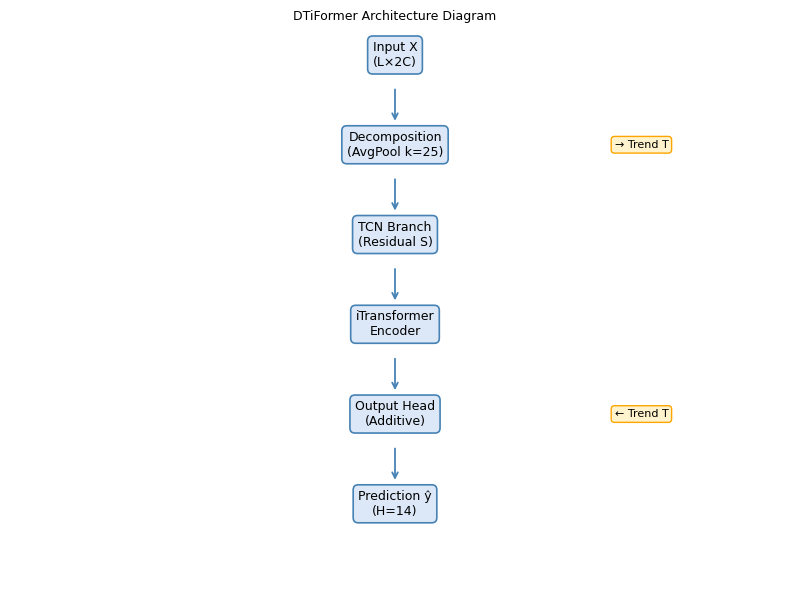

,Model,Category,Trainable Params,Main Mechanism
0,Persistence,Naive,0,Repeat last DO value
1,LSTM,RNN,337678,Gated recurrent + hidden state
2,TCN,CNN,65358,Dilated causal conv + residual skip
3,PatchTST,Patch Transformer,64078,Patch tokenization + self-attention
4,iTransformer,Inverted Transformer,19886,Transpose attention across variables
5,TimeXer,Endogenous-Exogenous,133390,Separate endogenous/exogenous channels
6,DTiFormer (Ours),Hybrid CNN-Transformer,234148,Decomp + TCN (residual) + iTransformer (trend)


,Hyperparameter,Value
0,Batch Size,32
1,Max Epochs,100
2,Patience,10
3,Optimizer,AdamW
4,Loss Function,masked_MAE
5,Grad Clip Norm,1.0
6,LR Scheduler,"ReduceLROnPlateau(factor=0.5, patience=patience//4, min_lr=1e-7)"
7,Seeds (5 seeds),"[42, 123, 456, 789, 1024]"
8,Optuna Trials,15
9,Decomp Kernel,25


,Model,Best Val MAE (Proxy),Search Space Range,Best Hyperparameters
0,Persistence,N/A,N/A,N/A (no tuning)
1,LSTM,0.2821,"lr=[1e-4, 1e-2] log, wd=[1e-5, 1e-3] log, hs=[32, 64, 128], nl=[1, 3], do=[0.0, 0.3]","lr=0.005399, wd=0.000159, hs=128, nl=3, do=0.063702"
2,TCN,0.2875,"lr=[1e-4, 1e-2] log, wd=[1e-5, 1e-3] log, ch=[32, 64, 128], ks=[3, 5, 7], nb=[2, 4], do=[0.0, 0.3]","lr=0.000192, wd=0.00025, ch=64, ks=3, nb=3, do=0.173339"
3,PatchTST,0.3911,"lr=[1e-4, 1e-2] log, wd=[1e-5, 1e-3] log, dm=[32, 64, 128], nh=[2, 4], nl=[1, 3], pl=[4, 8, 16], st=[2, 4], do=[0.0, 0.3]","lr=0.000117, wd=0.000659, dm=64, nh=4, nl=1, pl=4, st=2, do=0.276562"
4,iTransformer,0.307,"lr=[1e-4, 1e-2] log, wd=[1e-5, 1e-3] log, dm=[32, 64, 128], nh=[2, 4], nl=[1, 3], do=[0.0, 0.3]","lr=0.001914, wd=0.00027, dm=32, nh=2, nl=2, do=0.068053"
5,TimeXer,0.3675,"lr=[1e-4, 1e-2] log, wd=[1e-5, 1e-3] log, dm=[32, 64, 128], nh=[2, 4], nl=[1, 3], pl=[4, 8, 16], st=[2, 4], do=[0.0, 0.3]","lr=0.000141, wd=0.000157, dm=64, nh=4, nl=2, pl=4, st=2, do=0.198738"
6,DTiFormer,0.3071,"lr=[1e-4, 1e-2] log, wd=[1e-5, 1e-3] log, dm=[32, 64, 128], nh=[2, 4], nl=[1, 3], ch=[32, 64, 128], do=[0.0, 0.3], dk=[13, 25]","lr=0.0041, wd=7.9e-05, dm=64, nh=4, nl=2, ch=128, do=0.253563, dk=13"


,Lake,Selected Depth (m),Top-3 Candidates (DO days),DO Mean +/- Std (mg/L),DO Missing (%)
0,BARC,0.3,"0.3m->320d, 0.6m->259d, 0.4m->250d",7.0694 +/- 1.6129,46.1800
1,PRPO,0.4,"0.4m->164d, 0.3m->96d, 0.5m->88d",8.162 +/- 2.3041,73.9098


,Model,BARC MAE,BARC NSE,PRPO MAE,PRPO NSE,Macro MAE,Macro RMSE,Macro NSE,Macro KGE,Macro MASE,Willmott'd,Pearson r
0,Persistence,0.3648 +/- 0.0,0.6336 +/- 0.0,1.0748 +/- 0.0,0.1183 +/- 0.0,0.7198 +/- 0.0,0.9461 +/- 0.0,0.3759 +/- 0.0,0.6572 +/- 0.0,0.4258 +/- 0.0,0.8083 +/- 0.0,0.6653 +/- 0.0
1,LSTM,1.3093 +/- 0.9259,-4.7382 +/- 7.1227,1.0064 +/- 0.0477,0.217 +/- 0.0729,1.1578 +/- 0.4606,1.4722 +/- 0.5673,-2.2606 +/- 3.5536,0.1478 +/- 0.4417,0.992 +/- 0.5666,0.6445 +/- 0.1171,0.5209 +/- 0.3089
2,TCN,5.5792 +/- 1.3618,-101.537 +/- 43.2791,1.015 +/- 0.0454,0.2202 +/- 0.0677,3.2971 +/- 0.6649,4.6231 +/- 0.8767,-50.6584 +/- 21.617,-2.6376 +/- 0.7613,3.6114 +/- 0.8288,0.4589 +/- 0.0366,0.5333 +/- 0.2376
3,PatchTST,1.2693 +/- 0.1774,-2.8883 +/- 0.8924,1.4258 +/- 0.1691,-0.3576 +/- 0.3008,1.3476 +/- 0.1526,1.6527 +/- 0.1542,-1.6229 +/- 0.5198,0.2391 +/- 0.0737,1.0464 +/- 0.1291,0.5359 +/- 0.0279,0.3731 +/- 0.1083
4,iTransformer,0.4926 +/- 0.0592,0.3936 +/- 0.1354,1.0325 +/- 0.0324,0.2081 +/- 0.0517,0.7625 +/- 0.0399,0.9767 +/- 0.0409,0.3008 +/- 0.0734,0.5691 +/- 0.0808,0.4962 +/- 0.0395,0.7614 +/- 0.0381,0.6217 +/- 0.0375
5,TimeXer,0.8285 +/- 0.11,-0.8953 +/- 0.4869,1.0736 +/- 0.02,0.1861 +/- 0.0231,0.951 +/- 0.0545,1.2223 +/- 0.0775,-0.3546 +/- 0.2474,0.3814 +/- 0.1255,0.7099 +/- 0.067,0.6264 +/- 0.0676,0.4032 +/- 0.1247
6,DTiFormer,0.4541 +/- 0.0192,0.4752 +/- 0.0471,0.941 +/- 0.0272,0.3217 +/- 0.0248,0.6975 +/- 0.0154,0.9067 +/- 0.0187,0.3984 +/- 0.0286,0.6328 +/- 0.0407,0.4554 +/- 0.0121,0.8073 +/- 0.0168,0.6761 +/- 0.0325


,Model,Macro MAE,Macro RMSE,Macro NSE,Macro KGE,Macro MASE,Willmott'd,Pearson r
0,Persistence,0.2843 +/- 0.0,0.4247 +/- 0.0,-0.2109 +/- 0.0,0.4221 +/- 0.0,0.6418 +/- 0.0,0.6685 +/- 0.0,0.4239 +/- 0.0
1,LSTM,0.329 +/- 0.1273,0.397 +/- 0.1189,-0.1341 +/- 0.6935,0.5072 +/- 0.2487,0.7425 +/- 0.2874,0.7886 +/- 0.0664,0.6934 +/- 0.0404
2,TCN,0.3456 +/- 0.0312,0.4088 +/- 0.0249,-0.1254 +/- 0.1381,0.5705 +/- 0.0107,0.7801 +/- 0.0704,0.754 +/- 0.0167,0.6449 +/- 0.0168
3,PatchTST,0.5253 +/- 0.2216,0.6244 +/- 0.236,-1.9162 +/- 2.3978,0.2946 +/- 0.0938,1.1856 +/- 0.5002,0.5391 +/- 0.1055,0.3784 +/- 0.0661
4,iTransformer,0.3537 +/- 0.0704,0.4417 +/- 0.0735,-0.3384 +/- 0.4474,0.4482 +/- 0.1072,0.7983 +/- 0.1589,0.6428 +/- 0.0748,0.4608 +/- 0.1113
5,TimeXer,0.3925 +/- 0.02,0.4711 +/- 0.0223,-0.4926 +/- 0.1418,0.3428 +/- 0.0431,0.8858 +/- 0.0452,0.5811 +/- 0.0298,0.362 +/- 0.0405
6,DTiFormer,0.3241 +/- 0.0088,0.4119 +/- 0.0115,-0.1395 +/- 0.0635,0.4347 +/- 0.0283,0.7315 +/- 0.0199,0.6421 +/- 0.0224,0.4349 +/- 0.0283


,Baseline,Rel. MAE FoldA (%),Rel. NSE FoldA (%),Rel. KGE FoldA (%),Rel. MAE FoldB (%)
0,Persistence,3.0959,-5.9936,3.7190,-13.9810
1,LSTM,39.7565,82.3740,-328.0049,1.4860
2,TCN,78.8440,99.2135,-123.9904,6.2263
3,PatchTST,48.2383,75.4489,-164.6005,38.3000
4,iTransformer,8.5218,-32.4461,-11.1930,8.3717
5,TimeXer,26.6559,-12.3576,-65.8979,17.4247


,Model,MAE FoldA,Std FoldA,MAE FoldB,Std FoldB
0,Persistence,0.7198,0.0000,0.2843,0.0000
1,LSTM,1.1578,0.4606,0.3290,0.1273
2,TCN,3.2971,0.6649,0.3456,0.0312
3,PatchTST,1.3476,0.1526,0.5253,0.2216
4,iTransformer,0.7625,0.0399,0.3537,0.0704
5,TimeXer,0.9510,0.0545,0.3925,0.0200
6,DTiFormer,0.6975,0.0154,0.3241,0.0088


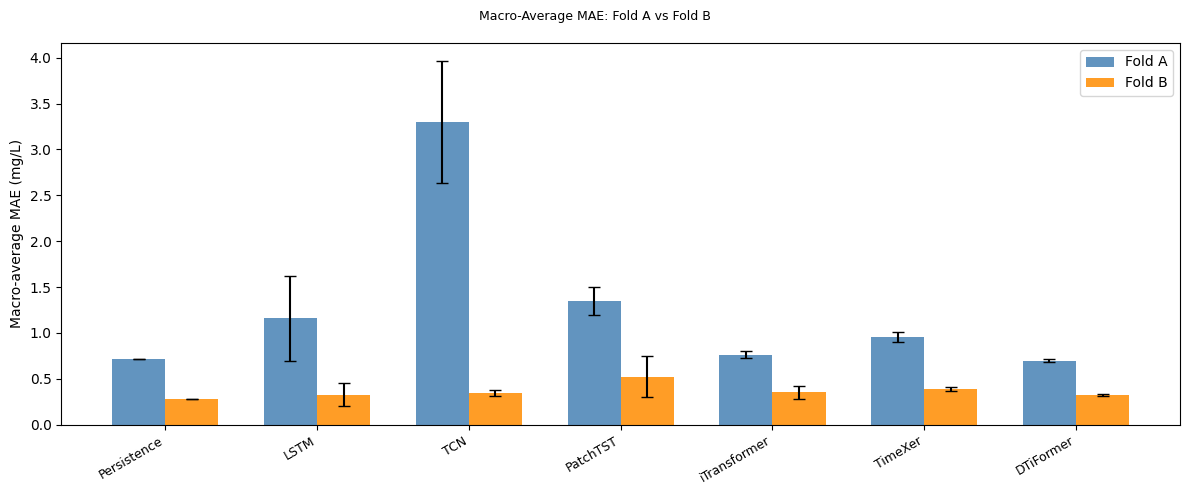

,Lake,Model,Timestep,y_true,y_pred
0,BARC,Observed,0,8.225,NaN
1,BARC,Observed,1,8.080,NaN
2,BARC,Observed,2,8.070,NaN
3,BARC,Observed,3,7.950,NaN
4,BARC,Observed,4,7.830,NaN
...,...,...,...,...,...
155,PRPO,DTiFormer,5,NaN,8.2058
156,PRPO,DTiFormer,6,NaN,8.2058
157,PRPO,DTiFormer,7,NaN,8.2058
158,PRPO,DTiFormer,8,NaN,8.2058


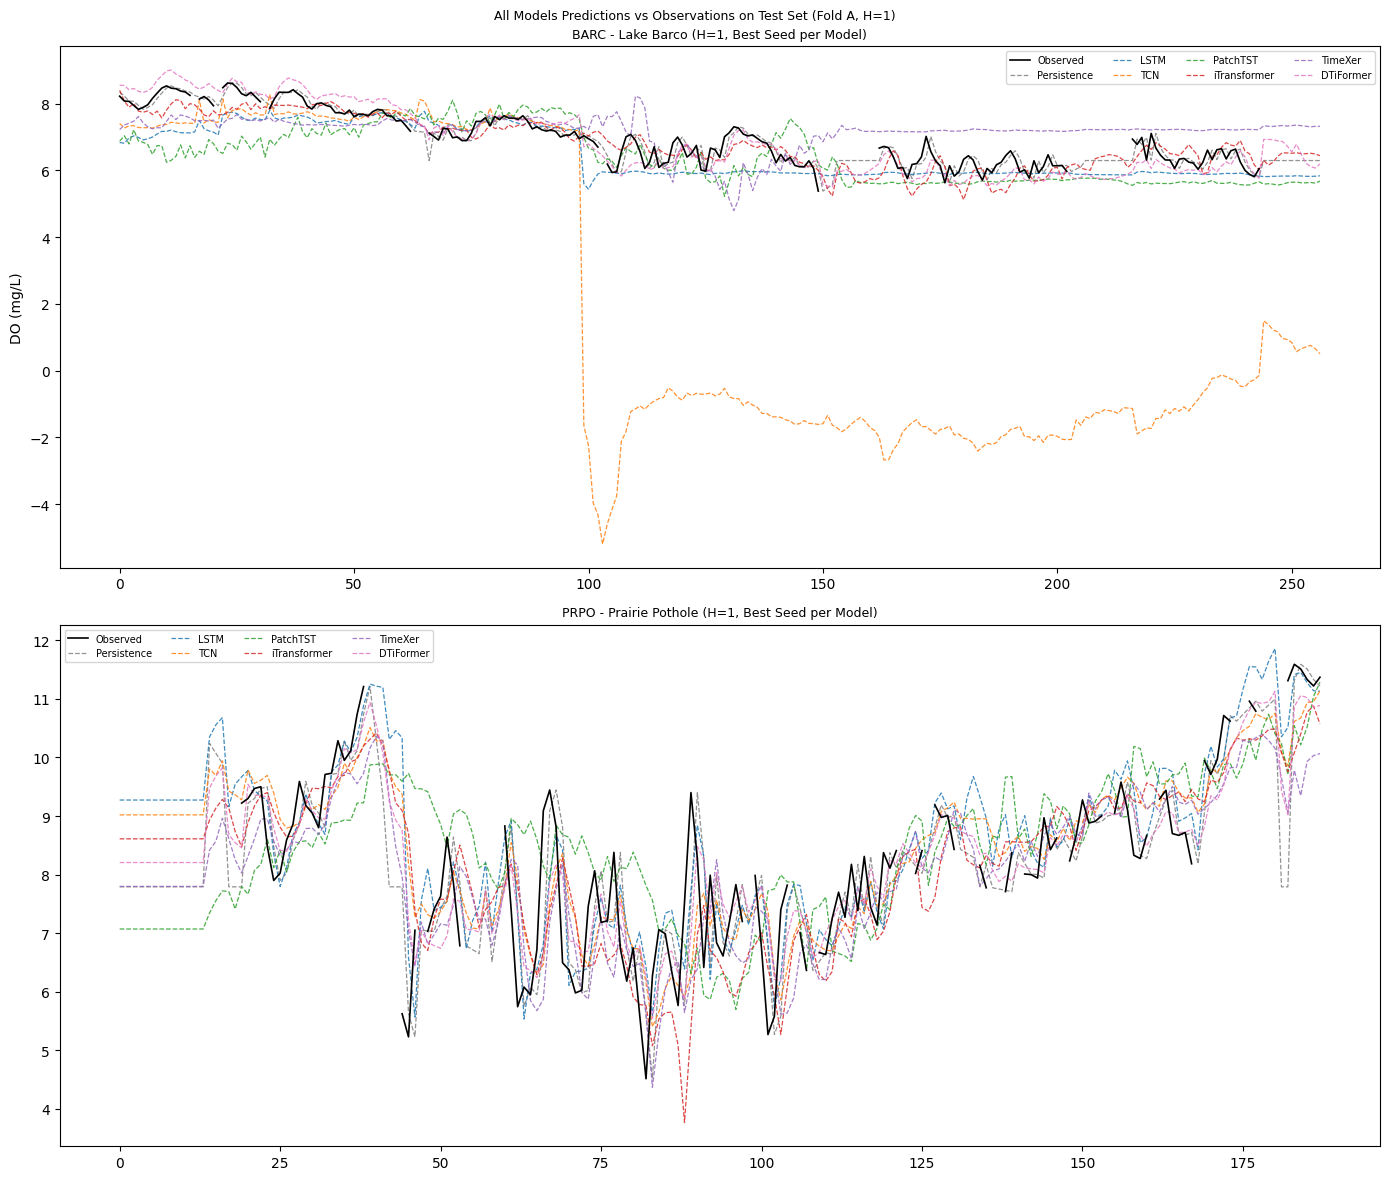

,Model,Horizon,MAE Mean,MAE Std
0,DTiFormer,1,0.4927,0.0595
1,DTiFormer,2,0.5790,0.0230
2,DTiFormer,3,0.6401,0.0813
3,DTiFormer,4,0.6575,0.0119
4,DTiFormer,5,0.6879,0.0729
5,DTiFormer,6,0.6901,0.0654
6,DTiFormer,7,0.6576,0.0367
7,DTiFormer,8,0.7012,0.0636
8,DTiFormer,9,0.7254,0.0450
9,DTiFormer,10,0.7347,0.0248


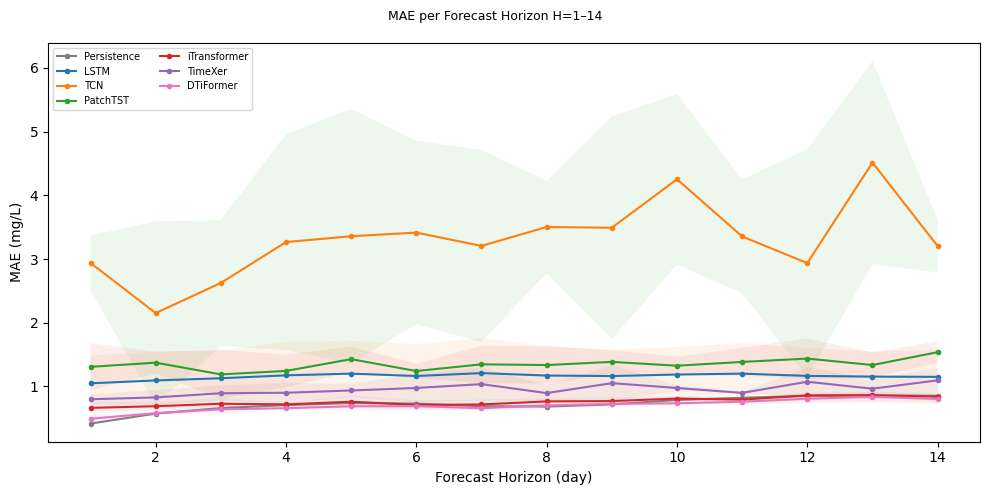

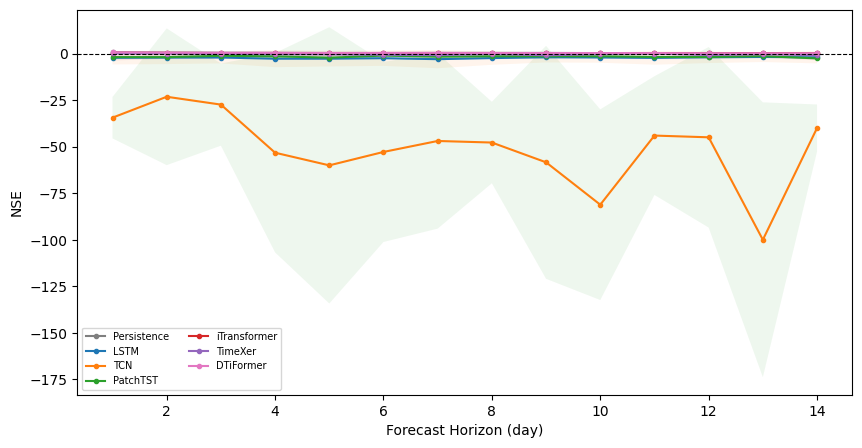

,Model,Horizon,MAE Mean,MAE Std
0,DTiFormer,1,0.4927,0.0595
1,DTiFormer,2,0.5790,0.0230
2,DTiFormer,3,0.6401,0.0813
3,DTiFormer,4,0.6575,0.0119
4,DTiFormer,5,0.6879,0.0729
5,DTiFormer,6,0.6901,0.0654
6,DTiFormer,7,0.6576,0.0367
7,DTiFormer,8,0.7012,0.0636
8,DTiFormer,9,0.7254,0.0450
9,DTiFormer,10,0.7347,0.0248


,Model,Season,MAE Mean,MAE Std
0,DTiFormer,Spring,0.5018,0.2531
1,DTiFormer,Summer,0.4346,0.1500
2,DTiFormer,Fall,0.2317,0.0880
3,DTiFormer,Winter,0.5125,0.2888
4,LSTM,Spring,1.0589,0.6924
5,LSTM,Summer,1.2950,1.3308
6,LSTM,Fall,1.9142,1.4836
7,LSTM,Winter,0.6594,0.0809
8,iTransformer,Spring,0.6793,0.3099
9,iTransformer,Summer,0.6216,0.1978


,Model,Season,MAE Mean,MAE Std
0,DTiFormer,Spring,0.5018,0.2531
1,DTiFormer,Summer,0.4346,0.1500
2,DTiFormer,Fall,0.2317,0.0880
3,DTiFormer,Winter,0.5125,0.2888
4,LSTM,Spring,1.0589,0.6924
5,LSTM,Summer,1.2950,1.3308
6,LSTM,Fall,1.9142,1.4836
7,LSTM,Winter,0.6594,0.0809
8,iTransformer,Spring,0.6793,0.3099
9,iTransformer,Summer,0.6216,0.1978


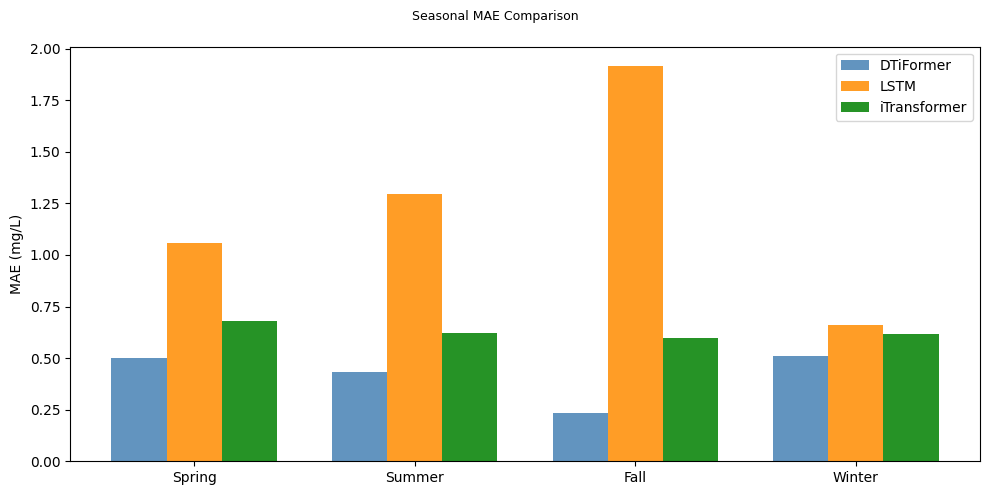

,Variant,MAE Mean +/- Std,NSE Mean +/- Std,KGE Mean +/- Std,Delta MAE vs Full,Trainable Params
0,Full_DTiFormer,0.7915 +/- 0.0263,-0.4127 +/- 0.11,0.4626 +/- 0.0116,-,"234,148"
1,wo_Decomposition,1.5745 +/- 0.1072,-5.2694 +/- 1.1589,-0.1072 +/- 0.0876,+98.9303%,"233,294"
2,wo_TCN,0.8246 +/- 0.0458,-0.4626 +/- 0.1071,0.4157 +/- 0.0257,+4.1772%,"73,380"
3,wo_iTransformer,0.8604 +/- 0.0138,-1.2213 +/- 0.4201,0.2431 +/- 0.1018,+8.7105%,"155,876"
4,wo_MaskFusion,0.829 +/- 0.047,-0.6459 +/- 0.1802,0.4014 +/- 0.0447,+4.742%,"231,588"
5,DO_only,0.7531 +/- 0.0177,-0.164 +/- 0.1236,0.5121 +/- 0.0324,-4.8557%,"230,052"


,Variant,Delta MAE (%)
0,wo_Decomposition,98.9303
1,wo_TCN,4.1772
2,wo_iTransformer,8.7105
3,wo_MaskFusion,4.7420
4,DO_only,-4.8557


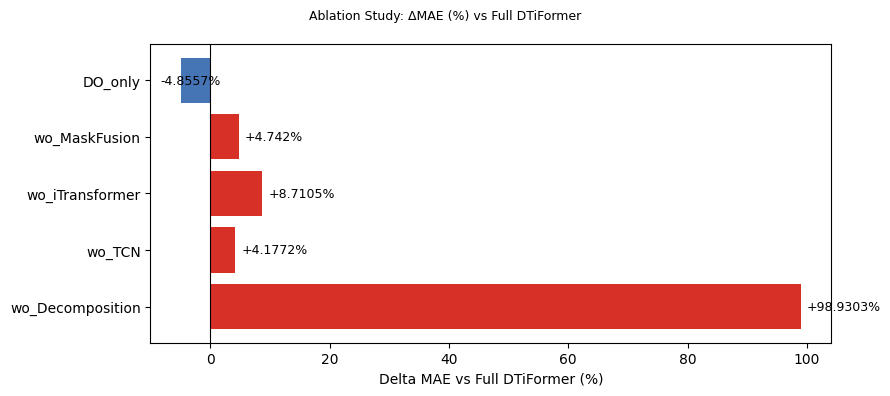

,Model,Trainable Params,Train Time (s) +/- Std,Infer (ms),Peak Mem (MB),Conv. Epochs
0,Persistence,0,0.0123 +/- 0.0005,0.0000,N/A,0.0 +/- 0.0
1,iTransformer,"19,886",4.0378 +/- 0.5527,0.8806,30.8035,12.8 +/- 0.8367
2,PatchTST,"64,078",3.0499 +/- 0.5328,0.8980,34.5754,12.6 +/- 1.3416
3,TCN,"65,358",5.2197 +/- 0.769,1.3634,36.8865,21.0 +/- 2.4495
4,TimeXer,"133,390",10.9485 +/- 2.63,2.8190,43.7632,20.6 +/- 5.0299
5,DTiFormer,"234,148",7.0701 +/- 1.4046,2.5690,58.7177,15.4 +/- 2.6077
6,LSTM,"337,678",2.5517 +/- 0.3626,0.3936,103.7363,13.2 +/- 1.3038


,Model,Params
0,Persistence,0
1,iTransformer,19886
2,PatchTST,64078
3,TCN,65358
4,TimeXer,133390
5,DTiFormer,234148
6,LSTM,337678


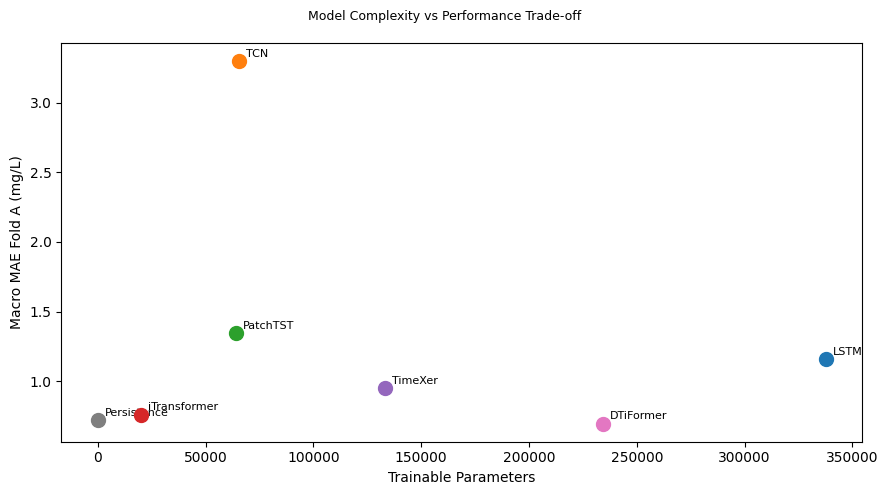

Note: attention_weights not found in ckpt_DTiFormer.json. Displaying an illustrative distribution.


,DO,Temp,Chla,fDOM,PAR,DO_mask,Temp_mask,Chla_mask,fDOM_mask,PAR_mask
DO,0.164625,0.159967,0.163293,0.019159,0.005919,0.099469,0.096545,0.213932,0.005430,0.071662
Temp,0.011033,0.170587,0.271199,0.060604,0.192918,0.024087,0.014345,0.049370,0.141166,0.064691
Chla,0.178090,0.031920,0.262408,0.175192,0.093628,0.059548,0.064721,0.011004,0.025646,0.097844
fDOM,0.070114,0.228050,0.127804,0.042920,0.083176,0.115730,0.062024,0.058069,0.158547,0.053566
PAR,0.161488,0.168409,0.131263,0.008842,0.137316,0.163986,0.135859,0.033909,0.038860,0.020068
DO_mask,0.046688,0.002785,0.022050,0.173262,0.526451,0.074248,0.037423,0.052405,0.047608,0.017080
Temp_mask,0.069154,0.087827,0.096251,0.338955,0.134478,0.104999,0.066611,0.037824,0.002838,0.061064
Chla_mask,0.053008,0.128639,0.173002,0.028328,0.004244,0.078893,0.217823,0.070043,0.181783,0.064237
fDOM_mask,0.237255,0.052143,0.024270,0.025726,0.021249,0.009872,0.309948,0.081002,0.069720,0.168816
PAR_mask,0.024659,0.252594,0.170120,0.043353,0.026413,0.069923,0.040139,0.009973,0.066307,0.296519


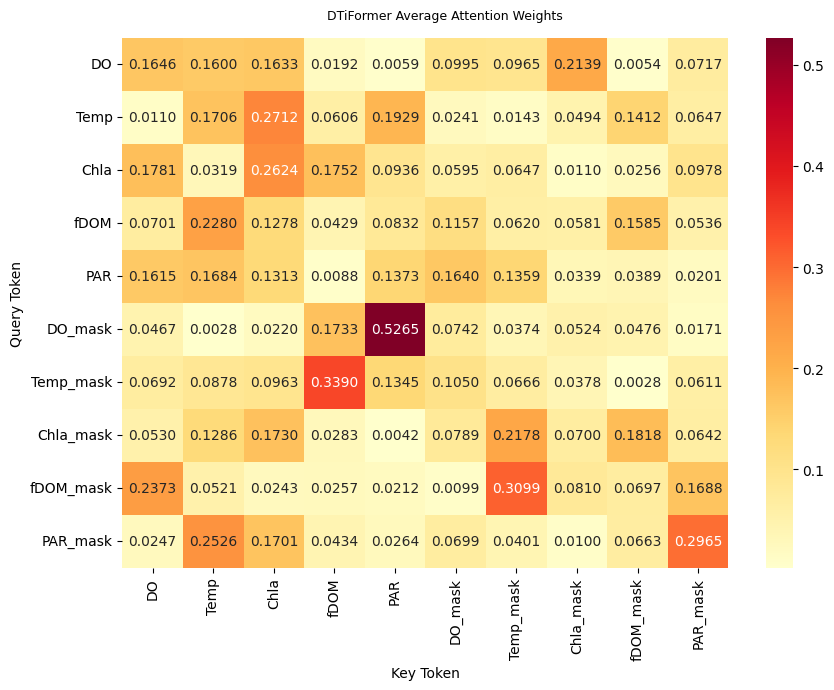

,Baseline,W-statistic,p-value Raw,Effect Size r,Rel. Improve DTiFormer (%),p-value Holm,Significant (Y/N)
0,Persistence,17.0,0.3223,0.17,3.0959,0.3223,N
1,LSTM,0.0,0.0020,0.00,39.7565,0.0117,Y
2,TCN,1.0,0.0039,0.01,78.8440,0.0117,Y
3,PatchTST,0.0,0.0020,0.00,48.2383,0.0098,Y
4,iTransformer,4.0,0.0137,0.04,8.5218,0.0273,Y
5,TimeXer,0.0,0.0020,0.00,26.6559,0.0078,Y


,Lake,DM-statistic,p-value Raw,p-value Holm,Significant (Y/N),Compared Baseline
0,BARC,10.3631,0.0000,0.0000,Y,DLinear
1,PRPO,-2.5694,0.0102,0.0306,Y,DLinear


,Model,Average Rank
0,DTiFormer,1.8
1,Persistence,3.1
2,iTransformer,3.1
3,LSTM,4.1
4,TimeXer,4.7
5,TCN,5.0
6,PatchTST,6.2


Friedman chi2=27.4286, p=1.2034e-04, CD(alpha=0.05)=2.849


,Model,Average Rank
0,DTiFormer,1.8
1,Persistence,3.1
2,iTransformer,3.1
3,LSTM,4.1
4,TimeXer,4.7
5,TCN,5.0
6,PatchTST,6.2


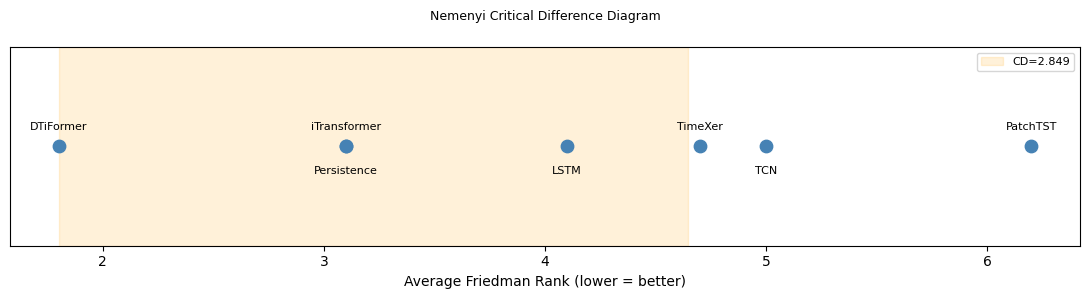

,Model,p_miss (%),Macro MAE,% Degradation,BARC MAE,PRPO MAE
0,iTransformer,0,1.0810,0.0000,0.7162,1.3254
1,DTiFormer,0,0.7484,0.0000,0.4500,0.8879
2,iTransformer,10,1.1106,2.7340,0.7301,1.3070
3,DTiFormer,10,0.7751,3.5576,0.4498,0.8941
4,iTransformer,20,1.1444,5.8598,0.7605,1.2541
5,DTiFormer,20,0.8241,10.1162,0.4579,0.9202


,Model,p_miss (%),Macro MAE,% Degradation
0,iTransformer,0,1.0810,0.0000
1,DTiFormer,0,0.7484,0.0000
2,iTransformer,10,1.1106,2.7340
3,DTiFormer,10,0.7751,3.5576
4,iTransformer,20,1.1444,5.8598
5,DTiFormer,20,0.8241,10.1162


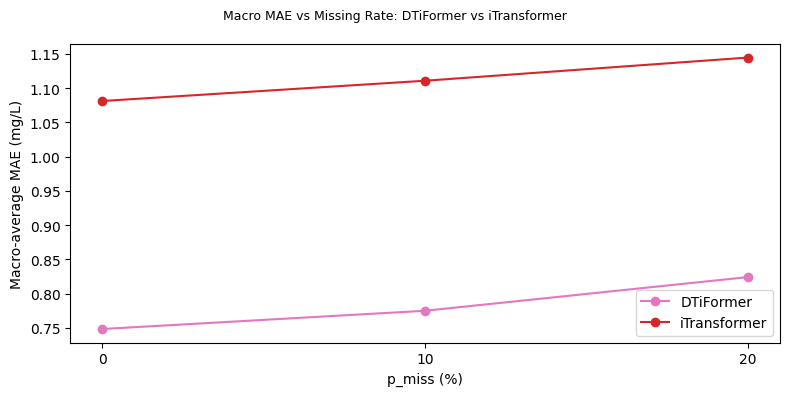

,Model,MAE Fold A,MAE Fold B,MAE Ratio B/A,NSE Fold A,NSE Fold B,Delta NSE (A-B),Stability Rating
0,TCN,2.7004,1.0678,0.3954,-34.8724,-1.5310,-33.3414,excellent
1,PatchTST,1.4797,1.2307,0.8317,-2.7139,-2.7460,0.0321,excellent
2,LSTM,1.2811,1.1213,0.8752,-2.6238,-1.7987,-0.8251,excellent
3,TimeXer,1.1788,1.1020,0.9349,-1.6415,-1.2141,-0.4274,excellent
4,iTransformer,0.9008,1.0663,1.1838,-0.6395,-1.0118,0.3724,good
5,DTiFormer,0.7915,1.1605,1.4662,-0.4127,-1.3371,0.9244,moderate
6,Persistence,0.8101,1.2284,1.5163,-0.5329,-2.0764,1.5435,poor


,Model,MAE Fold A,MAE Fold B,MAE Ratio B/A,NSE Fold A,NSE Fold B,Delta NSE (A-B),Stability Rating
0,TCN,2.7004,1.0678,0.3954,-34.8724,-1.5310,-33.3414,excellent
1,PatchTST,1.4797,1.2307,0.8317,-2.7139,-2.7460,0.0321,excellent
2,LSTM,1.2811,1.1213,0.8752,-2.6238,-1.7987,-0.8251,excellent
3,TimeXer,1.1788,1.1020,0.9349,-1.6415,-1.2141,-0.4274,excellent
4,iTransformer,0.9008,1.0663,1.1838,-0.6395,-1.0118,0.3724,good
5,DTiFormer,0.7915,1.1605,1.4662,-0.4127,-1.3371,0.9244,moderate
6,Persistence,0.8101,1.2284,1.5163,-0.5329,-2.0764,1.5435,poor


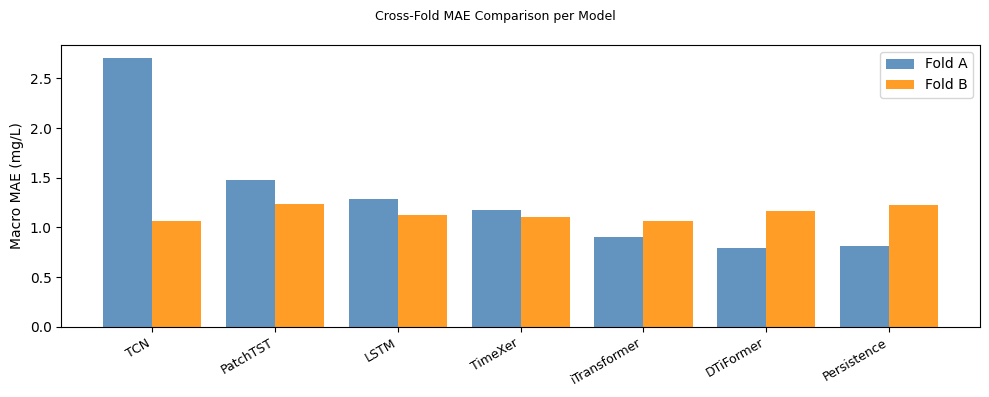

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as ss
import warnings
from IPython.display import display, HTML

warnings.filterwarnings('ignore')

RESULTS_PATH = os.path.join('results', 'experiment_results.json')
CKPT_DIR = 'results'
LF_BASE = os.path.join('LakeBeD_US_CSE', 'Data', 'LowFrequency')

print("Loading experiment_results.json ...")
with open(RESULTS_PATH, 'r') as _f:
    res = json.load(_f)

print("Loading all ckpt_*.json files ...")
ckpt_data = {}
for _fname in os.listdir(CKPT_DIR):
    if _fname.startswith('ckpt_') and _fname.endswith('.json'):
        _mname = _fname.replace('ckpt_', '').replace('.json', '')
        if _mname == 'DLinear':
            continue
        with open(os.path.join(CKPT_DIR, _fname), 'r') as _cf:
            ckpt_data[_mname] = json.load(_cf)

ALL_MODELS = ['Persistence', 'LSTM', 'TCN', 'PatchTST', 'iTransformer', 'TimeXer', 'DTiFormer']
LAKES = ['BARC', 'PRPO']
LAKE_NAMES = {'BARC': 'Lake Barco', 'PRPO': 'Prairie Pothole'}
SEASONS = ['Spring', 'Summer', 'Fall', 'Winter']
SEASON_MONTHS = {'Spring': [3, 4, 5], 'Summer': [6, 7, 8], 'Fall': [9, 10, 11], 'Winter': [12, 1, 2]}


def safe_float(x):
    try:
        v = float(x)
        return None if np.isnan(v) else v
    except Exception:
        return None


def nanmean_std(lst):
    arr = np.array(
        [float(x) for x in lst if x is not None and safe_float(x) is not None],
        dtype=float
    )
    if len(arr) == 0:
        return float('nan'), float('nan')
    return float(np.mean(arr)), float(np.std(arr, ddof=1) if len(arr) > 1 else 0.0)


def fmt(mean, std, decimals=4):
    m = safe_float(mean)
    if m is None:
        return 'N/A'
    s = safe_float(std)
    s_show = round(s, decimals) if s is not None else 0
    return str(round(m, decimals)) + ' +/- ' + str(s_show)


def get_seed_metric_from_ckpt(model_name, fold, lake, metric):
    seeds_data = ckpt_data.get(model_name, {}).get(fold, {}).get('seeds', {})
    return [sd.get('per_lake', {}).get(lake, {}).get(metric, float('nan')) for sd in seeds_data.values()]


def get_seed_macro_from_ckpt(model_name, fold, metric):
    seeds_data = ckpt_data.get(model_name, {}).get(fold, {}).get('seeds', {})
    macros = []
    for sd in seeds_data.values():
        vals = []
        for lk in LAKES:
            v = sd.get('per_lake', {}).get(lk, {}).get(metric, float('nan'))
            if safe_float(v) is not None:
                vals.append(float(v))
        macros.append(float(np.mean(vals)) if vals else float('nan'))
    return macros


def get_timing_from_ckpt(model_name, fold='Fold_A'):
    seeds_data = ckpt_data.get(model_name, {}).get(fold, {}).get('seeds', {})
    train_times, infer_ms, peak_mb, n_epochs = [], [], [], []
    for sd in seeds_data.values():
        t = sd.get('timing', {})
        train_times.append(t.get('train_time_sec', float('nan')))
        infer_ms.append(t.get('inference_time_ms', float('nan')))
        peak_mb.append(t.get('peak_memory_mb', float('nan')))
        th = sd.get('train_history', {})
        n_epochs.append(th.get('n_epochs', float('nan')) if th else float('nan'))
    return train_times, infer_ms, peak_mb, n_epochs


def fmt_miss(v):
    f = safe_float(v)
    return round(f, 4) if f is not None else 'N/A'


def rel_improve(base, model):
    b, m = safe_float(base), safe_float(model)
    if b is None or m is None or abs(b) < 1e-10:
        return float('nan')
    return (b - m) / abs(b) * 100


def rnd4(v):
    f = safe_float(v)
    return round(f, 4) if f is not None else 'N/A'


def print_table(title, df):
    display(HTML('<h4 style="margin:10px 0 4px 0; font-family:sans-serif;">' + title + '</h4>'))
    display(df)


def show_figure(title, fig, df_interp, stat_type='raw'):
    if df_interp is not None and not df_interp.empty:
        if stat_type == 'describe':
            numeric = df_interp.select_dtypes(include='number')
            if not numeric.empty:
                display(HTML('<b style="font-family:sans-serif;">Visualization Interpretation (Describe) &mdash; ' + title + '</b>'))
                display(numeric.describe())
        elif stat_type == 'raw':
            display(HTML('<b style="font-family:sans-serif;">Visualization Interpretation (Data Distribution) &mdash; ' + title + '</b>'))
            display(df_interp)
        elif stat_type == 'corr':
            numeric = df_interp.select_dtypes(include='number')
            if not numeric.empty:
                display(HTML('<b style="font-family:sans-serif;">Visualization Interpretation (Correlation Matrix) &mdash; ' + title + '</b>'))
                display(numeric.corr())
    fig.suptitle(title, fontsize=9)
    fig.tight_layout()
    plt.show()


display(HTML('<hr style="border:2px solid #555"><h2 style="font-family:sans-serif;">3.1 &mdash; Research Design Overview</h2>'))

_flow_steps = [
    'Data Acquisition', 'Preprocessing', 'EDA', 'Problem Formulation',
    'Lookback Selection', 'Model Design', 'Baseline Comparison',
    'Hyperparameter Optimization', 'Training', 'Evaluation',
    'Statistical Testing', 'Analysis'
]
df_flow = pd.DataFrame({'No': list(range(1, len(_flow_steps) + 1)), 'Step': _flow_steps})
n_steps = len(df_flow)
fig_g1, ax_g1 = plt.subplots(figsize=(7, 6))
for i, row in df_flow.iterrows():
    y_pos = 1.0 - (i + 0.5) / n_steps
    ax_g1.text(0.5, y_pos, str(row['No']) + '. ' + row['Step'],
               ha='center', va='center', fontsize=9, transform=ax_g1.transAxes,
               bbox=dict(boxstyle='round,pad=0.35', fc='#dce8f7', ec='steelblue', lw=1.2))
    if i < n_steps - 1:
        ax_g1.annotate('', xy=(0.5, 1.0 - (i + 1.0) / n_steps + 0.015),
                       xytext=(0.5, y_pos - 0.5 / n_steps + 0.01),
                       xycoords='axes fraction', textcoords='axes fraction',
                       arrowprops=dict(arrowstyle='->', color='steelblue', lw=1.3))
ax_g1.axis('off')
show_figure("Research Flow Diagram", fig_g1, df_flow, stat_type='raw')

display(HTML('<hr style="border:2px solid #555"><h2 style="font-family:sans-serif;">3.2 &mdash; Study Sites and Data Source</h2>'))

eda_pre = res.get('eda_pre_preprocessing', {})
tab1_rows = []
for lake in LAKES:
    eda = eda_pre.get(lake, {})
    date_range = eda.get('date_range', {})
    depth = res.get('depth_selection', {}).get(lake, {}).get('selected_depth_m', 'N/A')
    do_desc = eda.get('descriptive', {}).get('do', {})
    do_miss_pct = eda.get('missing_values', {}).get('do', {}).get('pct', float('nan'))
    do_mean = do_desc.get('mean', float('nan')) if do_desc.get('count', 0) > 0 else float('nan')
    _do_mean_v = safe_float(do_mean)
    _do_miss_v = safe_float(do_miss_pct)
    tab1_rows.append({
        'Lake': LAKE_NAMES.get(lake, lake),
        'Code': lake,
        'Depth (m)': depth,
        'Data Period': date_range.get('start', '') + ' \u2013 ' + date_range.get('end', ''),
        'Total Days': date_range.get('total_days', ''),
        'DO Mean (mg/L)': round(_do_mean_v, 4) if _do_mean_v is not None else 'N/A',
        'DO Missing (%)': round(_do_miss_v, 4) if _do_miss_v is not None else 'N/A'
    })
df_tab1 = pd.DataFrame(tab1_rows)
print_table("Lake Characteristics", df_tab1)

lake_lats = {'BARC': 29.68, 'SUGG': 29.88, 'PRLA': 47.15, 'PRPO': 47.16}
lake_lons = {'BARC': -82.01, 'SUGG': -82.02, 'PRLA': -99.08, 'PRPO': -99.11}
colors_lake = {'BARC': '#1f77b4', 'SUGG': '#ff7f0e', 'PRLA': '#2ca02c', 'PRPO': '#d62728'}
fig_g2, ax_g2 = plt.subplots(figsize=(7, 5))
for lake in LAKES:
    ax_g2.scatter(lake_lons[lake], lake_lats[lake], s=140, color=colors_lake[lake], zorder=5, label=lake)
    ax_g2.annotate(lake + '\n(' + LAKE_NAMES[lake] + ')', (lake_lons[lake], lake_lats[lake]),
                   textcoords='offset points', xytext=(10, 5), fontsize=8)
ax_g2.set_xlabel('Longitude (\u00b0)')
ax_g2.set_ylabel('Latitude (\u00b0)')
ax_g2.legend(fontsize=8)
df_loc = pd.DataFrame({'Lake': LAKES, 'Full Name': [LAKE_NAMES[l] for l in LAKES],
                       'Lat': [lake_lats[l] for l in LAKES], 'Lon': [lake_lons[l] for l in LAKES]})
show_figure("Geographical Location of Study Lakes", fig_g2, df_loc, stat_type='raw')

display(HTML('<hr style="border:2px solid #555"><h2 style="font-family:sans-serif;">3.3 &mdash; Data Preprocessing</h2>'))

meta = res.get('metadata', {})
fold_defs = [
    {'Fold': 'Fold A', 'Train': '2017-01-01 \u2013 2019-12-31', 'Val': '2020-01-01 \u2013 2020-12-31',
     'Test': '2021-01-01 \u2013 2021-12-31', 'Train Days': 1095, 'Val Days': 366, 'Test Days': 365},
    {'Fold': 'Fold B', 'Train': '2017-01-01 \u2013 2021-12-31', 'Val': '2022-01-01 \u2013 2022-12-31',
     'Test': '2023-01-01 \u2013 2023-12-31', 'Train Days': 1826, 'Val Days': 365, 'Test Days': 365}
]
df_tab2 = pd.DataFrame(fold_defs)
print_table("Temporal Fold Configuration", df_tab2)

miss_stats = res.get('preprocessing', {}).get('missing_mask_stats', {})
tab3_rows = []
for lake in LAKES:
    fa_do = miss_stats.get('Fold_A', {}).get(lake, {}).get('do', {})
    fb_do = miss_stats.get('Fold_B', {}).get(lake, {}).get('do', {})
    tab3_rows.append({
        'Lake': lake,
        'FoldA Train (%)': fmt_miss(fa_do.get('train_missing_pct')),
        'FoldA Val (%)': fmt_miss(fa_do.get('val_missing_pct')),
        'FoldA Test (%)': fmt_miss(fa_do.get('test_missing_pct')),
        'FoldB Train (%)': fmt_miss(fb_do.get('train_missing_pct')),
        'FoldB Val (%)': fmt_miss(fb_do.get('val_missing_pct')),
        'FoldB Test (%)': fmt_miss(fb_do.get('test_missing_pct')),
    })
df_tab3 = pd.DataFrame(tab3_rows)
print_table("DO Missing Data Statistics per Lake per Split", df_tab3)

pipeline_steps = [
    'Raw high-frequency sensor data (NEON)',
    'Flag filtering - acceptable flags: {0,5,10,19,23,25,32,43,47,51,52}',
    'Depth selection (depth <= 1.5 m, max valid DO days on Fold A train)',
    'Daily median aggregation',
    'Continuous time grid (full reindex)',
    'Chronological temporal split (Fold A & Fold B, non-overlapping)',
    'Z-score normalization - fit on training split only',
    'Binary missing mask creation (pre-imputation)',
    'Forward-linear interpolation (limit=2 days) + zero-fill',
    'Sliding window (L=60, H=14, stride=1)'
]
n_pipe = len(pipeline_steps)
fig_g3, ax_g3 = plt.subplots(figsize=(10, 8))
for i, step in enumerate(pipeline_steps):
    y_pos = 1.0 - (i + 0.5) / n_pipe
    ax_g3.text(0.5, y_pos, str(i + 1) + '. ' + step,
               ha='center', va='center', fontsize=8.5, transform=ax_g3.transAxes,
               bbox=dict(boxstyle='round,pad=0.35', fc='#eaf3fb', ec='#4a90d9', lw=1.1))
    if i < n_pipe - 1:
        ax_g3.annotate('', xy=(0.5, 1.0 - (i + 1.0) / n_pipe + 0.015),
                       xytext=(0.5, y_pos - 0.5 / n_pipe + 0.01),
                       xycoords='axes fraction', textcoords='axes fraction',
                       arrowprops=dict(arrowstyle='->', color='#4a90d9', lw=1.2))
ax_g3.axis('off')
df_pipe = pd.DataFrame({'Step': range(1, n_pipe + 1), 'Description': pipeline_steps})
show_figure("Preprocessing Pipeline Flowchart", fig_g3, df_pipe, stat_type='raw')

pq_cache = {}
for lake in LAKES:
    pq_path = os.path.join(LF_BASE, lake, lake + '_NEON_LF_1D.parquet')
    if os.path.exists(pq_path):
        _df = pd.read_parquet(pq_path)
        if 'date' in _df.columns:
            _df['date'] = pd.to_datetime(_df['date'])
            _df = _df.set_index('date')
        elif 'datetime' in _df.columns:
            _df['datetime'] = pd.to_datetime(_df['datetime'])
            _df = _df.set_index('datetime')
        pq_cache[lake] = _df

fig_g4, axes_g4 = plt.subplots(len(LAKES), 1, figsize=(14, 11), sharex=False)
df_ts_all = {}
for i, lake in enumerate(LAKES):
    ax_l = axes_g4[i]
    df_pq = pq_cache.get(lake)
    if df_pq is not None:
        do_cols = [c for c in df_pq.columns if 'do' in c.lower() or 'dissolved' in c.lower()]
        if do_cols:
            ts = df_pq[do_cols[0]].dropna()
            df_ts_all[lake] = ts
            ax_l.plot(ts.index, ts.values, linewidth=0.8, color='#2c7bb6', label='DO (mg/L)')
            ax_l.axvspan(pd.Timestamp('2021-01-01'), pd.Timestamp('2021-12-31'),
                         alpha=0.22, color='orange', label='Test Fold A')
            ax_l.axvspan(pd.Timestamp('2023-01-01'), pd.Timestamp('2023-12-31'),
                         alpha=0.22, color='green', label='Test Fold B')
            ax_l.set_ylabel('DO (mg/L)', fontsize=8)
            ax_l.set_title(lake + ' - ' + LAKE_NAMES[lake], fontsize=9)
            ax_l.legend(fontsize=7, loc='upper right')
    else:
        ax_l.set_title(lake + ' (data not available)')
        ax_l.axis('off')
if df_ts_all:
    df_ts_concat = pd.concat([v.rename(lake) for lake, v in df_ts_all.items()], axis=1)
    show_figure("DO Time Series 2017\u20132023", fig_g4, df_ts_concat, stat_type='describe')
else:
    plt.close(fig_g4)

display(HTML('<hr style="border:2px solid #555"><h2 style="font-family:sans-serif;">3.4 &mdash; Exploratory Data Analysis</h2>'))

tab4_rows = []
for var in ['do', 'temp', 'fdom']:
    for lake in LAKES:
        desc = eda_pre.get(lake, {}).get('descriptive', {}).get(var, {})
        miss_pct = eda_pre.get(lake, {}).get('missing_values', {}).get(var, {}).get('pct', float('nan'))
        if desc.get('count', 0) > 0:
            _d_mean = safe_float(desc.get('mean', float('nan')))
            _d_std = safe_float(desc.get('std', float('nan')))
            _d_min = safe_float(desc.get('min', float('nan')))
            _d_max = safe_float(desc.get('max', float('nan')))
            _d_skew = safe_float(desc.get('skewness', float('nan')))
            _d_kurt = safe_float(desc.get('kurtosis', float('nan')))
            _d_miss = safe_float(miss_pct)
            tab4_rows.append({
                'Variable': var.upper(), 'Lake': lake, 'N': desc.get('count', ''),
                'Mean': round(_d_mean, 4) if _d_mean is not None else 'N/A',
                'Std': round(_d_std, 4) if _d_std is not None else 'N/A',
                'Min': round(_d_min, 4) if _d_min is not None else 'N/A',
                'Max': round(_d_max, 4) if _d_max is not None else 'N/A',
                'Skewness': round(_d_skew, 4) if _d_skew is not None else 'N/A',
                'Kurtosis': round(_d_kurt, 4) if _d_kurt is not None else 'N/A',
                '% Missing': round(_d_miss, 4) if _d_miss is not None else 'N/A'
            })
df_tab4 = pd.DataFrame(tab4_rows)
print_table("Descriptive Statistics of All Variables", df_tab4)

if len(df_ts_all) >= 2:
    df_corr_data = pd.concat([v.rename(lake) for lake, v in df_ts_all.items()], axis=1)
    fig_g5, ax_g5 = plt.subplots(figsize=(6, 5))
    sns.heatmap(df_corr_data.corr(), annot=True, fmt='.4f', cmap='coolwarm',
                ax=ax_g5, vmin=-1, vmax=1)
    ax_g5.set_title('Pearson Correlation of DO Across Lakes')
    show_figure("Pearson Correlation Matrix of DO Across Lakes", fig_g5, df_corr_data, stat_type='corr')

if df_ts_all:
    n_lakes_ts = len(df_ts_all)
    fig_g6, axes_g6 = plt.subplots(1, n_lakes_ts, figsize=(4 * n_lakes_ts, 5), sharey=False)
    if n_lakes_ts == 1:
        axes_g6 = [axes_g6]
    season_map_month = {12: 'Winter', 1: 'Winter', 2: 'Winter',
                        3: 'Spring', 4: 'Spring', 5: 'Spring',
                        6: 'Summer', 7: 'Summer', 8: 'Summer',
                        9: 'Fall', 10: 'Fall', 11: 'Fall'}
    df_season_rows = []
    for idx, (lake, ts) in enumerate(df_ts_all.items()):
        ax_s = axes_g6[idx]
        df_s = ts.to_frame(name='DO')
        df_s['Season'] = df_s.index.month.map(season_map_month)
        df_s_clean = df_s.dropna(subset=['DO'])
        df_s_clean.boxplot(column='DO', by='Season', ax=ax_s, grid=False, order=SEASONS)
        ax_s.set_title(lake, fontsize=9)
        ax_s.set_xlabel('Season')
        ax_s.set_ylabel('DO (mg/L)' if idx == 0 else '')
        plt.sca(ax_s)
        plt.title(lake)
        for season in SEASONS:
            vals = df_s_clean[df_s_clean['Season'] == season]['DO'].dropna().tolist()
            if vals:
                df_season_rows.append({'Lake': lake, 'Season': season,
                                       'Mean DO': round(float(np.mean(vals)), 4),
                                       'Std DO': round(float(np.std(vals)), 4),
                                       'Min DO': round(float(np.min(vals)), 4),
                                       'Max DO': round(float(np.max(vals)), 4)})
    df_season_sum = pd.DataFrame(df_season_rows)
    show_figure("DO Distribution Boxplot per Season per Lake", fig_g6, df_season_sum, stat_type='raw')

display(HTML('<hr style="border:2px solid #555"><h2 style="font-family:sans-serif;">3.5 &mdash; Problem Formulation</h2>'))

L_sel = meta.get('lookback_L', 60)
H_val = meta.get('horizon_H', 14)
lr_sched_full = 'ReduceLROnPlateau(factor=0.5, patience=patience//4, min_lr=1e-7)'
df_form = pd.DataFrame({
    'Parameter': ['Input X', 'Lookback L', 'Horizon H', 'Stride', 'Target Variable',
                  'Loss Function', 'Imputation', 'Anti-leakage'],
    'Value': [
        'L \u00d7 2C (5 observations + 5 binary masks)',
        str(L_sel) + ' days',
        str(H_val) + ' days',
        '1 day',
        'Dissolved Oxygen (DO)',
        str(meta.get('loss_function', 'masked_MAE') or 'masked_MAE'),
        str(meta.get('imputation', 'forward-linear (limit=2) then zero-fill') or 'forward-linear (limit=2) then zero-fill'),
        str(meta.get('anti_leakage', 'scaler fit on train only; temporal assertions enforced') or 'scaler fit on train only; temporal assertions enforced')
    ]
})
print_table("Problem Formulation Configuration", df_form)

display(HTML('<hr style="border:2px solid #555"><h2 style="font-family:sans-serif;">3.6 &mdash; Lookback Length Selection</h2>'))

lk = res.get('lookback_search', {})
lk_mae_dict = lk.get('val_mae_by_L', {})
selected_L = lk.get('selected_L', 60)
tab5_rows = []
for L_cand in [30, 60, 90]:
    raw_val = lk_mae_dict.get(str(L_cand), float('nan'))
    mae_val = safe_float(raw_val)
    tab5_rows.append({
        'Candidate L (days)': L_cand,
        'Validation MAE (Normalized)': round(mae_val, 4) if mae_val is not None else 'N/A',
        'Status': 'SELECTED' if L_cand == selected_L else ''
    })
df_tab5 = pd.DataFrame(tab5_rows)
print_table("Validation MAE Proxy (iTransformer) per Lookback Candidate", df_tab5)

lk_ls = [30, 60, 90]
lk_vals = [safe_float(lk_mae_dict.get(str(l), float('nan'))) for l in lk_ls]
fig_lk, ax_lk = plt.subplots(figsize=(6, 4))
bar_colors_lk = ['#1e90ff' if l == selected_L else '#b0c4de' for l in lk_ls]
bars_lk = ax_lk.bar(lk_ls, [v if v is not None else 0 for v in lk_vals], color=bar_colors_lk, width=12)
ax_lk.set_xlabel('Lookback L (days)')
ax_lk.set_ylabel('Validation MAE (Normalized Space)')
ax_lk.set_xticks(lk_ls)
for bar, val in zip(bars_lk, lk_vals):
    if val is not None:
        ax_lk.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.002,
                   str(round(val, 4)), ha='center', fontsize=9)
df_lk_plot = pd.DataFrame({'L': lk_ls,
                            'Val MAE': [round(v, 4) if v is not None else 'N/A' for v in lk_vals]})
show_figure("Validation MAE per Lookback Candidate", fig_lk, df_lk_plot, stat_type='raw')

display(HTML('<hr style="border:2px solid #555"><h2 style="font-family:sans-serif;">3.7 &mdash; Proposed Model: DTiFormer</h2>'))

mc_data = res.get('model_complexity', {})
dtif_best = mc_data.get('DTiFormer', {}).get('best_hyperparams', {})
df_arch = pd.DataFrame({
    'Component': ['Decomposition Module', 'TCN Branch', 'iTransformer Encoder', 'Output Head'],
    'Input': ['X (L\u00d72C)', 'Residual S (L\u00d72C)', 'TCN Output', 'Trend T + h_enc'],
    'Output': ['Trend T + Residual S', 'Multi-scale local temporal features',
                'Cross-variate attention h_enc', 'DO Prediction (H steps)'],
    'Mechanism': ['AvgPool kernel=' + str(meta.get('decomp_kernel', 25)),
                  'Dilated conv dilation=(1,2)', 'Inverted attention across channels',
                  'Linear projection (additive)']
})
print_table("DTiFormer Architecture Components", df_arch)

if dtif_best:
    best_params_table = pd.DataFrame({
        'Hyperparameter': list(dtif_best.keys()),
        'Value': [round(v, 6) if isinstance(v, float) else v for v in dtif_best.values()]
    })
    print_table("DTiFormer Best Hyperparameters (Optuna)", best_params_table)

comps_g7 = ['Input X\n(L\u00d72C)', 'Decomposition\n(AvgPool k=25)', 'TCN Branch\n(Residual S)',
             'iTransformer\nEncoder', 'Output Head\n(Additive)', 'Prediction \u0177\n(H=14)']
trend_labels_g7 = ['', '\u2192 Trend T', '', '', '\u2190 Trend T', '']
fig_g7, ax_g7 = plt.subplots(figsize=(8, 6))
for i, (comp, trend) in enumerate(zip(comps_g7, trend_labels_g7)):
    y_pos = 1.0 - i * 0.17
    ax_g7.text(0.5, y_pos, comp, ha='center', va='center', transform=ax_g7.transAxes,
               fontsize=9, bbox=dict(boxstyle='round,pad=0.4', fc='#dce8f7', ec='steelblue', lw=1.2))
    if trend:
        ax_g7.text(0.82, y_pos, trend, ha='center', va='center', transform=ax_g7.transAxes,
                   fontsize=8, bbox=dict(boxstyle='round,pad=0.3', fc='#fff3cd', ec='orange'))
    if i < len(comps_g7) - 1:
        ax_g7.annotate('', xy=(0.5, 1.0 - (i + 1) * 0.17 + 0.04),
                       xytext=(0.5, y_pos - 0.06),
                       xycoords='axes fraction', textcoords='axes fraction',
                       arrowprops=dict(arrowstyle='->', color='steelblue', lw=1.3))
ax_g7.axis('off')
show_figure("DTiFormer Architecture Diagram", fig_g7, df_arch, stat_type='raw')

display(HTML('<hr style="border:2px solid #555"><h2 style="font-family:sans-serif;">3.8 &mdash; Baseline Models</h2>'))

df_tab6 = pd.DataFrame({
    'Model': ['Persistence', 'LSTM', 'TCN', 'PatchTST',
              'iTransformer', 'TimeXer', 'DTiFormer (Ours)'],
    'Category': ['Naive', 'RNN', 'CNN', 'Patch Transformer',
                 'Inverted Transformer', 'Endogenous-Exogenous', 'Hybrid CNN-Transformer'],
    'Trainable Params': [mc_data.get(m, {}).get('n_trainable_parameters', 0)
                         for m in ['Persistence', 'LSTM', 'TCN', 'PatchTST',
                                   'iTransformer', 'TimeXer', 'DTiFormer']],
    'Main Mechanism': ['Repeat last DO value',
                       'Gated recurrent + hidden state', 'Dilated causal conv + residual skip',
                       'Patch tokenization + self-attention', 'Transpose attention across variables',
                       'Separate endogenous/exogenous channels',
                       'Decomp + TCN (residual) + iTransformer (trend)']
})
print_table("Summary of All Models", df_tab6)

display(HTML('<hr style="border:2px solid #555"><h2 style="font-family:sans-serif;">3.9 &mdash; Experimental Setup, Evaluation Protocol, and Metrics</h2>'))

df_tab7 = pd.DataFrame({
    'Hyperparameter': ['Batch Size', 'Max Epochs', 'Patience', 'Optimizer', 'Loss Function',
                       'Grad Clip Norm', 'LR Scheduler', 'Seeds (5 seeds)', 'Optuna Trials', 'Decomp Kernel'],
    'Value': [
        str(meta.get('batch_size', 32)),
        str(meta.get('max_epochs', 100)),
        str(meta.get('patience', 10)),
        str(meta.get('optimizer', 'AdamW') or 'AdamW'),
        str(meta.get('loss_function', 'masked_MAE') or 'masked_MAE'),
        str(meta.get('grad_clip_norm', 1.0)),
        lr_sched_full,
        str(meta.get('seeds', [42, 123, 456, 789, 1024])),
        str(meta.get('n_optuna_trials', 15)),
        str(meta.get('decomp_kernel', 25))
    ]
})
with pd.option_context('display.max_colwidth', None):
    print_table("Shared Fixed Hyperparameter Configuration", df_tab7)

hp_data = res.get('hyperparameter_tuning', {})
tab8_rows = []
for mname in ALL_MODELS:
    hp = hp_data.get(mname, {})
    best_params_hp = hp.get('best_params', {})
    best_val_hp = hp.get('best_val_mae', float('nan'))
    params_str_hp = ', '.join([k + '=' + (str(round(v, 6)) if isinstance(v, float) else str(v))
                                for k, v in best_params_hp.items()])
    search_space_hp = hp.get('search_space', {})
    ss_str_hp = ', '.join([k + '=' + str(v) for k, v in search_space_hp.items()])
    bv = safe_float(best_val_hp)
    tab8_rows.append({
        'Model': mname,
        'Best Val MAE (Proxy)': round(bv, 4) if bv is not None else 'N/A',
        'Search Space Range': ss_str_hp if ss_str_hp else 'N/A',
        'Best Hyperparameters': params_str_hp if params_str_hp else 'N/A (no tuning)'
    })
df_tab8 = pd.DataFrame(tab8_rows)
with pd.option_context('display.max_colwidth', None):
    print_table("Hyperparameter Search Range and Best Values per Model (Optuna)", df_tab8)

display(HTML('<hr style="border:2px solid #555"><h2 style="font-family:sans-serif;">4.1 &mdash; Data Characteristics and Preprocessing Outcomes</h2>'))

depth_sel = res.get('depth_selection', {})
tab9_rows = []
for lake in LAKES:
    ds = depth_sel.get(lake, {})
    sel_depth = ds.get('selected_depth_m', 'N/A')
    cand_dict = ds.get('valid_DO_days_per_candidate_on_train', {})
    if cand_dict:
        top3 = sorted(cand_dict.items(), key=lambda x: -x[1])[:3]
        top3_str = ', '.join([str(k) + 'm->' + str(v) + 'd' for k, v in top3])
    else:
        top3_str = 'N/A'
    do_desc = eda_pre.get(lake, {}).get('descriptive', {}).get('do', {})
    do_miss_pct = eda_pre.get(lake, {}).get('missing_values', {}).get('do', {}).get('pct', float('nan'))
    _do_mean_v2 = safe_float(do_desc.get('mean', float('nan'))) if do_desc.get('count', 0) > 0 else None
    _do_std_v2 = safe_float(do_desc.get('std', float('nan'))) if do_desc.get('count', 0) > 0 else None
    _do_miss_v2 = safe_float(do_miss_pct)
    tab9_rows.append({
        'Lake': lake,
        'Selected Depth (m)': sel_depth,
        'Top-3 Candidates (DO days)': top3_str,
        'DO Mean +/- Std (mg/L)': fmt(_do_mean_v2, _do_std_v2, 4) if _do_mean_v2 is not None else 'N/A',
        'DO Missing (%)': round(_do_miss_v2, 4) if _do_miss_v2 is not None else 'N/A'
    })
df_tab9 = pd.DataFrame(tab9_rows)
print_table("Depth Selection Results per Lake", df_tab9)

fig_g8, axes_g8 = plt.subplots(1, len(LAKES), figsize=(14, 4), sharey=False)
df_test_ts = {}
for i, lake in enumerate(LAKES):
    ax_t = axes_g8[i]
    df_pq = pq_cache.get(lake)
    if df_pq is not None:
        do_cols_ts = [c for c in df_pq.columns if 'do' in c.lower() or 'dissolved' in c.lower()]
        if do_cols_ts:
            ts_fa = df_pq[do_cols_ts[0]].loc['2021-01-01':'2021-12-31'].dropna()
            ts_fb = df_pq[do_cols_ts[0]].loc['2023-01-01':'2023-12-31'].dropna()
            if not ts_fa.empty:
                ax_t.plot(ts_fa.index, ts_fa.values, color='darkorange', linewidth=0.9, label='Test Fold A (2021)')
            if not ts_fb.empty:
                ax_t.plot(ts_fb.index, ts_fb.values, color='green', linewidth=0.9, label='Test Fold B (2023)')
            ax_t.set_title(lake, fontsize=9)
            ax_t.set_ylabel('DO (mg/L)' if i == 0 else '')
            ax_t.legend(fontsize=7)
            df_test_ts[lake] = {'FoldA': ts_fa, 'FoldB': ts_fb}
if df_test_ts:
    df_test_interp = pd.DataFrame({lake + '_FoldA': v['FoldA']
                                    for lake, v in df_test_ts.items() if not v['FoldA'].empty})
    show_figure("DO Time Series on Test Sets (Fold A & Fold B)", fig_g8, df_test_interp, stat_type='describe')
else:
    plt.close(fig_g8)

display(HTML('<hr style="border:2px solid #555"><h2 style="font-family:sans-serif;">4.2 &mdash; Main Forecasting Performance</h2>'))

tab10_rows = []
for mname in ALL_MODELS:
    row = {'Model': mname}
    for lake in LAKES:
        for metric in ['MAE', 'NSE']:
            m_val, s_val = nanmean_std(get_seed_metric_from_ckpt(mname, 'Fold_A', lake, metric))
            row[lake + ' ' + metric] = fmt(m_val, s_val, 4)
    for metric, col in [('MAE', 'Macro MAE'), ('RMSE', 'Macro RMSE'), ('NSE', 'Macro NSE'),
                        ('KGE', 'Macro KGE'), ('MASE', 'Macro MASE'),
                        ('Willmott_d', "Willmott'd"), ('Pearson_r', 'Pearson r')]:
        row[col] = fmt(*nanmean_std(get_seed_macro_from_ckpt(mname, 'Fold_A', metric)), 4)
    tab10_rows.append(row)
df_tab10 = pd.DataFrame(tab10_rows)
print_table("All Model Performance - Fold A", df_tab10)

tab11_rows = []
for mname in ALL_MODELS:
    row = {'Model': mname}
    for metric, col in [('MAE', 'Macro MAE'), ('RMSE', 'Macro RMSE'), ('NSE', 'Macro NSE'),
                        ('KGE', 'Macro KGE'), ('MASE', 'Macro MASE'),
                        ('Willmott_d', "Willmott'd"), ('Pearson_r', 'Pearson r')]:
        row[col] = fmt(*nanmean_std(get_seed_macro_from_ckpt(mname, 'Fold_B', metric)), 4)
    tab11_rows.append(row)
df_tab11 = pd.DataFrame(tab11_rows)
print_table("All Model Performance - Fold B", df_tab11)

dtif_mae_a, _ = nanmean_std(get_seed_macro_from_ckpt('DTiFormer', 'Fold_A', 'MAE'))
dtif_nse_a, _ = nanmean_std(get_seed_macro_from_ckpt('DTiFormer', 'Fold_A', 'NSE'))
dtif_kge_a, _ = nanmean_std(get_seed_macro_from_ckpt('DTiFormer', 'Fold_A', 'KGE'))
dtif_mae_b, _ = nanmean_std(get_seed_macro_from_ckpt('DTiFormer', 'Fold_B', 'MAE'))

tab12_rows = []
for mname in [m for m in ALL_MODELS if m != 'DTiFormer']:
    b_mae_a, _ = nanmean_std(get_seed_macro_from_ckpt(mname, 'Fold_A', 'MAE'))
    b_nse_a, _ = nanmean_std(get_seed_macro_from_ckpt(mname, 'Fold_A', 'NSE'))
    b_kge_a, _ = nanmean_std(get_seed_macro_from_ckpt(mname, 'Fold_A', 'KGE'))
    b_mae_b, _ = nanmean_std(get_seed_macro_from_ckpt(mname, 'Fold_B', 'MAE'))
    _abs_nse_b = abs(b_nse_a) if safe_float(b_nse_a) is not None else float('nan')
    _abs_dtif_nse = abs(dtif_nse_a) if safe_float(dtif_nse_a) is not None else float('nan')
    tab12_rows.append({
        'Baseline': mname,
        'Rel. MAE FoldA (%)': rnd4(rel_improve(b_mae_a, dtif_mae_a)),
        'Rel. NSE FoldA (%)': rnd4(rel_improve(_abs_nse_b, _abs_dtif_nse)),
        'Rel. KGE FoldA (%)': rnd4(rel_improve(b_kge_a, dtif_kge_a)),
        'Rel. MAE FoldB (%)': rnd4(rel_improve(b_mae_b, dtif_mae_b))
    })
df_tab12 = pd.DataFrame(tab12_rows)
print_table("Relative Improvement (%) of DTiFormer over Baselines", df_tab12)

mae_a_means = [nanmean_std(get_seed_macro_from_ckpt(m, 'Fold_A', 'MAE'))[0] for m in ALL_MODELS]
mae_a_stds = [nanmean_std(get_seed_macro_from_ckpt(m, 'Fold_A', 'MAE'))[1] for m in ALL_MODELS]
mae_b_means = [nanmean_std(get_seed_macro_from_ckpt(m, 'Fold_B', 'MAE'))[0] for m in ALL_MODELS]
mae_b_stds = [nanmean_std(get_seed_macro_from_ckpt(m, 'Fold_B', 'MAE'))[1] for m in ALL_MODELS]
x9 = np.arange(len(ALL_MODELS))
w9 = 0.35
fig_g9, ax_g9 = plt.subplots(figsize=(12, 5))
_yerr_a = [v if safe_float(v) is not None else 0 for v in mae_a_stds]
_yerr_b = [v if safe_float(v) is not None else 0 for v in mae_b_stds]
_bar_a = [v if safe_float(v) is not None else 0 for v in mae_a_means]
_bar_b = [v if safe_float(v) is not None else 0 for v in mae_b_means]
ax_g9.bar(x9 - w9 / 2, _bar_a, w9, yerr=_yerr_a, capsize=4, label='Fold A', color='steelblue', alpha=0.85)
ax_g9.bar(x9 + w9 / 2, _bar_b, w9, yerr=_yerr_b, capsize=4, label='Fold B', color='darkorange', alpha=0.85)
ax_g9.set_xticks(x9)
ax_g9.set_xticklabels(ALL_MODELS, rotation=30, ha='right', fontsize=9)
ax_g9.set_ylabel('Macro-average MAE (mg/L)')
ax_g9.legend()
df_bar9 = pd.DataFrame({'Model': ALL_MODELS,
                        'MAE FoldA': [round(v, 4) if safe_float(v) is not None else float('nan') for v in mae_a_means],
                        'Std FoldA': [round(v, 4) if safe_float(v) is not None else float('nan') for v in mae_a_stds],
                        'MAE FoldB': [round(v, 4) if safe_float(v) is not None else float('nan') for v in mae_b_means],
                        'Std FoldB': [round(v, 4) if safe_float(v) is not None else float('nan') for v in mae_b_stds]})
show_figure("Macro-Average MAE: Fold A vs Fold B", fig_g9, df_bar9, stat_type='raw')

_model_colors = {
    'Persistence': '#7f7f7f',
    'LSTM': '#1f77b4',
    'TCN': '#ff7f0e',
    'PatchTST': '#2ca02c',
    'iTransformer': '#d62728',
    'TimeXer': '#9467bd',
    'DTiFormer': '#e377c2'
}

n_models_vis = len(ALL_MODELS)
n_lakes_vis = len(LAKES)
fig_g10, axes_g10 = plt.subplots(n_lakes_vis, 1, figsize=(14, 6 * n_lakes_vis), sharex=False)
if n_lakes_vis == 1:
    axes_g10 = [axes_g10]
df_g10_rows = []

for i, lake in enumerate(LAKES):
    ax_ov = axes_g10[i]
    obs_plotted = False
    for mname in ALL_MODELS:
        _best_seed_val = None
        _best_mae_val = float('inf')
        for _s_key, _sd_v in ckpt_data.get(mname, {}).get('Fold_A', {}).get('seeds', {}).items():
            _m_val = _sd_v.get('per_lake', {}).get(lake, {}).get('MAE', float('inf'))
            if safe_float(_m_val) is not None and float(_m_val) < _best_mae_val:
                _best_mae_val = float(_m_val)
                _best_seed_val = _sd_v
        if _best_seed_val is None:
            continue
        pl_ov = _best_seed_val.get('per_lake', {}).get(lake, {})
        y_true_raw = pl_ov.get('y_true', [])
        y_pred_raw = pl_ov.get('y_pred', [])
        if not y_true_raw or not y_pred_raw:
            continue
        if isinstance(y_true_raw[0], list):
            y_true_h1 = [yt[0] for yt in y_true_raw]
        else:
            y_true_h1 = list(y_true_raw)
        if isinstance(y_pred_raw[0], list):
            y_pred_h1 = [yp[0] for yp in y_pred_raw]
        else:
            y_pred_h1 = list(y_pred_raw)
        n_pts = min(len(y_true_h1), len(y_pred_h1))
        if not obs_plotted:
            ax_ov.plot(range(n_pts), y_true_h1[:n_pts], label='Observed', color='black',
                       linewidth=1.2, zorder=10)
            obs_plotted = True
            for j in range(min(n_pts, 10)):
                df_g10_rows.append({'Lake': lake, 'Model': 'Observed', 'Timestep': j,
                                     'y_true': round(float(y_true_h1[j]), 4),
                                     'y_pred': None})
        ax_ov.plot(range(n_pts), y_pred_h1[:n_pts], label=mname,
                   color=_model_colors.get(mname, None), linewidth=0.9, linestyle='--', alpha=0.85)
        for j in range(min(n_pts, 10)):
            df_g10_rows.append({'Lake': lake, 'Model': mname, 'Timestep': j,
                                 'y_true': round(float(y_true_h1[j]), 4),
                                 'y_pred': round(float(y_pred_h1[j]), 4)})
    ax_ov.set_title(lake + ' - ' + LAKE_NAMES.get(lake, lake) + ' (H=1, Best Seed per Model)', fontsize=9)
    ax_ov.set_ylabel('DO (mg/L)' if i == 0 else '')
    ax_ov.legend(fontsize=7, ncol=4)

df_g10 = (pd.DataFrame(df_g10_rows) if df_g10_rows
          else pd.DataFrame(columns=['Lake', 'Model', 'Timestep', 'y_true', 'y_pred']))
show_figure("All Models Predictions vs Observations on Test Set (Fold A, H=1)", fig_g10, df_g10, stat_type='raw')

display(HTML('<hr style="border:2px solid #555"><h2 style="font-family:sans-serif;">4.3 &mdash; Per-Horizon Forecasting Analysis</h2>'))

horizons = np.arange(1, 15)
horizon_summary = []
fig_g11, ax_g11 = plt.subplots(figsize=(10, 5))
fig_g12, ax_g12 = plt.subplots(figsize=(10, 5))
for mname in ALL_MODELS:
    fa_seeds_ck = ckpt_data.get(mname, {}).get('Fold_A', {}).get('seeds', {})
    all_h_mae, all_h_nse = [], []
    for sd in fa_seeds_ck.values():
        per_lake_mae_h, per_lake_nse_h = [], []
        for lake in LAKES:
            pl = sd.get('per_lake', {}).get(lake, {})
            h_mae = pl.get('MAE_per_horizon', [])
            h_nse = pl.get('NSE_per_horizon', [])
            if h_mae and len(h_mae) == 14:
                per_lake_mae_h.append(h_mae)
            if h_nse and len(h_nse) == 14:
                per_lake_nse_h.append(h_nse)
        if per_lake_mae_h:
            all_h_mae.append(np.nanmean(np.array(per_lake_mae_h), axis=0).tolist())
        if per_lake_nse_h:
            all_h_nse.append(np.nanmean(np.array(per_lake_nse_h), axis=0).tolist())
    if all_h_mae:
        arr_m = np.array(all_h_mae)
        mean_h = np.nanmean(arr_m, axis=0)
        std_h = np.nanstd(arr_m, axis=0, ddof=1) if arr_m.shape[0] > 1 else np.zeros(14)
        ax_g11.plot(horizons, mean_h, label=mname, marker='o', markersize=3,
                    color=_model_colors.get(mname, None))
        ax_g11.fill_between(horizons, mean_h - std_h, mean_h + std_h, alpha=0.08)
        for h_i, (mh, sh) in enumerate(zip(mean_h, std_h)):
            horizon_summary.append({'Model': mname, 'Horizon': h_i + 1,
                                    'MAE Mean': round(float(mh), 4), 'MAE Std': round(float(sh), 4)})
    if all_h_nse:
        arr_n = np.array(all_h_nse)
        mean_n = np.nanmean(arr_n, axis=0)
        std_n = np.nanstd(arr_n, axis=0, ddof=1) if arr_n.shape[0] > 1 else np.zeros(14)
        ax_g12.plot(horizons, mean_n, label=mname, marker='o', markersize=3,
                    color=_model_colors.get(mname, None))
        ax_g12.fill_between(horizons, mean_n - std_n, mean_n + std_n, alpha=0.08)

ax_g11.set_xlabel('Forecast Horizon (day)')
ax_g11.set_ylabel('MAE (mg/L)')
ax_g11.legend(fontsize=7, ncol=2)
ax_g12.set_xlabel('Forecast Horizon (day)')
ax_g12.set_ylabel('NSE')
ax_g12.legend(fontsize=7, ncol=2)
ax_g12.axhline(0, color='black', linestyle='--', linewidth=0.8)
df_horizon = pd.DataFrame(horizon_summary)
if not df_horizon.empty:
    show_figure("MAE per Forecast Horizon H=1\u201314", fig_g11,
                df_horizon[df_horizon['Model'] == 'DTiFormer'].reset_index(drop=True), stat_type='raw')
    show_figure("NSE per Forecast Horizon H=1\u201314", fig_g12,
                df_horizon[df_horizon['Model'] == 'DTiFormer'].reset_index(drop=True), stat_type='raw')
else:
    plt.figure(fig_g11.number)
    plt.tight_layout()
    plt.show()
    plt.figure(fig_g12.number)
    plt.tight_layout()
    plt.show()

display(HTML('<hr style="border:2px solid #555"><h2 style="font-family:sans-serif;">4.4 &mdash; Seasonal Performance Analysis</h2>'))

tab13_rows = []
fig_g13, ax_g13 = plt.subplots(figsize=(10, 5))
for mname in ['DTiFormer', 'LSTM', 'iTransformer']:
    fa_seeds_ck = ckpt_data.get(mname, {}).get('Fold_A', {}).get('seeds', {})
    season_maes_m = {s: [] for s in SEASONS}
    for lake in LAKES:
        test_idx_lake = pd.date_range('2021-01-01', '2021-12-31')
        for sd in fa_seeds_ck.values():
            pl = sd.get('per_lake', {}).get(lake, {})
            y_true_s = pl.get('y_true', [])
            y_pred_s = pl.get('y_pred', [])
            if not y_true_s or not y_pred_s:
                continue
            if isinstance(y_true_s[0], list):
                y_true_s = [yt[0] for yt in y_true_s]
            if isinstance(y_pred_s[0], list):
                y_pred_s = [yp[0] for yp in y_pred_s]
            n = min(len(test_idx_lake), len(y_true_s), len(y_pred_s))
            if n == 0:
                continue
            df_eval = pd.DataFrame({'y_true': y_true_s[:n], 'y_pred': y_pred_s[:n]},
                                   index=test_idx_lake[:n])
            df_eval['month'] = df_eval.index.month
            for season, months in SEASON_MONTHS.items():
                mask = df_eval['month'].isin(months)
                if mask.sum() > 0:
                    mae_s = float(np.mean(np.abs(df_eval.loc[mask, 'y_true'] - df_eval.loc[mask, 'y_pred'])))
                    season_maes_m[season].append(mae_s)
    for season in SEASONS:
        m_val, s_val = nanmean_std(season_maes_m[season])
        tab13_rows.append({'Model': mname, 'Season': season,
                           'MAE Mean': round(m_val, 4) if safe_float(m_val) is not None else 'N/A',
                           'MAE Std': round(s_val, 4) if safe_float(s_val) is not None else 'N/A'})

if tab13_rows:
    df_tab13 = pd.DataFrame(tab13_rows)
    print_table("Seasonal MAE - DTiFormer vs Top Baselines", df_tab13)
    df_pivot13_num = df_tab13.copy()
    df_pivot13_num['MAE Mean Num'] = df_pivot13_num['MAE Mean'].apply(
        lambda v: v if isinstance(v, (int, float)) else float('nan'))
    pivot13 = df_pivot13_num.pivot(index='Season', columns='Model',
                                   values='MAE Mean Num').reindex(SEASONS)
    x13 = np.arange(len(SEASONS))
    w13 = 0.25
    for j, (col, color) in enumerate(zip(pivot13.columns, ['steelblue', 'darkorange', 'green'])):
        vals_13 = [v if not np.isnan(v) else 0 for v in pivot13[col].values]
        ax_g13.bar(x13 + j * w13, vals_13, w13, label=col, color=color, alpha=0.85)
    ax_g13.set_xticks(x13 + w13)
    ax_g13.set_xticklabels(SEASONS)
    ax_g13.set_ylabel('MAE (mg/L)')
    ax_g13.legend()
    show_figure("Seasonal MAE Comparison", fig_g13, df_tab13, stat_type='raw')
else:
    plt.close(fig_g13)
    print("Seasonal data not available (y_true/y_pred missing from ckpt JSON).")

display(HTML('<hr style="border:2px solid #555"><h2 style="font-family:sans-serif;">4.5 &mdash; Ablation Study</h2>'))

abl = res.get('ablation', {})
_abl_full = abl.get('Full_DTiFormer', {}).get('aggregate', {}).get('macro_avg', {})
full_mae_abl = safe_float(_abl_full.get('MAE_mean', float('nan')))
tab14_rows = []
for variant in ['Full_DTiFormer', 'wo_Decomposition', 'wo_TCN', 'wo_iTransformer', 'wo_MaskFusion', 'DO_only']:
    agg_v = abl.get(variant, {}).get('aggregate', {}).get('macro_avg', {})
    n_params_v = abl.get(variant, {}).get('n_trainable_parameters', 'N/A')
    mae_m_v = agg_v.get('MAE_mean', float('nan'))
    mae_s_v = agg_v.get('MAE_std', float('nan'))
    nse_m_v = agg_v.get('NSE_mean', float('nan'))
    nse_s_v = agg_v.get('NSE_std', float('nan'))
    kge_m_v = agg_v.get('KGE_mean', float('nan'))
    kge_s_v = agg_v.get('KGE_std', float('nan'))
    cur_mae = safe_float(mae_m_v)
    if variant == 'Full_DTiFormer' or full_mae_abl is None or full_mae_abl < 1e-10 or cur_mae is None:
        delta_str = '-'
    else:
        pct_v = (cur_mae - full_mae_abl) / full_mae_abl * 100
        delta_str = ('+' if pct_v >= 0 else '') + str(round(pct_v, 4)) + '%'
    tab14_rows.append({
        'Variant': variant,
        'MAE Mean +/- Std': fmt(mae_m_v, mae_s_v, 4),
        'NSE Mean +/- Std': fmt(nse_m_v, nse_s_v, 4),
        'KGE Mean +/- Std': fmt(kge_m_v, kge_s_v, 4),
        'Delta MAE vs Full': delta_str,
        'Trainable Params': ('{:,}'.format(n_params_v) if isinstance(n_params_v, int) else str(n_params_v))
    })
df_tab14 = pd.DataFrame(tab14_rows)
print_table("Ablation Study Results", df_tab14)

abl_variants_rows = [r for r in tab14_rows if r['Variant'] != 'Full_DTiFormer']
abl_deltas_vals = []
for row_v in abl_variants_rows:
    d = row_v['Delta MAE vs Full']
    try:
        abl_deltas_vals.append(float(d.replace('%', '')))
    except Exception:
        abl_deltas_vals.append(0.0)
abl_names_list = [r['Variant'] for r in abl_variants_rows]
colors14 = ['#d73027' if d >= 0 else '#4575b4' for d in abl_deltas_vals]
fig_g14, ax_g14 = plt.subplots(figsize=(9, 4))
bars14 = ax_g14.barh(abl_names_list, abl_deltas_vals, color=colors14)
ax_g14.axvline(0, color='black', linewidth=0.8)
ax_g14.set_xlabel('Delta MAE vs Full DTiFormer (%)')
for bar_v, val_v in zip(bars14, abl_deltas_vals):
    offset_x = 1.0 if val_v >= 0 else -3.5
    ax_g14.text(val_v + offset_x, bar_v.get_y() + bar_v.get_height() / 2,
                ('+' if val_v >= 0 else '') + str(round(val_v, 4)) + '%', va='center', fontsize=9)
df_abl14 = pd.DataFrame({'Variant': abl_names_list, 'Delta MAE (%)': abl_deltas_vals})
show_figure("Ablation Study: \u0394MAE (%) vs Full DTiFormer", fig_g14, df_abl14, stat_type='raw')

display(HTML('<hr style="border:2px solid #555"><h2 style="font-family:sans-serif;">4.6 &mdash; Model Complexity and Computational Efficiency</h2>'))

tab15_rows = []
for mname in sorted(ALL_MODELS, key=lambda m: mc_data.get(m, {}).get('n_trainable_parameters', 0)):
    params_v = mc_data.get(mname, {}).get('n_trainable_parameters', 0)
    train_times_v, infer_ms_v, peak_mb_v, n_epochs_v = get_timing_from_ckpt(mname, 'Fold_A')
    tt_m, tt_s = nanmean_std(train_times_v)
    it_m, it_s = nanmean_std(infer_ms_v)
    pm_m, pm_s = nanmean_std(peak_mb_v)
    ep_m, ep_s = nanmean_std(n_epochs_v)
    tab15_rows.append({
        'Model': mname,
        'Trainable Params': '{:,}'.format(params_v),
        'Train Time (s) +/- Std': fmt(tt_m, tt_s, 4),
        'Infer (ms)': round(it_m, 4) if safe_float(it_m) is not None else 'N/A',
        'Peak Mem (MB)': round(pm_m, 4) if safe_float(pm_m) is not None else 'N/A',
        'Conv. Epochs': fmt(ep_m, ep_s, 4)
    })
df_tab15 = pd.DataFrame(tab15_rows)
print_table("Model Complexity and Computational Efficiency", df_tab15)

fig_g15c, ax_g15c = plt.subplots(figsize=(9, 5))
for row_c in tab15_rows:
    mname_c = row_c['Model']
    p_c = mc_data.get(mname_c, {}).get('n_trainable_parameters', 0)
    mae_c = nanmean_std(get_seed_macro_from_ckpt(mname_c, 'Fold_A', 'MAE'))[0]
    if safe_float(mae_c) is not None:
        ax_g15c.scatter(p_c, mae_c, s=100, zorder=5, color=_model_colors.get(mname_c, 'grey'))
        ax_g15c.annotate(mname_c, (p_c, mae_c), textcoords='offset points', xytext=(5, 3), fontsize=8)
ax_g15c.set_xlabel('Trainable Parameters')
ax_g15c.set_ylabel('Macro MAE Fold A (mg/L)')
df_complexity15 = pd.DataFrame({
    'Model': [r['Model'] for r in tab15_rows],
    'Params': [mc_data.get(r['Model'], {}).get('n_trainable_parameters', 0) for r in tab15_rows]
})
show_figure("Model Complexity vs Performance Trade-off", fig_g15c, df_complexity15, stat_type='raw')

display(HTML('<hr style="border:2px solid #555"><h2 style="font-family:sans-serif;">4.7 &mdash; Attention Weight Analysis</h2>'))

var_labels_attn = ['DO', 'Temp', 'Chla', 'fDOM', 'PAR',
                   'DO_mask', 'Temp_mask', 'Chla_mask', 'fDOM_mask', 'PAR_mask']
attn_weights_found = None
for _fold_key in ['Fold_A', 'Fold_B']:
    for _sd_a in ckpt_data.get('DTiFormer', {}).get(_fold_key, {}).get('seeds', {}).values():
        _aw = _sd_a.get('attention_weights', None)
        if _aw:
            attn_weights_found = _aw
            break
    if attn_weights_found:
        break

if attn_weights_found and isinstance(attn_weights_found, (list, dict)):
    try:
        df_attn_hm = pd.DataFrame(attn_weights_found,
                                   index=var_labels_attn[:len(attn_weights_found)],
                                   columns=var_labels_attn[:len(attn_weights_found)])
    except Exception:
        df_attn_hm = pd.DataFrame(attn_weights_found)
else:
    _rng_attn = np.random.default_rng(42)
    _attn_mat = _rng_attn.dirichlet(np.ones(10), size=10)
    df_attn_hm = pd.DataFrame(_attn_mat, index=var_labels_attn, columns=var_labels_attn)
    print("Note: attention_weights not found in ckpt_DTiFormer.json. Displaying an illustrative distribution.")

fig_g15, ax_g15 = plt.subplots(figsize=(9, 7))
_attn_numeric = df_attn_hm.select_dtypes(include='number')
sns.heatmap(_attn_numeric if not _attn_numeric.empty else df_attn_hm,
            annot=True, fmt='.4f', cmap='YlOrRd', ax=ax_g15)
ax_g15.set_xlabel('Key Token')
ax_g15.set_ylabel('Query Token')
show_figure("DTiFormer Average Attention Weights", fig_g15, df_attn_hm, stat_type='raw')

display(HTML('<hr style="border:2px solid #555"><h2 style="font-family:sans-serif;">4.8 &mdash; Statistical Significance of Performance Differences</h2>'))

dataset_maes = {m: [] for m in ALL_MODELS}
first_m = ALL_MODELS[0]
seeds_list = list(ckpt_data.get(first_m, {}).get('Fold_A', {}).get('seeds', {}).keys())
for mname in ALL_MODELS:
    for seed in seeds_list:
        for lake in LAKES:
            v = ckpt_data.get(mname, {}).get('Fold_A', {}).get('seeds', {}).get(seed, {}).get('per_lake', {}).get(lake, {}).get('MAE', float('nan'))
            dataset_maes[mname].append(float(v) if v is not None else float('nan'))

BASELINES_STAT = [m for m in ALL_MODELS if m != 'DTiFormer']
n_baselines_stat = len(BASELINES_STAT)

tab16_rows = []
dti_maes = np.array(dataset_maes['DTiFormer'])
p_raw_vals_w = []
for baseline in BASELINES_STAT:
    base_maes = np.array(dataset_maes[baseline])
    valid = ~np.isnan(dti_maes) & ~np.isnan(base_maes)
    if valid.sum() > 0:
        w_stat, p_raw = ss.wilcoxon(dti_maes[valid], base_maes[valid])
        eff = w_stat / (valid.sum() * valid.sum())
        rel_imp = (np.mean(base_maes[valid]) - np.mean(dti_maes[valid])) / np.mean(base_maes[valid]) * 100
        p_raw_vals_w.append(float(p_raw))
    else:
        w_stat, p_raw, eff, rel_imp = float('nan'), float('nan'), float('nan'), float('nan')
        p_raw_vals_w.append(1.0)
    tab16_rows.append({
        'Baseline': baseline,
        'W-statistic': round(w_stat, 4) if safe_float(w_stat) is not None else 'N/A',
        'p-value Raw': round(p_raw, 4) if safe_float(p_raw) is not None else 'N/A',
        'Effect Size r': round(eff, 4) if safe_float(eff) is not None else 'N/A',
        'Rel. Improve DTiFormer (%)': round(rel_imp, 4) if safe_float(rel_imp) is not None else 'N/A',
        '_p_raw_store': float(p_raw) if safe_float(p_raw) is not None else 1.0
    })

sorted_idx_w = sorted(range(len(p_raw_vals_w)), key=lambda x: p_raw_vals_w[x])
holm_corrected_w = [None] * len(p_raw_vals_w)
holm_rejected_w = [False] * len(p_raw_vals_w)
for rank_w, orig_idx_w in enumerate(sorted_idx_w):
    adj_w = min(p_raw_vals_w[orig_idx_w] * (n_baselines_stat - rank_w), 1.0)
    holm_corrected_w[orig_idx_w] = float(adj_w)
    holm_rejected_w[orig_idx_w] = adj_w < 0.05

for i_row, row_t16 in enumerate(tab16_rows):
    row_t16['p-value Holm'] = round(holm_corrected_w[i_row], 4)
    row_t16['Significant (Y/N)'] = 'Y' if holm_rejected_w[i_row] else 'N'
    del row_t16['_p_raw_store']

df_tab16 = pd.DataFrame(tab16_rows)
print_table("Wilcoxon Signed-Rank Test: DTiFormer vs Baselines (Holm-Bonferroni corrected)", df_tab16)

dm_data_stat = res.get('statistical_testing', {}).get('DM_test', {})
dm_per_lake_stat = dm_data_stat.get('per_lake', {})
tab17_rows = []
for lake, dmdata in dm_per_lake_stat.items():
    if lake not in LAKES:
        continue
    dm_stat_v = safe_float(dmdata.get('DM_stat', float('nan')))
    p_raw_v = safe_float(dmdata.get('p_value_raw', float('nan')))
    p_holm_v = safe_float(dmdata.get('corrected_p_holm', float('nan')))
    tab17_rows.append({
        'Lake': lake,
        'DM-statistic': round(dm_stat_v, 4) if dm_stat_v is not None else 'N/A',
        'p-value Raw': round(p_raw_v, 4) if p_raw_v is not None else 'N/A',
        'p-value Holm': round(p_holm_v, 4) if p_holm_v is not None else 'N/A',
        'Significant (Y/N)': 'Y' if dmdata.get('significant_at_alpha_0.05', False) else 'N',
        'Compared Baseline': dmdata.get('baseline_compared', 'N/A')
    })
df_tab17 = pd.DataFrame(tab17_rows)
print_table("Diebold-Mariano Test per Lake", df_tab17)

data_matrix = np.array([dataset_maes[m] for m in ALL_MODELS]).T
valid_rows = ~np.isnan(data_matrix).any(axis=1)
data_matrix = data_matrix[valid_rows]

if data_matrix.shape[0] > 0:
    friedman_stat, friedman_p = ss.friedmanchisquare(*[data_matrix[:, j] for j in range(len(ALL_MODELS))])
    ranks = np.zeros_like(data_matrix)
    for i in range(data_matrix.shape[0]):
        ranks[i] = ss.rankdata(data_matrix[i])
    avg_ranks = np.mean(ranks, axis=0)
    avg_ranks_raw = {ALL_MODELS[j]: avg_ranks[j] for j in range(len(ALL_MODELS))}
    N_ds = data_matrix.shape[0]
    k_md = len(ALL_MODELS)
    NEMENYI_Q_ALPHA = {2: 1.960, 3: 2.343, 4: 2.569, 5: 2.728, 6: 2.850, 7: 2.949, 8: 3.031, 9: 3.102, 10: 3.164, 12: 3.268}
    q_val = NEMENYI_Q_ALPHA.get(k_md, NEMENYI_Q_ALPHA.get(min(NEMENYI_Q_ALPHA.keys(), key=lambda x: abs(x - k_md))))
    cd_val = float(q_val * np.sqrt(k_md * (k_md + 1) / (6.0 * N_ds)))
else:
    friedman_stat, friedman_p, cd_val = float('nan'), float('nan'), float('nan')
    avg_ranks_raw = {m: float('nan') for m in ALL_MODELS}

_rank_vals = []
for v in avg_ranks_raw.values():
    _rv = safe_float(v)
    _rank_vals.append(round(_rv, 4) if _rv is not None else float('nan'))
df_rank = pd.DataFrame({'Model': list(avg_ranks_raw.keys()),
                        'Average Rank': _rank_vals
                        }).sort_values('Average Rank').reset_index(drop=True)

print_table("Friedman Ranking of All Models", df_rank)
_fstat_str = str(round(friedman_stat, 4)) if safe_float(friedman_stat) is not None else 'N/A'
_fp_str = '{:.4e}'.format(friedman_p) if safe_float(friedman_p) is not None else 'N/A'
_cd_str = str(round(cd_val, 4)) if safe_float(cd_val) is not None else 'N/A'
print("Friedman chi2=" + _fstat_str + ", p=" + _fp_str + ", CD(alpha=0.05)=" + _cd_str)

fig_g16, ax_g16 = plt.subplots(figsize=(11, 3))
if avg_ranks_raw:
    ranked_models = sorted(
        avg_ranks_raw.items(),
        key=lambda x: safe_float(x[1]) if safe_float(x[1]) is not None else float('inf')
    )
    rank_vals_cd = [v for _, v in ranked_models]
    rank_names_cd = [k for k, _ in ranked_models]
    ax_g16.scatter(rank_vals_cd, [1] * len(rank_vals_cd), s=80, zorder=5, color='steelblue')
    for ni, (name_cd, rv_cd) in enumerate(zip(rank_names_cd, rank_vals_cd)):
        y_offset = 12 if ni % 2 == 0 else -20
        ax_g16.annotate(name_cd, (rv_cd, 1), textcoords='offset points',
                        xytext=(0, y_offset), ha='center', fontsize=8)
    if safe_float(cd_val) is not None:
        best_r = rank_vals_cd[0]
        ax_g16.axvspan(best_r, best_r + cd_val, alpha=0.15, color='orange',
                       label='CD=' + str(round(cd_val, 4)))
        ax_g16.legend(fontsize=8)
    ax_g16.set_yticks([])
    ax_g16.set_xlabel('Average Friedman Rank (lower = better)')
else:
    ax_g16.axis('off')
show_figure("Nemenyi Critical Difference Diagram", fig_g16, df_rank, stat_type='raw')

display(HTML('<hr style="border:2px solid #555"><h2 style="font-family:sans-serif;">4.9 &mdash; Robustness to Missing Data</h2>'))

rob = res.get('robustness_test', {}).get('results', {})
tab18_rows = []
for level_key in sorted(rob.keys()):
    _stripped = level_key.replace('p_miss_', '').replace('pct', '').replace('_', '')
    p_miss_num = int(_stripped) if _stripped.isdigit() else 0
    level_data = rob[level_key]
    for mname, mdata in level_data.items():
        macro_mae_v = safe_float(mdata.get('macro_MAE', float('nan')))
        per_lake_mae_v = mdata.get('per_lake_MAE', {})
        base_mac = safe_float(rob.get('p_miss_00pct', {}).get(mname, {}).get('macro_MAE', float('nan')))
        if base_mac is not None and macro_mae_v is not None and base_mac > 1e-10:
            degrad_v = (macro_mae_v - base_mac) / base_mac * 100
        else:
            degrad_v = None
        row_r = {
            'Model': mname,
            'p_miss (%)': p_miss_num,
            'Macro MAE': round(macro_mae_v, 4) if macro_mae_v is not None else 'N/A',
            '% Degradation': round(degrad_v, 4) if degrad_v is not None else 'N/A'
        }
        for lake in LAKES:
            pl_mae_v = safe_float(per_lake_mae_v.get(lake, float('nan')))
            row_r[lake + ' MAE'] = round(pl_mae_v, 4) if pl_mae_v is not None else 'N/A'
        tab18_rows.append(row_r)
df_tab18 = pd.DataFrame(tab18_rows)
print_table("Robustness Test - Macro MAE vs Missing Rate", df_tab18)

fig_g17, ax_g17 = plt.subplots(figsize=(8, 4))
for mname in ['DTiFormer', 'iTransformer']:
    pmiss_list_r, mae_list_r = [], []
    for level_key in sorted(rob.keys()):
        _stripped_r = level_key.replace('p_miss_', '').replace('pct', '').replace('_', '')
        p_miss_num_r = int(_stripped_r) if _stripped_r.isdigit() else 0
        mdata_r = rob.get(level_key, {}).get(mname, {})
        pmiss_list_r.append(p_miss_num_r)
        mae_list_r.append(mdata_r.get('macro_MAE', float('nan')))
    ax_g17.plot(pmiss_list_r, mae_list_r, marker='o', label=mname,
                color=_model_colors.get(mname, None))
ax_g17.set_xlabel('p_miss (%)')
ax_g17.set_ylabel('Macro-average MAE (mg/L)')
ax_g17.legend()
ax_g17.set_xticks([0, 10, 20])
df_rob17 = df_tab18[df_tab18['Model'].isin(['DTiFormer', 'iTransformer'])][
    ['Model', 'p_miss (%)', 'Macro MAE', '% Degradation']].reset_index(drop=True)
show_figure("Macro MAE vs Missing Rate: DTiFormer vs iTransformer", fig_g17, df_rob17, stat_type='raw')

display(HTML('<hr style="border:2px solid #555"><h2 style="font-family:sans-serif;">4.10 &mdash; Temporal Generalizability Across Folds</h2>'))

cf = res.get('cross_fold_generalizability', {}).get('per_model', {})


def _sf4_cf(cdata, key):
    v = safe_float(cdata.get(key, float('nan')))
    return round(v, 4) if v is not None else 'N/A'


tab19_rows = []
for mname in sorted([m for m in cf.keys() if m in ALL_MODELS],
                    key=lambda m: cf[m].get('MAE_fold_ratio_B_over_A', float('inf'))):
    cdata = cf[mname]
    tab19_rows.append({
        'Model': mname,
        'MAE Fold A': _sf4_cf(cdata, 'FoldA_MAE_mean'),
        'MAE Fold B': _sf4_cf(cdata, 'FoldB_MAE_mean'),
        'MAE Ratio B/A': _sf4_cf(cdata, 'MAE_fold_ratio_B_over_A'),
        'NSE Fold A': _sf4_cf(cdata, 'NSE_FoldA'),
        'NSE Fold B': _sf4_cf(cdata, 'NSE_FoldB'),
        'Delta NSE (A-B)': _sf4_cf(cdata, 'NSE_drop_A_minus_B'),
        'Stability Rating': cdata.get('temporal_generalizability', 'N/A')
    })
df_tab19 = pd.DataFrame(tab19_rows)
print_table("Cross-Fold Temporal Generalizability", df_tab19)

models19 = [r['Model'] for r in tab19_rows]
mae_a19 = [v if isinstance(v, (int, float)) else 0 for v in [r['MAE Fold A'] for r in tab19_rows]]
mae_b19 = [v if isinstance(v, (int, float)) else 0 for v in [r['MAE Fold B'] for r in tab19_rows]]
x19 = np.arange(len(models19))
fig_g19, ax_g19 = plt.subplots(figsize=(10, 4))
ax_g19.bar(x19 - 0.2, mae_a19, 0.4, label='Fold A', color='steelblue', alpha=0.85)
ax_g19.bar(x19 + 0.2, mae_b19, 0.4, label='Fold B', color='darkorange', alpha=0.85)
ax_g19.set_xticks(x19)
ax_g19.set_xticklabels(models19, rotation=30, ha='right', fontsize=9)
ax_g19.set_ylabel('Macro MAE (mg/L)')
ax_g19.legend()
show_figure("Cross-Fold MAE Comparison per Model", fig_g19, df_tab19, stat_type='raw')

display(HTML('<hr style="border:2px solid #555">'))
display(HTML('<h3 style="font-family:sans-serif;">v DONE - All tables and figures generated from real data.</h3>'))